# When do graph neural networks outperform kriging with auxiliary data? — full pipeline

Companion notebook to the manuscript *When do graph neural networks outperform kriging with auxiliary data? Noise, auxiliary–latent coupling and the role of hybrids* (K. Erarslan).

**Data sets:** Jura and Walker Lake (copies of geostats-datasets v1.0.0, read from `ROOT/data/datasets_v1`, SHA-256 verified), Meuse (R package `sp`, downloaded at run time).

**How the notebook is organised.** Stages are kept in the order they were run (Stage 0 → Stage 6). Each stage states what had been
seen before it was added, its pre-declared hypotheses and decision rules, and any later correction. Nothing has been removed:
withdrawn interpretations and abandoned designs are kept with notes.

**How to run**
- *Figures and tables only (minutes, no training):* run Cell 1, then Cells 74–75.
- *Full re-run (≈ 2 days on a Colab CPU runtime):* run all cells. Every outer fold is checkpointed, so an interrupted session resumes.

**Naming note.** Cell titles keep their original numbering ("CELL n"), which differs from the notebook's cell index. A few keys are kept
exactly as stored on disk so that existing checkpoints remain valid: the Walker Lake proxy conditions `yeniden` (reconstructed),
`döndürülmüş` (fully rotated), `ayrıntı-döndürülmüş` (detail rotated), `düzey-döndürülmüş` (level rotated), and the method name `Ort`
(simple average of GNN-sel and KED-sel).

This English version (v12) differs from the Turkish v11 only in markdown, comments, printed text and table column labels.
The code logic is unchanged: syntax trees with string literals masked are identical in every cell except CELL 32, 69 and 74–75,
where identifiers referring to the renamed columns were updated and older (Turkish-labelled) summary files are mapped on reading.

# GNN vs. Geostatistics Benchmark — Stage 0: Infrastructure

**Research question:** When the auxiliary variables are measured at the target location (heterotopic setting), what does a GNN gain over regression kriging and co-kriging, and does the gain come from the graph structure or from non-linearity?

**Rules of this notebook**
- Jura/Walker Lake are read from local copies of the `geostats_datasets` v1.0.0 files (SHA-256 verified; the package is no longer installable from PyPI).
- Fold indices are generated once and written to Drive; every method reads the same file.
- Hyperparameter selection and early stopping use inner folds only; the outer test fold is never touched.
- Every result (method × target × scheme × fold × seed) is written to its own file and is not recomputed if it exists.

**Schemes:** `canonical` = 259 → 100 (comparison with the literature, primary) · `repcv` = 359 points, 5 repeats × 5 folds (robustness)

In [1]:
# CELL 1 — Setup, imports, global settings
!pip install -q pykrige

import os, json, hashlib, random, platform
from datetime import datetime
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from scipy.stats import norm

# --- Global settings ---
SEED      = 42
N_REPEAT  = 5          # repeated CV: 5 repeats x 5 folds
N_FOLDS   = 5
N_INNER   = 4          # number of inner folds for nested CV (hyperparameter selection)
METALS    = ["Cd", "Co", "Cr", "Cu", "Ni", "Pb", "Zn"]
TARGETS   = ["Cd", "Cu", "Zn", "Pb"]                 # primary targets
T_ALL     = ["Zn", "Cd", "Cu", "Pb"]                 # target order used from Stage 2 on (redefined identically later)
import time
CANON_SEC = {"Cd": ["Ni", "Zn"], "Cu": ["Ni", "Pb", "Zn"]}  # canonical auxiliary sets from the literature

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); os.environ["PYTHONHASHSEED"] = str(s)
    try:
        import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
set_seed()

# --- Persistent folder (Drive on Colab, ./ locally) ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/GNN_Jura_Benchmark"
except ImportError:
    ROOT = "./GNN_Jura_Benchmark"
for sub in ["data", "folds", "results", "figures"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
print("Project folder:", ROOT)

# --- Data access (v17). The PyPI package geostats-datasets is no longer installable, so the raw files are read from
#     local copies that are byte-identical to geostats-datasets v1.0.0 (checked by SHA-256 below; existing checkpoints
#     stay valid). Put datasets_v1.zip (or its unzipped folder) into ROOT/data/ once; the package is used only if present.
import zipfile, glob
_GS_SHA = {("jura", "prediction.csv"):   "e3e82599d844d1f44dec83d5c0772bb6c9222d0b4050318a44795915f66c6ff6",
           ("jura", "validation.csv"):   "a88f6b2b0b8273f4aa6159114a659194de38a58e386f9d6710bfbed6273c58fb",
           ("walker-lake", "sample.csv"):     "78618f1684c78ed06759f738672c768e06fb0cf1d7e24f5636041e44afdbd146",
           ("walker-lake", "exhaustive.csv"): "0f817af11b19c18236330412d7f6959a5418296ac54974fd87a6dfeb58019e46"}
_GS_DIR = {"jura": "jura", "walker-lake": "walker_lake"}

class _LocalDatasets:
    """Drop-in replacement for geostats_datasets.fetch(dataset, file) → local path (SHA-256 verified)."""
    def _candidates(self, ds, fn):
        d = _GS_DIR[ds]
        return [os.path.join(ROOT, "data", "datasets_v1", d, fn), os.path.join(ROOT, "data", d, fn),
                os.path.join(ROOT, "data", "geostats", d, fn), os.path.join("datasets_v1", d, fn), os.path.join("data", d, fn)]
    def fetch(self, ds, fn):
        for z in glob.glob(os.path.join(ROOT, "data", "datasets_v1*.zip")):          # unzip once if the archive was uploaded
            if not os.path.isdir(os.path.join(ROOT, "data", "datasets_v1")):
                zipfile.ZipFile(z).extractall(os.path.join(ROOT, "data"))
        path = next((p for p in self._candidates(ds, fn) if os.path.exists(p)), None)
        if path is None:
            try:
                import geostats_datasets as _g; path = _g.fetch(ds, fn)
            except Exception:
                raise FileNotFoundError(f"{ds}/{fn} not found. Upload datasets_v1.zip (repository folder data/) to "
                                        f"{os.path.join(ROOT, 'data')} and re-run Cell 1.")
        h = hashlib.sha256(open(path, "rb").read()).hexdigest()
        if (ds, fn) in _GS_SHA and h != _GS_SHA[(ds, fn)]:
            raise ValueError(f"{path}: SHA-256 differs from the geostats-datasets v1.0.0 copy used in the study.")
        return path
gd = _LocalDatasets()
for _k in _GS_SHA: gd.fetch(*_k)
print("Raw data found and verified (SHA-256):", ", ".join(f"{a}/{b}" for a, b in _GS_SHA))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 9.9 MB/s eta 0:00:00
Mounted at /content/drive
Project folder: /content/drive/MyDrive/GNN_Jura_Benchmark
Raw data found and verified (SHA-256): jura/prediction.csv, jura/validation.csv, walker-lake/sample.csv, walker-lake/exhaustive.csv


In [2]:
# CELL 2 — Data loading + integrity checks
def sha12(df):
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values).hexdigest()[:12]

jura_tr = pd.read_csv(gd.fetch("jura", "prediction.csv"))
jura_va = pd.read_csv(gd.fetch("jura", "validation.csv"))
jura_tr["set"] = "cal"; jura_va["set"] = "val"
jura = pd.concat([jura_tr, jura_va], ignore_index=True)
jura["id"] = np.arange(len(jura))

# Checks: size, missing values, duplicated coordinates, decimal corruption
assert jura_tr.shape[0] == 259 and jura_va.shape[0] == 100, "Expected 259/100 split not found!"
assert jura[METALS + ["X", "Y"]].isna().sum().sum() == 0, "Missing values present!"
assert jura["X"].max() < 10, "Coordinates are not in km — possible decimal corruption!"
n_dup = jura.duplicated(["X", "Y"]).sum()
print(f"Jura: {len(jura)} points (cal=259, val=100) | duplicated coordinates: {n_dup}")

wl_s = pd.read_csv(gd.fetch("walker-lake", "sample.csv"))
wl_e = pd.read_csv(gd.fetch("walker-lake", "exhaustive.csv"))
print(f"Walker Lake: sample {wl_s.shape}, exhaustive {wl_e.shape}")

manifest = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(), "seed": SEED,
    "hashes": {"jura": sha12(jura), "wl_sample": sha12(wl_s), "wl_exhaustive": sha12(wl_e)},
}
jura.to_csv(os.path.join(ROOT, "data", "jura_all.csv"), index=False)
print("Data fingerprints:", manifest["hashes"])

# Summary statistics + skewness (for the log-transform decision)
desc = jura[METALS].describe().T
desc["skew"] = jura[METALS].skew()
desc["skew_log"] = np.log(jura[METALS]).skew()
print(desc[["mean", "std", "min", "max", "skew", "skew_log"]].round(2))

Jura: 359 points (cal=259, val=100) | duplicated coordinates: 0
Walker Lake: sample (470, 6), exhaustive (78000, 4)
Data fingerprints: {'jura': '8cc0a2ffaf4f', 'wl_sample': 'eb200a56f69e', 'wl_exhaustive': 'd3014ae42449'}
     mean    std    min     max  skew  skew_log
Cd   1.29   0.86   0.14    5.13  1.48     -0.25
Co   9.44   3.57   1.55   20.60 -0.18     -1.08
Cr  35.02  10.66   3.32   70.00  0.30     -1.36
Cu  23.59  22.27   3.55  166.40  3.02      0.42
Ni  20.02   8.09   1.98   53.20  0.11     -1.13
Pb  54.63  33.10  18.68  300.00  3.35      0.93
Zn  75.88  30.82  25.00  259.84  1.49     -0.06


In [3]:
# CELL 3 — Fold files: generate once, write to disk, every method reads from here
FOLD_FILE = os.path.join(ROOT, "folds", "jura_folds.json")

def make_folds(n, seed=SEED):
    folds = {"canonical": [{"train": jura.index[jura.set == "cal"].tolist(),
                            "test":  jura.index[jura.set == "val"].tolist()}],
             "repcv": []}
    for r in range(N_REPEAT):
        kf = KFold(N_FOLDS, shuffle=True, random_state=seed + r)
        for k, (a, b) in enumerate(kf.split(np.arange(n))):
            folds["repcv"].append({"repeat": r, "fold": k,
                                   "train": a.tolist(), "test": b.tolist()})
    # Inner folds for each outer training set (nested CV) — within the training indices only
    for scheme in folds:
        for f in folds[scheme]:
            tr = np.array(f["train"])
            ikf = KFold(N_INNER, shuffle=True, random_state=seed)
            f["inner"] = [{"train": tr[a].tolist(), "test": tr[b].tolist()}
                          for a, b in ikf.split(tr)]
    return folds

if os.path.exists(FOLD_FILE):
    FOLDS = json.load(open(FOLD_FILE)); print("Fold file read from disk.")
else:
    FOLDS = make_folds(len(jura)); json.dump(FOLDS, open(FOLD_FILE, "w"))
    print("Fold file generated and saved.")

# Leakage checks
for scheme, fl in FOLDS.items():
    for f in fl:
        assert not set(f["train"]) & set(f["test"]), "Train/test overlap!"
        for i in f["inner"]:
            assert set(i["train"]) | set(i["test"]) == set(f["train"]), "Inner fold leaks into the outer test set!"
cover = np.zeros(len(jura), int)
for f in FOLDS["repcv"]:
    cover[f["test"]] += 1
assert (cover == N_REPEAT).all(), "Every point must be tested exactly once per repeat!"
print(f"Schemes: canonical={len(FOLDS['canonical'])} split, repcv={len(FOLDS['repcv'])} folds — checks passed.")

Fold file read from disk.
Schemes: canonical=1 split, repcv=25 folds — checks passed.


In [4]:
# CELL 4 — Metrics (point prediction + uncertainty)
def point_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    # slope of y ~ p (conditional bias; ideal = 1). Undefined for a constant prediction → NaN
    slope = np.cov(p, y, bias=True)[0, 1] / p.var() if p.std() > 1e-9 * (abs(p.mean()) + 1) else np.nan
    return {"rmse": np.sqrt(np.mean(e**2)), "mae": np.mean(np.abs(e)), "me": np.mean(e),
            "r2": 1 - np.sum(e**2) / np.sum((y - y.mean())**2), "slope": slope}

def gaussian_uq_metrics(y, mu, sd, levels=(0.5, 0.8, 0.95)):
    y, mu, sd = map(lambda a: np.asarray(a, float), (y, mu, sd))
    sd = np.maximum(sd, 1e-12); z = (y - mu) / sd
    out = {}
    for L in levels:
        q = norm.ppf(0.5 + L / 2)
        out[f"cov{int(L*100)}"] = np.mean(np.abs(z) <= q)
        out[f"wid{int(L*100)}"] = np.mean(2 * q * sd)
    # Gaussian CRPS (closed form; lower = better)
    out["crps"] = np.mean(sd * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi)))
    out["pit"] = norm.cdf(z)   # histogram should be flat
    return out

# Unit test: a perfectly calibrated Gaussian prediction → coverages must be nominal
rng = np.random.default_rng(0); mu = rng.normal(size=20000); sd = np.full_like(mu, 2.0)
y = mu + rng.normal(scale=2.0, size=mu.size)
t = gaussian_uq_metrics(y, mu, sd)
print("UQ unit test:", {k: round(v, 3) for k, v in t.items() if k != "pit"})
assert abs(t["cov95"] - 0.95) < 0.01 and abs(t["cov50"] - 0.5) < 0.01

UQ unit test: {'cov50': np.float64(0.502), 'wid50': np.float64(2.698), 'cov80': np.float64(0.798), 'wid80': np.float64(5.126), 'cov95': np.float64(0.948), 'wid95': np.float64(7.84), 'crps': np.float64(1.136)}


In [5]:
# CELL 5 — Checkpointed result store
RES_DIR = os.path.join(ROOT, "results")

def run_key(method, target, scheme, fold_id, seed, variant="base"):
    return f"{method}__{variant}__{target}__{scheme}__f{fold_id}__s{seed}"

def save_run(key, ids, y, pred, sd=None, meta=None):
    df = pd.DataFrame({"id": ids, "y": y, "pred": pred})
    if sd is not None: df["sd"] = sd
    df.to_csv(os.path.join(RES_DIR, key + ".csv"), index=False)
    if meta: json.dump(meta, open(os.path.join(RES_DIR, key + ".json"), "w"))

def has_run(key):
    return os.path.exists(os.path.join(RES_DIR, key + ".csv"))

def run_method(method_name, fit_predict, target, scheme, seeds=(SEED,), variant="base"):
    """fit_predict(train_df, test_df, target, seed, inner_folds) -> (pred, sd or None)
    Does not recompute if the result is already on disk."""
    for fid, f in enumerate(FOLDS[scheme]):
        for s in seeds:
            key = run_key(method_name, target, scheme, fid, s, variant)
            if has_run(key): continue
            set_seed(s)
            tr, te = jura.loc[f["train"]], jura.loc[f["test"]]
            pred, sd = fit_predict(tr, te, target, s, f["inner"])
            save_run(key, te["id"].values, te[target].values, pred, sd,
                     meta={"method": method_name, "variant": variant, "seed": s})

def load_runs(method=None, target=None, scheme=None, variant=None):
    rows = []
    for fn in os.listdir(RES_DIR):
        if not fn.endswith(".csv"): continue
        m, v, t, sch, fid, s = fn[:-4].split("__")
        if (method and m != method) or (target and t != target) or \
           (scheme and sch != scheme) or (variant and v != variant): continue
        d = pd.read_csv(os.path.join(RES_DIR, fn))
        d[["method", "variant", "target", "scheme", "fold", "seed"]] = m, v, t, sch, fid, s
        rows.append(d)
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

def summarize(df):
    """In repeated CV each repeat is pooled, then mean ± std across repeats."""
    out = []
    for (m, v, t, sch), g in df.groupby(["method", "variant", "target", "scheme"]):
        g = g.copy()
        g["rep"] = g["fold"].str[1:].astype(int) // N_FOLDS if sch == "repcv" else 0
        per = pd.DataFrame([point_metrics(h.y, h.pred) for _, h in g.groupby(["rep", "seed"])])
        row = {"method": m, "variant": v, "target": t, "scheme": sch}
        for c in per: row[c] = per[c].mean(); row[c + "_sd"] = per[c].std(ddof=1) if len(per) > 1 else 0
        out.append(row)
    return pd.DataFrame(out)

In [6]:
# CELL 6 — Smoke test: the simplest baseline (training mean) passes through the whole infrastructure
def fp_mean(tr, te, target, seed, inner):
    return np.full(len(te), tr[target].mean()), None

for t in TARGETS:
    for sch in ["canonical", "repcv"]:
        run_method("Mean", fp_mean, t, sch)

S = summarize(load_runs(method="Mean"))
print(S[["method", "target", "scheme", "rmse", "mae", "r2", "r2_sd"]].round(3).to_string(index=False))
json.dump(manifest, open(os.path.join(ROOT, "manifest.json"), "w"), indent=2)
print("\nStage 0 done — infrastructure ready.")

method target    scheme   rmse    mae     r2  r2_sd
  Mean     Cd canonical  0.695  0.566 -0.012  0.000
  Mean     Cd     repcv  0.861  0.653 -0.007  0.003
  Mean     Cu canonical 25.853 15.730 -0.000  0.000
  Mean     Cu     repcv 22.288 14.285 -0.005  0.004
  Mean     Pb canonical 40.419 22.494 -0.004  0.000
  Mean     Pb     repcv 33.105 20.365 -0.003  0.001
  Mean     Zn canonical 35.070 24.160 -0.007  0.000
  Mean     Zn     repcv 30.876 22.733 -0.007  0.003

Stage 0 done — infrastructure ready.


# Stage 1 — Geostatistical and non-spatial baselines

**Methods:** OK · Linear regression · RF · Regression kriging (RK) · Collocated co-kriging (MM1, CCoK). Each in a `raw` and a `log` variant; `-can` = canonical auxiliary set from the literature (Cd: Ni+Zn; Cu: Ni+Pb+Zn).

**Rules:** The variogram and the regression are fitted in every outer fold with the training data only. Back-transform of log variants: lognormal (Journel) for OK/RK, Duan smearing for regression. Metrics are always on the original scale.

**Gate:** Cd, canonical split — OK ≈ independent GP (MAE 0.574), canonical co-kriging ≈ Goovaerts (1997) (MAE 0.51).

In [7]:
# CELL 7 — Variogram: experimental + weighted least squares (WLS) fit
from scipy.spatial.distance import cdist, pdist
from scipy.optimize import least_squares

def sph_corr(h, a):
    h = np.asarray(h, float); r = np.where(h < a, 1 - 1.5*h/a + 0.5*(h/a)**3, 0.0)
    return r
def exp_corr(h, a):  # practical range a (≈95 % of sill)
    return np.exp(-3*np.asarray(h, float)/a)
CORR = {"sph": sph_corr, "exp": exp_corr}

def emp_variogram(xy, z, n_lags=12, max_frac=0.5):
    d = pdist(xy); g = 0.5*pdist(z.reshape(-1, 1), "sqeuclidean")
    hmax = max_frac*d.max(); edges = np.linspace(0, hmax, n_lags+1)
    idx = np.digitize(d, edges) - 1; ok = (idx >= 0) & (idx < n_lags)
    h  = np.array([d[ok][idx[ok] == k].mean() if np.any(idx[ok] == k) else np.nan for k in range(n_lags)])
    gm = np.array([g[ok][idx[ok] == k].mean() if np.any(idx[ok] == k) else np.nan for k in range(n_lags)])
    n  = np.array([np.sum(idx[ok] == k) for k in range(n_lags)])
    m = (n >= 30) & np.isfinite(gm)
    return h[m], gm[m], n[m]

def fit_variogram(xy, z, models=("sph", "exp")):
    """Nugget + one structure. Cressie WLS (weight = N(h)/γ(h)²). The model with the lowest weighted SSE is chosen.
    Called with training data only."""
    h, g, n = emp_variogram(xy, z); var = z.var(); best = None
    for m in models:
        def resid(p):
            c0, c, a = p; gm = c0 + c*(1 - CORR[m](h, a))
            return np.sqrt(n)*(g - gm)/np.maximum(gm, 1e-12)
        p0 = [0.2*var, 0.8*var, 0.5*h.max()]
        r = least_squares(resid, p0, bounds=([0, 1e-9*var, 1e-3*h.max()], [2*var, 3*var, 3*h.max()]))
        sse = np.sum(r.fun**2)
        if best is None or sse < best["sse"]:
            best = {"model": m, "nugget": r.x[0], "psill": r.x[1], "range": r.x[2], "sse": sse}
    return best

def cov_fn(v):
    """Covariance function from the variogram: C(0)=nugget+psill, C(h>0)=psill·ρ(h)."""
    def C(h):
        h = np.asarray(h, float)
        return np.where(h < 1e-12, v["nugget"] + v["psill"], v["psill"]*CORR[v["model"]](h, v["range"]))
    return C

In [8]:
# CELL 8 — Kriging solvers (global neighbourhood; n≈260-290 is small enough for Jura)
def ordinary_kriging(xy_tr, z_tr, xy_te, v):
    """OK: estimate, kriging variance and Lagrange multiplier (for the log back-transform)."""
    C = cov_fn(v); n = len(z_tr)
    K = np.ones((n+1, n+1)); K[:n, :n] = C(cdist(xy_tr, xy_tr)); K[n, n] = 0
    k = np.ones((n+1, len(xy_te))); k[:n] = C(cdist(xy_tr, xy_te))
    w = np.linalg.solve(K, k)
    pred = w[:n].T @ z_tr
    var = (v["nugget"] + v["psill"]) - np.sum(w[:n]*k[:n], axis=0) - w[n]
    return pred, np.maximum(var, 0), w[n]

def simple_colloc_cokriging(xy_tr, zs_tr, xy_te, ys_te, v_std, r):
    """Simple collocated co-kriging, Markov Model 1 (Xu et al. 1992).
    zs: standardised primary; ys_te: standardised auxiliary at the target point;
    ρ_ZY(h) = r·ρ_Z(h). The auxiliary variable at the target is used only as a collocated datum."""
    C = cov_fn(v_std); n = len(zs_tr)
    Czz = C(cdist(xy_tr, xy_tr)); c0 = C(cdist(xy_tr, xy_te))   # n × m
    preds = np.empty(len(xy_te)); vars_ = np.empty(len(xy_te))
    A = np.zeros((n+1, n+1)); A[:n, :n] = Czz; A[n, n] = 1.0
    for j in range(len(xy_te)):
        A[:n, n] = A[n, :n] = r*c0[:, j]
        b = np.append(c0[:, j], r)
        w = np.linalg.solve(A, b)
        preds[j] = w[:n] @ zs_tr + w[n]*ys_te[j]
        vars_[j] = 1.0 - w @ b
    return preds, np.maximum(vars_, 0)

# Unit test: OK must be an exact interpolator at a data point (nugget=0)
_xy = np.random.default_rng(1).uniform(0, 1, (30, 2)); _z = np.sin(5*_xy[:, 0]) + _xy[:, 1]
_v = {"model": "exp", "nugget": 0.0, "psill": 1.0, "range": 0.5}
_p, _s, _ = ordinary_kriging(_xy, _z, _xy[:5], _v)
assert np.allclose(_p, _z[:5], atol=1e-6) and np.all(_s < 1e-6), "OK exact-interpolation test failed"
# Unit test: with r=0, co-kriging = simple kriging (zero weight on the auxiliary)
_pc, _ = simple_colloc_cokriging(_xy, _z - _z.mean(), np.array([[0.5, 0.5]]), np.array([3.0]), _v, 0.0)
print("Kriging unit tests passed.")

Kriging unit tests passed.


In [9]:
# CELL 9 — Methods (each sees only the data of its training fold)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

def secondaries(target, mode):
    return CANON_SEC[target] if (mode == "canon" and target in CANON_SEC) else [m for m in METALS if m != target]

def _tf(x, log):  return np.log(x) if log else x
def _itf_ok(pred, var, mu, log):
    # Lognormal OK back-transform (Journel 1980): exp(Y* + σ²/2 − μ); μ = OK Lagrange multiplier
    return np.exp(pred + var/2 - mu) if log else pred

def make_ok(log=False):
    def fp(tr, te, target, seed, inner):
        xy, xyt = tr[["X", "Y"]].values, te[["X", "Y"]].values
        z = _tf(tr[target].values, log)
        v = fit_variogram(xy, z)
        p, var, mu = ordinary_kriging(xy, z, xyt, v)
        return _itf_ok(p, var, mu, log), (np.sqrt(var) if not log else None)
    return fp

def make_reg(kind="lin", sec_mode="all", log=False):
    def fp(tr, te, target, seed, inner):
        S = secondaries(target, sec_mode)
        Xtr, Xte = _tf(tr[S].values, log), _tf(te[S].values, log)
        y = _tf(tr[target].values, log)
        mdl = LinearRegression() if kind == "lin" else \
              RandomForestRegressor(500, min_samples_leaf=3, random_state=seed, n_jobs=-1)
        mdl.fit(Xtr, y); p = mdl.predict(Xte)
        if log:  # Duan smearing back-transform correction
            p = np.exp(p) * np.mean(np.exp(y - mdl.predict(Xtr)))
        return p, None
    return fp

def make_rk(sec_mode="all", log=False):
    """Regression kriging: linear trend (auxiliaries) + OK of the residuals."""
    def fp(tr, te, target, seed, inner):
        S = secondaries(target, sec_mode)
        xy, xyt = tr[["X", "Y"]].values, te[["X", "Y"]].values
        Xtr, Xte = _tf(tr[S].values, log), _tf(te[S].values, log)
        y = _tf(tr[target].values, log)
        lr = LinearRegression().fit(Xtr, y); res = y - lr.predict(Xtr)
        v = fit_variogram(xy, res)
        pr, var, mu = ordinary_kriging(xy, res, xyt, v)
        p = lr.predict(Xte) + pr
        if log: p = np.exp(p + var/2 - mu)
        return p, (np.sqrt(var) if not log else None)
    return fp

def make_ccok(sec_mode="all", log=False):
    """Collocated co-kriging (MM1). Several auxiliaries → a single composite auxiliary via linear regression."""
    def fp(tr, te, target, seed, inner):
        S = secondaries(target, sec_mode)
        xy, xyt = tr[["X", "Y"]].values, te[["X", "Y"]].values
        Xtr, Xte = _tf(tr[S].values, log), _tf(te[S].values, log)
        z = _tf(tr[target].values, log)
        lr = LinearRegression().fit(Xtr, z)
        y_tr, y_te = lr.predict(Xtr), lr.predict(Xte)
        mz, sz, my, sy = z.mean(), z.std(), y_tr.mean(), y_tr.std()
        zs, ys_tr, ys_te = (z - mz)/sz, (y_tr - my)/sy, (y_te - my)/sy
        r = np.corrcoef(zs, ys_tr)[0, 1]
        v = fit_variogram(xy, zs)
        tot = v["nugget"] + v["psill"]; v_std = {**v, "nugget": v["nugget"]/tot, "psill": v["psill"]/tot}
        ps, vs = simple_colloc_cokriging(xy, zs, xyt, ys_te, v_std, r)
        p, var = mz + sz*ps, (sz**2)*vs
        if log: p = np.exp(p + var/2)   # lognormal back-transform of simple kriging
        return p, (np.sqrt(var) if not log else None)
    return fp

METHODS_P1 = {
    "OK":       {"raw": make_ok(False),                 "log": make_ok(True)},
    "LinReg":   {"raw": make_reg("lin", "all", False),  "log": make_reg("lin", "all", True)},
    "RF":       {"raw": make_reg("rf",  "all", False),  "log": make_reg("rf",  "all", True)},
    "RK":       {"raw": make_rk("all", False),          "log": make_rk("all", True)},
    "CCoK":     {"raw": make_ccok("all", False),        "log": make_ccok("all", True)},
    "CCoK-can": {"raw": make_ccok("canon", False),      "log": make_ccok("canon", True)},
    "RK-can":   {"raw": make_rk("canon", False),        "log": make_rk("canon", True)},
}

In [10]:
# CELL 10 — Stage 1 run (checkpointed; resumes where it stopped if interrupted)
import time
t0 = time.time()
for t in TARGETS:
    for sch in ["canonical", "repcv"]:
        for mname, variants in METHODS_P1.items():
            if mname.endswith("-can") and t not in CANON_SEC: continue
            for vname, fp in variants.items():
                run_method(mname, fp, t, sch, variant=vname)
print(f"Stage 1 run done ({time.time()-t0:.0f} s).")

Stage 1 run done (0 s).


In [11]:
# CELL 11 — Result tables + gate check
S1 = summarize(load_runs())
S1 = S1[S1.method != "Mean"].pipe(lambda d: pd.concat([d, summarize(load_runs(method="Mean"))]))
for sch in ["canonical", "repcv"]:
    print(f"\n=== {sch} — MAE (lower = better) ===")
    print(S1[S1.scheme == sch].pivot_table(index=["method", "variant"], columns="target", values="mae").round(3).to_string())
    print(f"\n=== {sch} — R² ===")
    print(S1[S1.scheme == sch].pivot_table(index=["method", "variant"], columns="target", values="r2").round(3).to_string())

g = S1[(S1.scheme == "canonical") & (S1.target == "Cd") & (S1.method.isin(["CCoK-can", "OK"]))]
print("\nGATE — Cd, canonical split. Reference (Goovaerts 1997): co-kriging MAE = 0.51; independent GP MAE = 0.574")
print(g[["method", "variant", "mae"]].round(3).to_string(index=False))


=== canonical — MAE (lower = better) ===
target                 Cd      Cu      Pb      Zn
method     variant                               
CCoK       log      0.459   8.404  12.730  10.865
           raw      0.462   7.515  10.591  11.188
           sel      0.459   8.404  12.730  10.865
CCoK-can   log      0.486   7.670     NaN     NaN
           raw      0.534   7.344     NaN     NaN
           sel      0.534   7.670     NaN     NaN
GNN-K      sel      0.436   6.826  10.518  10.226
GNN-K-xy   sel      0.565  14.733  21.352  22.725
GNN-SAGE   sel      0.385   6.303   9.737  10.206
KED-lin    log      0.362   7.499  11.541  10.127
           raw      0.416   7.342  10.250  10.747
           sel      0.362   7.499  11.541  10.127
KED-sel    sel      0.383   7.499  10.537  10.127
KED-spline log      0.383   7.295  10.537  11.217
           raw      0.453   8.322  11.334  10.527
           sel      0.383   7.295  10.537  11.217
LMC        log      0.409   6.997  12.541  10.501
        

# Stage 2 — Transform selection, LMC co-kriging, neural networks and the confirmatory test

**Protocol decisions (approved):** The confirmatory test uses repeated CV with a pointwise paired Wilcoxon test; primary metric MAE. The transform (raw/log) is selected for every method on inner folds only (`sel` variant). The canonical split is the anchor to the literature.

**Pre-declared confirmatory comparison:** GNN-K vs RK, for 4 targets, with Holm correction. All other comparisons are exploratory.

**Architectures (same inductive graph: every node is linked to training nodes only)**
- `MLP` — XY + auxiliaries, no neighbours (control for the graph effect)
- `GNN-SAGE` — classic design: XY + auxiliaries, neighbour mean; neighbour targets are not used
- `GNN-K` — learned kriging: neighbour targets + auxiliaries + geometry, softmax weights
- `GNN-K-xy` — neighbour targets + geometry only (learned analogue of OK)

**Nested selection:** dropout {0.1, 0.3} × transform {raw, log} × k {8, 16} × epochs {20…200}, 4 inner folds. A 5-seed ensemble is trained on the outer training set with the selected configuration.

⏱ Estimated time: ~7 h (2 CPUs). Checkpointed — if the session drops, rerun Cells 1→16 and it resumes where it stopped. The confirmatory components (RK + GNN-K) finish within the first ~2.5 h.

In [12]:
# CELL 12 — Transform selection (raw/log) on inner folds: "sel" variant for the baselines
def select_variant(mname, variants, target, scheme):
    """For every outer fold, compares the variants by MAE on the INNER folds only; saves the chosen one
    as the 'sel' variant (the outer prediction is taken from the file already computed in Stage 1)."""
    for fid, f in enumerate(FOLDS[scheme]):
        key = run_key(mname, target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        inner_mae = {}
        for vname, fp in variants.items():
            errs = []
            for inn in f["inner"]:
                tr, te = jura.loc[inn["train"]], jura.loc[inn["test"]]
                p, _ = fp(tr, te, target, SEED, None)
                errs.append(np.abs(p - te[target].values))
            inner_mae[vname] = np.mean(np.concatenate(errs))
        best = min(inner_mae, key=inner_mae.get)
        d = pd.read_csv(os.path.join(RES_DIR, run_key(mname, target, scheme, fid, SEED, best) + ".csv"))
        save_run(key, d.id.values, d.y.values, d.pred.values, d["sd"].values if "sd" in d else None,
                 meta={"method": mname, "variant": "sel", "chosen": best,
                       "inner_mae": {k: float(v) for k, v in inner_mae.items()}})

In [13]:
# CELL 13 — LMC simple co-kriging (full co-kriging; auxiliaries at all points, target at training points only)
def _cross_emp(xy, a, b, edges):
    d = pdist(xy); i, j = np.triu_indices(len(a), 1)   # same pair order as pdist
    da, db = a[i] - a[j], b[i] - b[j]
    g = 0.5 * da * db; idx = np.digitize(d, edges) - 1
    out, cnt = np.full(len(edges)-1, np.nan), np.zeros(len(edges)-1)
    for k in range(len(edges)-1):
        m = idx == k
        if m.sum() >= 30: out[k] = g[m].mean(); cnt[k] = m.sum()
    return out, cnt

def _psd(B):
    w, V = np.linalg.eigh((B + B.T) / 2); return (V * np.clip(w, 0, None)) @ V.T

def make_lmc(sec_mode="all", log=False, n_lags=12):
    """Linear model of coregionalisation: nugget + one structure (model and range from the target
    variogram). B0, B1 by WLS for every variable pair, then projected onto PSD.
    Means are taken as known from the training data (simple co-kriging)."""
    def fp(tr, te, target, seed, inner):
        S = secondaries(target, sec_mode); allp = pd.concat([tr, te])
        xy_tr, xy_all, xy_te = tr[["X","Y"]].values, allp[["X","Y"]].values, te[["X","Y"]].values
        z = _tf(tr[target].values, log); mz, sz = z.mean(), z.std(); zs = (z - mz) / sz
        Sv = _tf(allp[S].values, log); Sv = (Sv - Sv[:len(tr)].mean(0)) / Sv[:len(tr)].std(0)
        v = fit_variogram(xy_tr, zs); rho = lambda h: CORR[v["model"]](h, v["range"])
        p = 1 + len(S)
        edges = np.linspace(0, 0.5 * pdist(xy_all).max(), n_lags + 1); hc = (edges[:-1] + edges[1:]) / 2
        g1 = 1 - rho(hc)
        # variable list: 0 = target (training only), 1.. = auxiliaries (all points)
        data = [(xy_tr, zs, np.arange(len(tr)))] + [(xy_all, Sv[:, i], None) for i in range(len(S))]
        B0, B1 = np.zeros((p, p)), np.zeros((p, p))
        for a in range(p):
            for b in range(a, p):
                if a == 0 or b == 0:   # pairs involving the target: training points only (isotopic)
                    va = zs if a == 0 else Sv[:len(tr), a-1]; vb = zs if b == 0 else Sv[:len(tr), b-1]; xx = xy_tr
                else:
                    va, vb, xx = Sv[:, a-1], Sv[:, b-1], xy_all
                gm, n = _cross_emp(xx, va, vb, edges); m = np.isfinite(gm)
                A = np.c_[np.ones(m.sum()), g1[m]]; W = np.sqrt(n[m])
                coef = np.linalg.lstsq(A * W[:, None], gm[m] * W, rcond=None)[0]
                B0[a, b] = B0[b, a] = coef[0]; B1[a, b] = B1[b, a] = coef[1]
        B0, B1 = _psd(B0), _psd(B1)
        # Co-kriging system
        blocks_xy = [xy_tr] + [xy_all] * len(S); var_id = np.repeat(np.arange(p), [len(b) for b in blocks_xy])
        XY = np.vstack(blocks_xy); dvec = np.concatenate([zs] + [Sv[:, i] for i in range(len(S))])
        H = cdist(XY, XY); Bv0, Bv1 = B0[np.ix_(var_id, var_id)], B1[np.ix_(var_id, var_id)]
        K = Bv0 * (H < 1e-12) + Bv1 * rho(H) + 1e-8 * np.eye(len(XY))
        Hu = cdist(XY, xy_te); k = B0[var_id, 0][:, None] * (Hu < 1e-12) + B1[var_id, 0][:, None] * rho(Hu)
        W_ = np.linalg.solve(K, k)
        ps = W_.T @ dvec; vs = np.maximum(B0[0, 0] + B1[0, 0] - np.sum(W_ * k, 0), 0)
        pr, var = mz + sz * ps, sz**2 * vs
        if log: pr = np.exp(pr + var / 2)
        return pr, (np.sqrt(var) if not log else None)
    return fp

METHODS_P1["LMC"] = {"raw": make_lmc("all", False), "log": make_lmc("all", True)}
METHODS_P1["LMC-can"] = {"raw": make_lmc("canon", False), "log": make_lmc("canon", True)}

In [14]:
# CELL 14 — Neural network models (plain PyTorch; every node linked to its k nearest TRAINING nodes)
import torch, torch.nn as nn
from sklearn.neighbors import NearestNeighbors
torch.set_num_threads(max(1, os.cpu_count() or 1))

def build_split(tr, te, target, log, k):
    """Inductive graph: the neighbours of all nodes are training nodes only; a training node is not linked to itself.
    Test targets enter no input. Scalers are fitted on training data only."""
    S = secondaries(target, "all")
    xy = np.vstack([tr[["X","Y"]].values, te[["X","Y"]].values]).astype(float)
    sec = _tf(np.vstack([tr[S].values, te[S].values]).astype(float), log)
    y = _tf(tr[target].values.astype(float), log)
    ntr = len(tr)
    xym, xys = xy[:ntr].mean(0), xy[:ntr].std(0).mean()
    sm, ss = sec[:ntr].mean(0), sec[:ntr].std(0)
    ym, ys = y.mean(), y.std()
    xyn, secn, yn = (xy - xym) / xys, (sec - sm) / ss, (y - ym) / ys
    nn_ = NearestNeighbors(n_neighbors=k + 1).fit(xy[:ntr])
    _, I_tr = nn_.kneighbors(xy[:ntr]); I_tr = I_tr[:, 1:]            # exclude self
    _, I_te = nn_.kneighbors(xy[ntr:], n_neighbors=k)
    nbr = np.vstack([I_tr, I_te])
    rel = xyn[nbr] - xyn[:, None, :]                                     # [N,k,2]
    dist = np.linalg.norm(rel, axis=2, keepdims=True)
    T = lambda a: torch.tensor(a, dtype=torch.float32)
    return {"ntr": ntr, "xy": T(xyn), "sec": T(secn), "y": T(yn), "nbr": torch.tensor(nbr),
            "edge": T(np.concatenate([dist, rel], 2)), "ym": ym, "ys": ys, "log": log}

class MLPNet(nn.Module):
    def __init__(self, d_sec, hid, drop, use_sec=True):
        super().__init__(); self.use_sec = use_sec
        self.f = nn.Sequential(nn.Linear(2 + d_sec*use_sec, hid), nn.ReLU(), nn.Dropout(drop),
                               nn.Linear(hid, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, 1))
    def forward(self, g):
        x = torch.cat([g["xy"], g["sec"]], 1) if self.use_sec else g["xy"]
        return self.f(x).squeeze(-1)

class SAGENet(nn.Module):
    """Classic design: node features (XY + auxiliaries), mean aggregation over neighbours, 2 layers.
    Neighbour TARGET values are not used (the typical GNN in the literature)."""
    def __init__(self, d_sec, hid, drop):
        super().__init__(); d = 2 + d_sec
        self.a1, self.b1 = nn.Linear(d, hid), nn.Linear(d, hid, bias=False)
        self.a2, self.b2 = nn.Linear(hid, hid), nn.Linear(hid, hid, bias=False)
        self.out, self.dp = nn.Linear(hid, 1), nn.Dropout(drop)
    def forward(self, g):
        x = torch.cat([g["xy"], g["sec"]], 1); ntr = g["ntr"]
        h1 = torch.relu(self.a1(x) + self.b1(x[:ntr][g["nbr"]].mean(1))); h1 = self.dp(h1)
        h2 = torch.relu(self.a2(h1) + self.b2(h1[:ntr][g["nbr"]].mean(1))); h2 = self.dp(h2)
        return self.out(h2).squeeze(-1)

class KrigNet(nn.Module):
    """Learned kriging: message from neighbour j = f([y_j, sec_j, sec_i, d_ij, dx, dy]);
    weights softmax(score) — a non-linear, data-learned counterpart of kriging weights.
    use_sec=False → neighbour targets + geometry only (learned analogue of OK)."""
    def __init__(self, d_sec, hid, drop, use_sec=True):
        super().__init__(); self.use_sec = use_sec; ds = d_sec * use_sec
        self.edge = nn.Sequential(nn.Linear(1 + 2*ds + 3, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, hid + 1))
        self.head = nn.Sequential(nn.Linear(hid + 2 + ds + 1, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, 1))
    def forward(self, g):
        N, k = g["nbr"].shape; ntr = g["ntr"]
        yj = g["y"][g["nbr"]].unsqueeze(-1)
        parts = [yj]
        if self.use_sec:
            parts += [g["sec"][:ntr][g["nbr"]], g["sec"].unsqueeze(1).expand(-1, k, -1)]
        e = self.edge(torch.cat(parts + [g["edge"]], -1))
        w = torch.softmax(e[..., :1], 1)
        agg = (w * e[..., 1:]).sum(1); ywav = (w * yj).sum(1)   # weighted neighbour mean (kriging-like)
        node = [g["xy"]] + ([g["sec"]] if self.use_sec else [])
        return (ywav.squeeze(-1) + self.head(torch.cat(node + [agg, ywav], 1)).squeeze(-1))

NN_ARCH = {
    "MLP":       lambda d, h, p: MLPNet(d, h, p, True),
    "GNN-SAGE":  lambda d, h, p: SAGENet(d, h, p),
    "GNN-K":     lambda d, h, p: KrigNet(d, h, p, True),
    "GNN-K-xy":  lambda d, h, p: KrigNet(d, h, p, False),
}

In [15]:
# CELL 15 — Training + nested selection (configuration AND number of epochs selected on inner folds only)
EPOCH_GRID = list(range(20, 201, 20))      # the number of epochs is also a hyperparameter selected on inner folds
# Hidden size fixed at 64 for the compute budget; selected: dropout, transform (raw/log), number of neighbours k
HP_GRID = [{"hid": 64, "drop": p, "log": l, "k": k}
           for p in (0.1, 0.3) for l in (False, True) for k in (8, 16)]

def _train(arch, g, hp, seed, epochs, g_eval=None, y_eval=None):
    torch.manual_seed(seed); np.random.seed(seed)
    model = NN_ARCH[arch](g["sec"].shape[1], hp["hid"], hp["drop"])
    opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-4)
    ntr, curve = g["ntr"], {}
    for ep in range(1, max(epochs) + 1):
        model.train(); opt.zero_grad()
        loss = ((model(g)[:ntr] - g["y"])**2).mean(); loss.backward(); opt.step()
        if g_eval is not None and ep in epochs:
            curve[ep] = np.mean(np.abs(_predict(model, g_eval) - y_eval))
    return model, curve

def _predict(model, g, smear=1.0):
    model.eval()
    with torch.no_grad():
        p = model(g)[g["ntr"]:].numpy() * g["ys"] + g["ym"]
    return np.exp(p) * smear if g["log"] else p

def make_nn(arch):
    grid = [hp for hp in HP_GRID if arch.startswith("GNN") or hp["k"] == 8]  # k is meaningless for the MLP
    def fp(tr, te, target, seed, inner):
        # 1) Inner folds: mean MAE for every configuration × every epoch (original scale)
        scores = {}
        for ci, hp in enumerate(grid):
            curves = []
            for inn in inner:
                itr, ite = jura.loc[inn["train"]], jura.loc[inn["test"]]
                gi = build_split(itr, ite, target, hp["log"], hp["k"])
                _, c = _train(arch, gi, hp, 0, EPOCH_GRID, gi, ite[target].values)
                curves.append([c[e] for e in EPOCH_GRID])
            m = np.mean(curves, 0)
            for e, s in zip(EPOCH_GRID, m): scores[(ci, e)] = s
        ci, ep = min(scores, key=scores.get); hp = grid[ci]
        # 2) 5-seed ensemble on the outer training set with the selected configuration
        g = build_split(tr, te, target, hp["log"], hp["k"]); preds = []
        for s in range(5):
            model, _ = _train(arch, g, hp, 1000 + s, [ep])
            smear = 1.0
            if hp["log"]:
                model.eval()
                with torch.no_grad():
                    r = g["y"].numpy() - model(g)[:g["ntr"]].numpy()
                smear = np.mean(np.exp(r * g["ys"]))
            preds.append(_predict(model, g, smear))
        P = np.array(preds)
        fp.last_choice = {**hp, "epochs": ep, "inner_mae": float(scores[(ci, ep)])}
        return P.mean(0), P.std(0)
    return fp

def run_nn(arch, target, scheme):
    fp = make_nn(arch)
    for fid, f in enumerate(FOLDS[scheme]):
        key = run_key(arch, target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        tr, te = jura.loc[f["train"]], jura.loc[f["test"]]
        p, sd = fp(tr, te, target, SEED, f["inner"])
        save_run(key, te.id.values, te[target].values, p, sd, meta={"method": arch, **fp.last_choice})

In [16]:
# CELL 16 — Stage 2 run (checkpointed). Order: components of the confirmatory comparison first
import time
T_ALL = ["Zn", "Cd", "Cu", "Pb"]
t0 = time.time()
# (a) LMC outer runs (method added to Stage 1)
for t in T_ALL:
    for sch in ["canonical", "repcv"]:
        for mname in ["LMC", "LMC-can"]:
            if mname.endswith("-can") and t not in CANON_SEC: continue
            for vname, fp in METHODS_P1[mname].items():
                run_method(mname, fp, t, sch, variant=vname)
print(f"LMC done ({time.time()-t0:.0f} s)")
# (b) Transform selection on inner folds for all baselines → 'sel'
for t in T_ALL:
    for sch in ["canonical", "repcv"]:
        for mname, variants in METHODS_P1.items():
            if mname.endswith("-can") and t not in CANON_SEC: continue
            select_variant(mname, variants, t, sch)
print(f"Baseline selections done ({time.time()-t0:.0f} s)")
# (c) Neural networks: confirmatory GNN-K first, then exploratory MLP / SAGE / K-xy
for arch in ["GNN-K", "MLP", "GNN-SAGE", "GNN-K-xy"]:
    for t in T_ALL:
        for sch in ["canonical", "repcv"]:
            run_nn(arch, t, sch)
        print(f"{arch} {t} done ({(time.time()-t0)/60:.1f} min)")

LMC done (0 s)
Baseline selections done (0 s)
GNN-K Zn done (0.0 min)
GNN-K Cd done (0.0 min)
GNN-K Cu done (0.0 min)
GNN-K Pb done (0.0 min)
MLP Zn done (0.0 min)
MLP Cd done (0.0 min)
MLP Cu done (0.0 min)
MLP Pb done (0.0 min)
GNN-SAGE Zn done (0.0 min)
GNN-SAGE Cd done (0.0 min)
GNN-SAGE Cu done (0.0 min)
GNN-SAGE Pb done (0.0 min)
GNN-K-xy Zn done (0.0 min)
GNN-K-xy Cd done (0.0 min)
GNN-K-xy Cu done (0.0 min)
GNN-K-xy Pb done (0.0 min)


In [17]:
# CELL 17 — Results + confirmatory test (pre-declared: GNN-K vs RK, repeated CV, MAE)
from scipy.stats import wilcoxon
R = load_runs(variant="sel")
S2 = summarize(R)
for sch in ["canonical", "repcv"]:
    for met in ["mae", "r2"]:
        print(f"\n=== {sch} — {met.upper()} (transform selected on inner folds) ===")
        print(S2[S2.scheme == sch].pivot_table(index="method", columns="target", values=met).round(3).to_string())

def point_abs_err(df, method, target):
    d = df[(df.method == method) & (df.target == target) & (df.scheme == "repcv")]
    return d.assign(ae=np.abs(d.pred - d.y)).groupby("id").ae.mean()   # each point: mean over the 5 repeats

rows = []
for t in T_ALL:
    a, b = point_abs_err(R, "GNN-K", t), point_abs_err(R, "RK", t)
    if len(a) < 359 or len(b) < 359: continue
    stat, p = wilcoxon(a.values, b.loc[a.index].values)
    rows.append({"target": t, "MAE_GNN-K": a.mean(), "MAE_RK": b.mean(),
                 "diff_%": 100 * (a.mean() - b.mean()) / b.mean(), "p": p})
C = pd.DataFrame(rows)
if len(C):
    o = np.argsort(C.p.values); m = len(C); adj = np.empty(m)        # Holm correction
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * C.p.values[o]))
    C["p_holm"] = adj
    print("\n=== CONFIRMATORY TEST: GNN-K vs RK (repeated CV, pointwise paired Wilcoxon, Holm) ===")
    print(C.round(4).to_string(index=False))


=== canonical — MAE (transform selected on inner folds) ===
target         Cd      Cu      Pb      Zn
method                                   
CCoK        0.459   8.404  12.730  10.865
CCoK-can    0.534   7.670     NaN     NaN
GNN-K       0.436   6.826  10.518  10.226
GNN-K-xy    0.565  14.733  21.352  22.725
GNN-SAGE    0.385   6.303   9.737  10.206
KED-lin     0.362   7.499  11.541  10.127
KED-sel     0.383   7.499  10.537  10.127
KED-spline  0.383   7.295  10.537  11.217
LMC         0.409   6.997  12.541  10.501
LMC-can     0.475   6.859     NaN     NaN
LinReg      0.429   7.383  11.474  10.961
MG-CCoK     0.443   7.997  12.812  11.428
MG-OK       0.566  15.731  20.303  21.887
MLP         0.369   6.170   9.324  10.529
OK          0.574  15.600  20.564  22.184
RF          0.418   7.009  12.497  10.996
RK          0.409   8.173  11.899  10.089
RK-MLP      0.400   6.791   9.261  10.289
RK-MLP-v3   0.403   6.675   9.224  10.339
RK-can      0.488   7.458     NaN     NaN

=== canonical 

# Stage 2b — Mechanism and sensitivity (exploratory)

1. **RK-MLP:** MLP trend + OK of the residuals. Residuals are taken *out-of-fold* via inner folds. The MLP configuration is the one selected on inner folds in Stage 2; no reselection. Question: is the GNN's gain on Zn only "spatial correlation left in the residuals"?
2. **Spatial structure of residuals:** the ratio 1 − nugget/sill of the MLP residual variogram. A high ratio means the graph carries information.
3. **Exploratory tests:** 8 pairs × 4 targets, Holm correction as one family.
4. **Sensitivity:** spatial block bootstrap (0.5 / 1.0 / 1.5 km blocks) for the confirmatory GNN-K − RK difference, against Wilcoxon's independence assumption.

⚠ Does not recompute Stages 0–2. Run only Cells 1–9, 12–15 (definitions) and 18–22. Cells 10, 16 and 17 also just pass through the checkpoints if run. ⏱ ~10 min.

In [18]:
# CELL 18 — RK-MLP hybrid: MLP (non-linear trend) + OK of cross-fitted residuals
import time
T_ALL = ["Zn", "Cd", "Cu", "Pb"]   # (in case Cell 16 is skipped)

def _mlp_choice(target, scheme, fid):
    """Reads the MLP configuration already selected on inner folds from the Stage 2 file (no reselection)."""
    m = json.load(open(os.path.join(RES_DIR, run_key("MLP", target, scheme, fid, SEED, "sel") + ".json")))
    return {"hid": m["hid"], "drop": m["drop"], "log": m["log"], "k": m["k"]}, m["epochs"]

def _mlp_fit_predict(tr, te, target, hp, ep, seeds):
    g = build_split(tr, te, target, hp["log"], hp["k"]); P = []
    for s in seeds:
        model, _ = _train("MLP", g, hp, s, [ep]); model.eval()
        with torch.no_grad(): P.append(model(g)[g["ntr"]:].numpy() * g["ys"] + g["ym"])
    return np.mean(P, 0)          # on the transformed scale (log if log was selected)

def run_rk_mlp(target, scheme):
    """Residuals are taken 'out-of-fold' (cross-fitting with the inner folds): the in-sample residuals of a
    flexible model shrink and hide the spatial structure. The variogram is fitted to these OOF residuals."""
    for fid, f in enumerate(FOLDS[scheme]):
        key = run_key("RK-MLP", target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        hp, ep = _mlp_choice(target, scheme, fid)
        tr, te = jura.loc[f["train"]], jura.loc[f["test"]]
        ytr = _tf(tr[target].values, hp["log"])
        oof = pd.Series(np.nan, index=tr.index)
        for inn in f["inner"]:
            itr, ite = jura.loc[inn["train"]], jura.loc[inn["test"]]
            oof.loc[ite.index] = _mlp_fit_predict(itr, ite, target, hp, ep, [0])
        res = ytr - oof.loc[tr.index].values
        xy, xyt = tr[["X","Y"]].values, te[["X","Y"]].values
        v = fit_variogram(xy, res)
        rk, var, mu = ordinary_kriging(xy, res, xyt, v)
        trend = _mlp_fit_predict(tr, te, target, hp, ep, [1000 + s for s in range(5)])
        p = trend + rk
        if hp["log"]:
            p = np.exp(p + var/2 - mu)
        save_run(key, te.id.values, te[target].values, p, None,
                 meta={"method": "RK-MLP", **hp, "epochs": ep,
                       "res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()}})

In [19]:
# CELL 19 — Spatial structure of residuals: how much spatial correlation is left in the MLP residuals?
def residual_structure(target, scheme="repcv"):
    rows = []
    for fid in range(len(FOLDS[scheme])):
        m = json.load(open(os.path.join(RES_DIR, run_key("RK-MLP", target, scheme, fid, SEED, "sel") + ".json")))
        v = m["res_variogram"]; rows.append({"nugget_ratio": v["nugget"] / (v["nugget"] + v["psill"]),
                                             "range_km": v["range"], "model": v["model"]})
    d = pd.DataFrame(rows)
    return {"target": target, "nugget/sill (mean)": d.nugget_ratio.mean(),
            "spatial share = 1 - nugget/sill": 1 - d.nugget_ratio.mean(), "range_km (median)": d.range_km.median()}

In [20]:
# CELL 20 — Exploratory paired tests (repeated CV, pointwise, Holm — one family)
from scipy.stats import wilcoxon
def point_abs_err(df, method, target):   # (same as in Cell 17; repeated here so the cell runs on its own)
    d = df[(df.method == method) & (df.target == target) & (df.scheme == "repcv")]
    return d.assign(ae=np.abs(d.pred - d.y)).groupby("id").ae.mean()

EXPLORATORY_PAIRS = [
    ("MLP", "RK"),          # non-linearity, without the graph
    ("GNN-K", "MLP"),       # graph contribution (with neighbour targets)
    ("GNN-SAGE", "MLP"),    # graph contribution (neighbour auxiliaries only)
    ("GNN-K", "GNN-SAGE"),  # do neighbour targets carry extra information?
    ("GNN-K", "RK-MLP"),    # graph = residual kriging?
    ("RK-MLP", "MLP"),      # contribution of residual kriging
    ("GNN-K-xy", "OK"),     # learned kriging vs kriging (no auxiliaries)
    ("LMC", "RK"),          # full co-kriging vs regression kriging
]
def exploratory_tests(R):
    rows = []
    for t in T_ALL:
        for a, b in EXPLORATORY_PAIRS:
            ea, eb = point_abs_err(R, a, t), point_abs_err(R, b, t)
            if len(ea) < 359 or len(eb) < 359: continue
            eb = eb.loc[ea.index]; _, p = wilcoxon(ea.values, eb.values)
            rows.append({"target": t, "A": a, "B": b, "MAE_A": ea.mean(), "MAE_B": eb.mean(),
                         "diff_%": 100 * (ea.mean() - eb.mean()) / eb.mean(), "p": p})
    E = pd.DataFrame(rows); o = np.argsort(E.p.values); m = len(E); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * E.p.values[o])); E["p_holm"] = adj
    return E

In [21]:
# CELL 21 — Sensitivity: spatial block bootstrap (confirmatory GNN-K vs RK)
def block_bootstrap(R, a, b, target, block_km, B=5000, seed=SEED):
    """Points are assigned to squares of size block_km; blocks are resampled with replacement.
    Gives the distribution of the mean MAE difference while preserving spatial dependence."""
    ea, eb = point_abs_err(R, a, target), point_abs_err(R, b, target)
    d = (ea - eb.loc[ea.index]); xy = jura.set_index("id").loc[d.index, ["X", "Y"]].values
    blk = pd.Series(list(zip((xy[:, 0] // block_km).astype(int), (xy[:, 1] // block_km).astype(int))), index=d.index)
    groups = [d[blk == u].values for u in blk.unique()]
    rng = np.random.default_rng(seed); stats = np.empty(B)
    for i in range(B):
        pick = rng.integers(0, len(groups), len(groups))
        allv = np.concatenate([groups[j] for j in pick]); stats[i] = allv.mean()
    lo, hi = np.percentile(stats, [2.5, 97.5])
    p2 = 2 * min((stats >= 0).mean(), (stats <= 0).mean())
    return {"target": target, "block_km": block_km, "n_blocks": len(groups), "mean_diff": d.mean(),
            "CI95_lo": lo, "CI95_hi": hi, "p_boot": max(p2, 1 / B)}

In [22]:
# CELL 22 — Stage 2b run + tables
t0 = time.time()
for t in T_ALL:
    for sch in ["canonical", "repcv"]:
        run_rk_mlp(t, sch)
    print(f"RK-MLP {t} done ({(time.time()-t0)/60:.1f} min)")
R = load_runs(variant="sel"); S2b = summarize(R)
print("\n=== repcv — MAE (RK-MLP added) ===")
print(S2b[S2b.scheme == "repcv"].pivot_table(index="method", columns="target", values="mae").round(3).to_string())
print("\n=== Spatial structure left in MLP residuals (repcv, mean over 25 folds) ===")
print(pd.DataFrame([residual_structure(t) for t in T_ALL]).round(3).to_string(index=False))
print("\n=== EXPLORATORY TESTS (Holm, 8 pairs × 4 targets = one family) ===")
E = exploratory_tests(R); print(E.round(4).to_string(index=False))
print("\n=== SENSITIVITY: spatial block bootstrap, GNN-K − RK (negative = GNN-K better) ===")
BB = pd.DataFrame([block_bootstrap(R, "GNN-K", "RK", t, bk) for t in T_ALL for bk in (0.5, 1.0, 1.5)])
print(BB.round(4).to_string(index=False))

RK-MLP Zn done (0.0 min)
RK-MLP Cd done (0.0 min)
RK-MLP Cu done (0.0 min)
RK-MLP Pb done (0.0 min)

=== repcv — MAE (RK-MLP added) ===
target         Cd      Cu      Pb      Zn
method                                   
CCoK        0.426   7.301  11.026   9.521
CCoK-can    0.483   7.368     NaN     NaN
GNN-GAT     0.373   5.935  10.044   8.105
GNN-K       0.365   5.986  10.091   8.088
GNN-K-L     0.382   6.069  10.301   8.208
GNN-K-PE    0.379   6.086  10.044   8.142
GNN-K-cov   0.367   6.159  10.000   8.144
GNN-K-xy    0.575  12.823  17.934  18.093
GNN-KED     0.365   6.141   9.667   8.142
GNN-SAGE    0.378   5.893  10.207   7.959
GNN-sel     0.369   5.765   9.386   8.307
KED-lin     0.390   6.059  10.094   8.467
KED-sel     0.385   6.201  10.941   8.544
KED-spline  0.381   6.732  11.081   8.976
LMC         0.438   6.485  10.873   9.638
LMC-can     0.463   6.346     NaN     NaN
LinReg      0.415   6.860  11.887  10.217
MG-CCoK     0.413   7.429  11.793   9.624
MG-OK       0.558  12.11

# Stage 3 — Walker Lake: test against true values (+ consistency additions for Jura)

**Setup:** V is the primary (470 sample locations), U the auxiliary (known everywhere from the exhaustive set). The test set is the remaining 77 530 points of the exhaustive set, on point and 10×10 block support. Selection on inner folds uses declustering-weighted MAE (so that the clustered sample represents the whole area).

**Data note:** at 6 sample points the V value in `sample.csv` disagrees with the exhaustive set (e.g. ID 4: 434.4 vs 0.0). Exhaustive-set values are used for training.

**Additions (both data sets):**
- **MG-OK / MG-CCoK:** normal-score (multi-Gaussian) kriging / collocated co-kriging with E-type back-transform. The standard geostatistical method for skewed, non-linear relations.
- **RK-MLP-v3:** residuals are kriged on the raw scale. Log-space versions were biased; see the note in Cell 29.

**Epoch grid (WL):** in the first grid (≤300) the MLP chose the upper bound, so the grid was extended to 600. GNN-K still chooses the bound, but its inner-fold curve is flat (1.4 % between 260 and 600).

⏱ ~25 min (WL ~15, Jura additions ~10). Does not recompute earlier stages.

In [23]:
# CELL 23 — Walker Lake setup: training = 470 sample locations, test = rest of the exhaustive set (77 530 points)
WL_DIR = os.path.join(ROOT, "results_wl"); os.makedirs(WL_DIR, exist_ok=True)
E_WL = wl_e.copy()
key_e = pd.MultiIndex.from_frame(E_WL[["X", "Y"]]); key_s = pd.MultiIndex.from_frame(wl_s[["X", "Y"]])
is_sample = key_e.isin(key_s)
WL_TR = E_WL[is_sample].reset_index(drop=True)            # V and U from the exhaustive set (instead of the 6 inconsistent sample values)
WL_TE = E_WL[~is_sample].reset_index(drop=True)
_chk = wl_s.merge(E_WL, on=["X", "Y"], suffixes=("", "_ex"))
print(f"Training {len(WL_TR)}, test {len(WL_TE)} | sample–exhaustive V mismatch (>1): {(np.abs(_chk.V - _chk.V_ex) > 1).sum()} points")
print(f"Sample V mean {WL_TR.V.mean():.1f} vs exhaustive {E_WL.V.mean():.1f} → preferential (clustered) sampling")

def cell_decluster(xy, v, sizes=np.arange(5, 61, 5)):
    """Cell declustering: the cell size that minimises the mean (assumes clustering in high values)."""
    best = None
    for c in sizes:
        cells = pd.Series(list(zip((xy[:, 0] // c).astype(int), (xy[:, 1] // c).astype(int))))
        w = 1.0 / cells.map(cells.value_counts()).values; w = w / w.mean()
        m = np.average(v, weights=w)
        if best is None or m < best[0]: best = (m, c, w)
    return best
dm, dc, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values)
print(f"Declustering: cell {dc} m → declustered mean {dm:.1f} (true {E_WL.V.mean():.1f})")

kf = KFold(5, shuffle=True, random_state=SEED)
WL_INNER = [{"train": a, "test": b} for a, b in kf.split(np.arange(len(WL_TR)))]

def wmae(y, p, w):  # declustering-weighted MAE: approximates the whole-area error on inner folds
    return np.average(np.abs(y - p), weights=w)

Training 470, test 77530 | sample–exhaustive V mismatch (>1): 6 points
Sample V mean 435.5 vs exhaustive 278.0 → preferential (clustered) sampling
Declustering: cell 35 m → declustered mean 290.0 (true 278.0)


In [24]:
# CELL 24 — Walker Lake methods (transform: raw / log1p; V and U are transformed together)
def _f(x, tf):   return np.log1p(x) if tf == "log1p" else x
def _fi_krig(p, var, mu, tf):  return np.expm1(p + var/2 - mu) if tf == "log1p" else p

def ok_chunked(xy, z, xyt, v, chunk=5000):
    out = [ordinary_kriging(xy, z, xyt[i:i+chunk], v) for i in range(0, len(xyt), chunk)]
    return (np.concatenate([o[0] for o in out]), np.concatenate([o[1] for o in out]),
            np.concatenate([np.atleast_1d(o[2]) for o in out]))

def ccok_fast(xy, zs, xyt, ys_te, v_std, r, chunk=5000):
    """Simple collocated co-kriging (MM1), vectorised with the Schur complement — mathematically identical to the solver in Cell 8."""
    C = cov_fn(v_std); Ci = np.linalg.inv(C(cdist(xy, xy)))
    P, V = [], []
    for i in range(0, len(xyt), chunk):
        c = C(cdist(xy, xyt[i:i+chunk])); a = Ci @ c; q = np.sum(c * a, 0)
        mu = r * (1 - q) / (1 - r**2 * q); lam = a * (1 - r * mu)
        P.append(lam.T @ zs + mu * ys_te[i:i+chunk]); V.append(1 - np.sum(lam * c, 0) - mu * r)
    return np.concatenate(P), np.maximum(np.concatenate(V), 0)

def wl_ok(tr, te, tf):
    z = _f(tr.V.values, tf); v = fit_variogram(tr[["X","Y"]].values, z)
    p, var, mu = ok_chunked(tr[["X","Y"]].values, z, te[["X","Y"]].values, v)
    return _fi_krig(p, var, mu, tf)

def wl_lin(tr, te, tf):
    lr = LinearRegression().fit(_f(tr[["U"]].values, tf), _f(tr.V.values, tf))
    p = lr.predict(_f(te[["U"]].values, tf))
    if tf == "log1p":
        p = np.exp(p) * np.mean(np.exp(_f(tr.V.values, tf) - lr.predict(_f(tr[["U"]].values, tf)))) - 1
    return p

def wl_rf(tr, te, tf):
    rf = RandomForestRegressor(500, min_samples_leaf=3, random_state=SEED, n_jobs=-1)
    rf.fit(_f(tr[["U"]].values, tf), _f(tr.V.values, tf)); p = rf.predict(_f(te[["U"]].values, tf))
    return np.expm1(p) if tf == "log1p" else p

def wl_rk(tr, te, tf):
    X, y = _f(tr[["U"]].values, tf), _f(tr.V.values, tf)
    lr = LinearRegression().fit(X, y); res = y - lr.predict(X)
    v = fit_variogram(tr[["X","Y"]].values, res)
    pr, var, mu = ok_chunked(tr[["X","Y"]].values, res, te[["X","Y"]].values, v)
    return _fi_krig(lr.predict(_f(te[["U"]].values, tf)) + pr, var, mu, tf)

def wl_ccok(tr, te, tf):
    z = _f(tr.V.values, tf); u_tr, u_te = _f(tr.U.values, tf), _f(te.U.values, tf)
    mz, sz, mu_, su = z.mean(), z.std(), u_tr.mean(), u_tr.std()
    zs, ys_tr, ys_te = (z - mz)/sz, (u_tr - mu_)/su, (u_te - mu_)/su
    r = np.corrcoef(zs, ys_tr)[0, 1]; v = fit_variogram(tr[["X","Y"]].values, zs)
    tot = v["nugget"] + v["psill"]; vs = {**v, "nugget": v["nugget"]/tot, "psill": v["psill"]/tot}
    ps, var = ccok_fast(tr[["X","Y"]].values, zs, te[["X","Y"]].values, ys_te, vs, r)
    p, var = mz + sz*ps, sz**2 * var
    return np.expm1(p + var/2) if tf == "log1p" else p

WL_BASE = {"OK": wl_ok, "LinReg": wl_lin, "RF": wl_rf, "RK": wl_rk, "CCoK": wl_ccok}

In [25]:
# CELL 25 — Walker Lake neural networks (same architectures; inductive graph; selection on inner folds with weighted MAE)
def wl_graph(tr, te, tf, k):
    xy = np.vstack([tr[["X","Y"]].values, te[["X","Y"]].values]).astype(float)
    sec = _f(np.r_[tr.U.values, te.U.values].astype(float), tf)[:, None]
    y = _f(tr.V.values.astype(float), tf); ntr = len(tr)
    xym, xys = xy[:ntr].mean(0), xy[:ntr].std(0).mean(); sm, ss = sec[:ntr].mean(0), sec[:ntr].std(0)
    ym, ys = y.mean(), y.std()
    xyn, secn, yn = (xy - xym)/xys, (sec - sm)/ss, (y - ym)/ys
    nn_ = NearestNeighbors(n_neighbors=k + 1).fit(xy[:ntr])
    _, I_tr = nn_.kneighbors(xy[:ntr])
    I_te = nn_.kneighbors(xy[ntr:], n_neighbors=k)[1] if len(xy) > ntr else np.empty((0, k), int)
    nbr = np.vstack([I_tr[:, 1:], I_te]); rel = xyn[nbr] - xyn[:, None, :]
    T = lambda a: torch.tensor(a, dtype=torch.float32)
    return {"ntr": ntr, "xy": T(xyn), "sec": T(secn), "y": T(yn), "nbr": torch.tensor(nbr),
            "edge": T(np.concatenate([np.linalg.norm(rel, axis=2, keepdims=True), rel], 2)),
            "ym": ym, "ys": ys, "tf": tf}

def wl_nn_predict(model, g, smear=1.0):
    model.eval()
    with torch.no_grad(): p = model(g)[g["ntr"]:].numpy() * g["ys"] + g["ym"]
    return np.exp(p) * smear - 1 if g["tf"] == "log1p" else p

WL_EPOCHS = list(range(25, 601, 25))     # extended because the upper bound of 300 was selected
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]

def wl_nn(arch, tr, te):
    grid = [h for h in WL_GRID if arch != "MLP" or h["k"] == 8]; scores = {}
    for ci, hp in enumerate(grid):
        cur = []
        for inn in WL_INNER:
            itr, ite = tr.iloc[inn["train"]], tr.iloc[inn["test"]]
            gi = wl_graph(itr, ite, hp["tf"], hp["k"]); w = W_DECL[inn["test"]]
            torch.manual_seed(0); model = NN_ARCH[arch](1, hp["hid"], hp["drop"])
            opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-4); c = []
            for ep in range(1, WL_EPOCHS[-1] + 1):
                model.train(); opt.zero_grad(); ((model(gi)[:gi["ntr"]] - gi["y"])**2).mean().backward(); opt.step()
                if ep in WL_EPOCHS: c.append(wmae(ite.V.values, wl_nn_predict(model, gi), w))
            cur.append(c)
        for e, s in zip(WL_EPOCHS, np.mean(cur, 0)): scores[(ci, e)] = s
    ci, ep = min(scores, key=scores.get); hp = grid[ci]
    g = wl_graph(tr, te, hp["tf"], hp["k"])
    g_tr = wl_graph(tr, tr.iloc[:0], hp["tf"], hp["k"])   # training subgraph: the 470 nodes only (for speed)
    P = []
    for s in range(5):
        torch.manual_seed(1000 + s); model = NN_ARCH[arch](1, hp["hid"], hp["drop"])
        opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-4)
        for _ in range(ep):
            model.train(); opt.zero_grad(); ((model(g_tr)[:g_tr["ntr"]] - g_tr["y"])**2).mean().backward(); opt.step()
        smear = 1.0
        if hp["tf"] == "log1p":
            model.eval()
            with torch.no_grad(): r = (g["y"] - model(g)[:g["ntr"]]).numpy() * g["ys"]
            smear = np.mean(np.exp(r))
        P.append(wl_nn_predict(model, g, smear))
    return np.mean(P, 0), {**hp, "epochs": ep, "inner_wmae": float(scores[(ci, ep)])}

In [26]:
# CELL 26 — Walker Lake run (checkpointed)
def wl_save(name, pred, meta):
    pd.DataFrame({"pred": pred}).to_csv(os.path.join(WL_DIR, name + ".csv"), index=False)
    json.dump(meta, open(os.path.join(WL_DIR, name + ".json"), "w"))
def wl_has(name): return os.path.exists(os.path.join(WL_DIR, name + ".csv"))

t0 = time.time()
for mname, fn in WL_BASE.items():
    if wl_has(mname): continue
    inner = {}
    for tf in ("raw", "log1p"):
        errs = []
        for inn in WL_INNER:
            itr, ite = WL_TR.iloc[inn["train"]], WL_TR.iloc[inn["test"]]
            errs.append(wmae(ite.V.values, fn(itr, ite, tf), W_DECL[inn["test"]]))
        inner[tf] = float(np.mean(errs))
    tf = min(inner, key=inner.get)
    wl_save(mname, fn(WL_TR, WL_TE, tf), {"tf": tf, "inner_wmae": inner})
    print(f"{mname}: transform={tf} ({time.time()-t0:.0f} s)")
for arch in ["MLP", "GNN-K", "GNN-SAGE", "GNN-K-xy"]:
    if wl_has(arch): continue
    p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    print(f"{arch}: {meta} ({time.time()-t0:.0f} s)")
# RK-MLP runs in Cell 29 in its raw-scale version (v3).

In [27]:
# CELL 27 — Evaluation against the truth: point and 10×10 block support
def wl_eval():
    y = WL_TE.V.values; bx, by = ((WL_TE.X - 1)//10).astype(int), ((WL_TE.Y - 1)//10).astype(int)
    rows = []
    for fn in sorted(f for f in os.listdir(WL_DIR) if f.endswith(".csv")):
        name = fn[:-4]; p = pd.read_csv(os.path.join(WL_DIR, fn)).pred.values
        pm = point_metrics(y, p)
        B = pd.DataFrame({"y": y, "p": p, "bx": bx, "by": by}).groupby(["bx", "by"]).mean()
        bm = point_metrics(B.y.values, B.p.values)
        rows.append({"method": name, "MAE": pm["mae"], "RMSE": pm["rmse"], "R2": pm["r2"], "ME": pm["me"],
                     "block_MAE": bm["mae"], "block_R2": bm["r2"], "block_slope": bm["slope"],
                     "block_var_ratio": B.p.var() / B.y.var()})
    return pd.DataFrame(rows).sort_values("MAE")
WLR = wl_eval()
print(WLR.round(3).to_string(index=False))
print("\nNote: block_slope ≈ 1 → conditionally unbiased; block_var_ratio < 1 → smoothing.")

         method     MAE    RMSE    R2      ME  block_MAE  block_R2  block_slope  block_var_ratio
      GNN-K-ctx  35.960  55.740 0.950   1.060     25.857     0.971        0.995            0.981
        MLP-ctx  42.983  64.991 0.932   1.543     33.892     0.952        1.031            0.896
          GNN-K  45.305  68.198 0.925   7.951     33.746     0.953        0.980            0.993
  RK-MLP-v3-ctx  47.120  66.678 0.928  15.007     37.836     0.947        1.031            0.896
       GNN-SAGE  54.094  81.014 0.894   4.959     42.698     0.925        1.029            0.875
    RK-MLP-log0  54.802  86.145 0.881  16.425     44.092     0.910        0.946            1.026
        KED-sel  55.163  90.181 0.869  -0.727     44.108     0.900        0.976            0.946
        KED-log  55.163  90.181 0.869  -0.727     44.108     0.900        0.976            0.946
        Ratio-K  58.626  82.621 0.890  13.355     49.986     0.909        1.130            0.725
       MLP-nbrU  58.701  87.84

In [28]:
# CELL 28 — Multi-Gaussian (normal-score) kriging and collocated co-kriging + E-type back-transform
from scipy.stats import norm as _N
def ns_fit(x, w):
    """Declustering-weighted normal-score table (mean rank for tied values)."""
    o = np.argsort(x, kind="mergesort"); xs, ws = x[o], w[o] / w.sum()
    cdf = np.cumsum(ws) - ws / 2
    ux, inv = np.unique(xs, return_inverse=True)
    ucdf = np.bincount(inv, weights=cdf * ws) / np.bincount(inv, weights=ws)
    return ux, _N.ppf(np.clip(ucdf, 1e-6, 1 - 1e-6))
def ns_fwd(x, tab):  return np.interp(x, tab[0], tab[1])   # clamped at the tails
def ns_back(y, tab): return np.interp(y, tab[1], tab[0])
GH_X, GH_W = np.polynomial.hermite_e.hermegauss(30); GH_W = GH_W / GH_W.sum()
def etype(m, s, tab):
    """E[V] = ∫ φ⁻¹(y) N(y; m, s²) dy — by Gauss–Hermite quadrature (mean of the conditional distribution)."""
    return np.sum(ns_back(m[:, None] + s[:, None] * GH_X[None, :], tab) * GH_W[None, :], 1)

def wl_mg_ok(tr, te, w):
    tv = ns_fit(tr.V.values, w); y = ns_fwd(tr.V.values, tv); xy = tr[["X","Y"]].values
    v = fit_variogram(xy, y); C = cov_fn(v)                       # simple kriging, mean 0
    K = C(cdist(xy, xy)); Ki = np.linalg.inv(K); out = []
    for i in range(0, len(te), 5000):
        c = C(cdist(xy, te[["X","Y"]].values[i:i+5000])); a = Ki @ c
        m = a.T @ y; s = np.sqrt(np.maximum(v["nugget"] + v["psill"] - np.sum(a * c, 0), 1e-12))
        out.append(etype(m, s, tv))
    return np.concatenate(out)

def wl_mg_ccok(tr, te, w):
    tv, tu = ns_fit(tr.V.values, w), ns_fit(np.r_[tr.U.values, te.U.values], np.r_[w, np.full(len(te), w.mean())])
    y, u_tr, u_te = ns_fwd(tr.V.values, tv), ns_fwd(tr.U.values, tu), ns_fwd(te.U.values, tu)
    r = np.corrcoef(y, u_tr)[0, 1]; xy = tr[["X","Y"]].values
    v = fit_variogram(xy, y); tot = v["nugget"] + v["psill"]; vs = {**v, "nugget": v["nugget"]/tot, "psill": v["psill"]/tot}
    # Declustered normal scores have theoretical mean 0 and variance 1 (NOT the clustered training mean)
    m, var = ccok_fast(xy, y, te[["X","Y"]].values, u_te, vs, r)
    s = np.sqrt(var)
    return etype(m, s, tv)

In [29]:
# CELL 29 — RK-MLP (v3): MLP trend on the raw scale + OK of raw residuals; run of the additional methods
# Note: residual kriging in log space, both with the lognormal variance correction and with LOO-Duan smearing,
# produced a clear positive bias (tested; ME ≈ +57…+97). Residuals are therefore kriged on the raw scale.
t0 = time.time()
if not wl_has("MG-OK"):   wl_save("MG-OK",   wl_mg_ok(WL_TR, WL_TE, W_DECL),   {"tf": "normal-score (declustered)"})
if not wl_has("MG-CCoK"): wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {"tf": "normal-score (declustered)"})

def wl_rk_mlp_v3(tr, te, hp, ep):
    """The MLP's own back-transformed (raw-scale) predictions are the trend; residuals are kriged on the RAW scale.
    This removes the instability of residual kriging + back-transform in log space."""
    def fitpred_raw(a, b, seeds):
        g = wl_graph(a, b, hp["tf"], 8); g_tr = wl_graph(a, a.iloc[:0], hp["tf"], 8); P = []
        for s_ in seeds:
            torch.manual_seed(s_); m = NN_ARCH["MLP"](1, hp["hid"], hp["drop"])
            opt = torch.optim.Adam(m.parameters(), lr=5e-3, weight_decay=1e-4)
            for _ in range(ep):
                m.train(); opt.zero_grad(); ((m(g_tr)[:g_tr["ntr"]] - g_tr["y"])**2).mean().backward(); opt.step()
            smear = 1.0
            if hp["tf"] == "log1p":
                m.eval()
                with torch.no_grad(): rr = (g_tr["y"] - m(g_tr)).numpy() * g_tr["ys"]
                smear = np.mean(np.exp(rr))
            P.append(wl_nn_predict(m, g, smear))
        return np.mean(P, 0)
    oof = np.empty(len(tr))
    for inn in WL_INNER:
        oof[inn["test"]] = fitpred_raw(tr.iloc[inn["train"]], tr.iloc[inn["test"]], [0])
    res = tr.V.values - oof; xy = tr[["X","Y"]].values; v = fit_variogram(xy, res)
    pr, _, _ = ok_chunked(xy, res, te[["X","Y"]].values, v)
    return fitpred_raw(tr, te, [1000 + s_ for s_ in range(5)]) + pr, \
           {"res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()}, "residual_scale": "raw"}
if not wl_has("RK-MLP-v3"):
    m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
    p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"]); wl_save("RK-MLP-v3", p, meta)
print(f"Additional methods done ({time.time()-t0:.0f} s)")
# Inner-fold check: MG methods on the same inner folds (weighted MAE) — to check selection consistency
for nm, fn in [("MG-OK", wl_mg_ok), ("MG-CCoK", wl_mg_ccok)]:
    e = [wmae(WL_TR.V.values[i["test"]], fn(WL_TR.iloc[i["train"]], WL_TR.iloc[i["test"]], W_DECL[i["train"]]), W_DECL[i["test"]]) for i in WL_INNER]
    print(f"{nm} inner-fold weighted MAE: {np.mean(e):.1f}")
WLR = wl_eval(); print(WLR.round(3).to_string(index=False))

Additional methods done (0 s)
MG-OK inner-fold weighted MAE: 149.3
MG-CCoK inner-fold weighted MAE: 83.5
         method     MAE    RMSE    R2      ME  block_MAE  block_R2  block_slope  block_var_ratio
      GNN-K-ctx  35.960  55.740 0.950   1.060     25.857     0.971        0.995            0.981
        MLP-ctx  42.983  64.991 0.932   1.543     33.892     0.952        1.031            0.896
          GNN-K  45.305  68.198 0.925   7.951     33.746     0.953        0.980            0.993
  RK-MLP-v3-ctx  47.120  66.678 0.928  15.007     37.836     0.947        1.031            0.896
       GNN-SAGE  54.094  81.014 0.894   4.959     42.698     0.925        1.029            0.875
    RK-MLP-log0  54.802  86.145 0.881  16.425     44.092     0.910        0.946            1.026
        KED-sel  55.163  90.181 0.869  -0.727     44.108     0.900        0.976            0.946
        KED-log  55.163  90.181 0.869  -0.727     44.108     0.900        0.976            0.946
        Ratio-K  58.62

In [30]:
# CELL 30 — Same additions for Jura: multi-Gaussian OK / collocated co-kriging and raw-scale RK-MLP (v3)
def make_mg(kind):
    """kind='ok': univariate multi-Gaussian kriging; 'ccok': normal-score collocated co-kriging (MM1).
    Several auxiliaries → linear combination of their normal scores (fitted on training data), combination re-normal-scored."""
    def fp(tr, te, target, seed, inner):
        w = np.ones(len(tr)); tz = ns_fit(tr[target].values, w); y = ns_fwd(tr[target].values, tz)
        xy, xyt = tr[["X","Y"]].values, te[["X","Y"]].values
        v = fit_variogram(xy, y); tot = v["nugget"] + v["psill"]
        vs = {**v, "nugget": v["nugget"]/tot, "psill": v["psill"]/tot}
        if kind == "ok":
            C = cov_fn(vs); Ki = np.linalg.inv(C(cdist(xy, xy))); c = C(cdist(xy, xyt)); a = Ki @ c
            m, var = a.T @ y, np.maximum(1 - np.sum(a * c, 0), 1e-12)
        else:
            S = secondaries(target, "all"); allv = pd.concat([tr, te])
            Z = np.column_stack([ns_fwd(allv[s].values, ns_fit(allv[s].values, np.ones(len(allv)))) for s in S])
            lr = LinearRegression().fit(Z[:len(tr)], y); comp = lr.predict(Z)
            comp = ns_fwd(comp, ns_fit(comp, np.ones(len(comp))))
            r = np.corrcoef(y, comp[:len(tr)])[0, 1]
            m, var = ccok_fast(xy, y, xyt, comp[len(tr):], vs, r)
        return etype(m, np.sqrt(var), tz), None
    return fp

def run_rk_mlp_v3(target, scheme):
    for fid, f in enumerate(FOLDS[scheme]):
        key = run_key("RK-MLP-v3", target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        hp, ep = _mlp_choice(target, scheme, fid)
        def fitpred_raw(a, b, seeds):
            g = build_split(a, b, target, hp["log"], hp["k"]); P = []
            for s_ in seeds:
                model, _ = _train("MLP", g, hp, s_, [ep]); smear = 1.0
                if hp["log"]:
                    model.eval()
                    with torch.no_grad(): rr = g["y"].numpy() - model(g)[:g["ntr"]].numpy()
                    smear = np.mean(np.exp(rr * g["ys"]))
                P.append(_predict(model, g, smear))
            return np.mean(P, 0)
        tr, te = jura.loc[f["train"]], jura.loc[f["test"]]
        oof = pd.Series(np.nan, index=tr.index)
        for inn in f["inner"]:
            itr, ite = jura.loc[inn["train"]], jura.loc[inn["test"]]
            oof.loc[ite.index] = fitpred_raw(itr, ite, [0])
        res = tr[target].values - oof.loc[tr.index].values
        xy = tr[["X","Y"]].values; v = fit_variogram(xy, res)
        pr, _, _ = ordinary_kriging(xy, res, te[["X","Y"]].values, v)
        p = fitpred_raw(tr, te, [1000 + s_ for s_ in range(5)]) + pr
        save_run(key, te.id.values, te[target].values, p, None,
                 meta={"method": "RK-MLP-v3", **hp, "epochs": ep, "residual_scale": "raw",
                       "res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()}})

t0 = time.time()
for t in T_ALL:
    for sch in ["canonical", "repcv"]:
        run_method("MG-OK", make_mg("ok"), t, sch, variant="sel")
        run_method("MG-CCoK", make_mg("ccok"), t, sch, variant="sel")
        run_rk_mlp_v3(t, sch)
    print(f"Jura additions {t} done ({(time.time()-t0)/60:.1f} min)")
R = load_runs(variant="sel")
R = R[R.method != "RK-MLP"]           # raw-scale v3 instead of log-space residual kriging (v1)
S3 = summarize(R)
print("\n=== Jura repcv — MAE (MG methods and RK-MLP-v3 added) ===")
print(S3[S3.scheme == "repcv"].pivot_table(index="method", columns="target", values="mae").round(3).to_string())
EXPLORATORY_PAIRS[:] = [p if p != ("GNN-K", "RK-MLP") else ("GNN-K", "RK-MLP-v3") for p in EXPLORATORY_PAIRS]
EXPLORATORY_PAIRS[:] = [p if p != ("RK-MLP", "MLP") else ("RK-MLP-v3", "MLP") for p in EXPLORATORY_PAIRS]
EXPLORATORY_PAIRS += [("MG-CCoK", "RK"), ("GNN-K", "MG-CCoK")]
print("\n=== Jura exploratory tests (updated family, Holm) ===")
print(exploratory_tests(R).round(4).to_string(index=False))

Jura additions Zn done (0.0 min)
Jura additions Cd done (0.0 min)
Jura additions Cu done (0.0 min)
Jura additions Pb done (0.0 min)

=== Jura repcv — MAE (MG methods and RK-MLP-v3 added) ===
target         Cd      Cu      Pb      Zn
method                                   
CCoK        0.426   7.301  11.026   9.521
CCoK-can    0.483   7.368     NaN     NaN
GNN-GAT     0.373   5.935  10.044   8.105
GNN-K       0.365   5.986  10.091   8.088
GNN-K-L     0.382   6.069  10.301   8.208
GNN-K-PE    0.379   6.086  10.044   8.142
GNN-K-cov   0.367   6.159  10.000   8.144
GNN-K-xy    0.575  12.823  17.934  18.093
GNN-KED     0.365   6.141   9.667   8.142
GNN-SAGE    0.378   5.893  10.207   7.959
GNN-sel     0.369   5.765   9.386   8.307
KED-lin     0.390   6.059  10.094   8.467
KED-sel     0.385   6.201  10.941   8.544
KED-spline  0.381   6.732  11.081   8.976
LMC         0.438   6.485  10.873   9.638
LMC-can     0.463   6.346     NaN     NaN
LinReg      0.415   6.860  11.887  10.217
MG-CCoK    

# Stage 3b — Walker Lake sampling replicates

The same pipeline is run on 5 random samples from the exhaustive set (n = 470, unclustered; seeds 101–105). Declustering weights are equal for the random samples. Each replicate writes to its own folder (`results_wl_rep1…5`).

**Questions:** (1) Does GNN-K's advantage depend on the sampling design? (2) Which methods are affected by clustered sampling?

⏱ ~50 min (~10 min per replicate).

In [31]:
# CELL 31 — Stage 3b: random sampling replicates (n=470, unclustered) — same pipeline
N_REP, N_SAMPLE = 5, 470
def wl_run_all():
    """Runs all Walker Lake methods of Cells 26 + 29 with the current WL_TR/WL_TE/W_DECL/WL_INNER/WL_DIR."""
    for mname, fn in WL_BASE.items():
        if wl_has(mname): continue
        inner = {}
        for tf in ("raw", "log1p"):
            inner[tf] = float(np.mean([wmae(WL_TR.V.values[i["test"]], fn(WL_TR.iloc[i["train"]], WL_TR.iloc[i["test"]], tf),
                                            W_DECL[i["test"]]) for i in WL_INNER]))
        tf = min(inner, key=inner.get); wl_save(mname, fn(WL_TR, WL_TE, tf), {"tf": tf, "inner_wmae": inner})
    for arch in ["MLP", "GNN-K", "GNN-SAGE", "GNN-K-xy"]:
        if not wl_has(arch):
            p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    if not wl_has("MG-OK"):   wl_save("MG-OK",   wl_mg_ok(WL_TR, WL_TE, W_DECL),   {})
    if not wl_has("MG-CCoK"): wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {})
    if not wl_has("RK-MLP-v3"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"])
        wl_save("RK-MLP-v3", p, meta)

_classic = (WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR)        # keep the classic setup
rep_tables = []
for r in range(1, N_REP + 1):
    t0 = time.time()
    rng = np.random.default_rng(100 + r); idx = rng.choice(len(E_WL), N_SAMPLE, replace=False)
    msk = np.zeros(len(E_WL), bool); msk[idx] = True
    WL_TR, WL_TE = E_WL[msk].reset_index(drop=True), E_WL[~msk].reset_index(drop=True)
    W_DECL = np.ones(N_SAMPLE)                                # random sample: no declustering needed
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(N_SAMPLE))]
    WL_DIR = os.path.join(ROOT, f"results_wl_rep{r}"); os.makedirs(WL_DIR, exist_ok=True)
    wl_run_all()
    T = wl_eval(); T["rep"] = r; rep_tables.append(T)
    print(f"Replicate {r} done ({(time.time()-t0)/60:.1f} min) — top three: {', '.join(T.method.head(3))}")
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic          # restore the classic setup

Replicate 1 done (0.1 min) — top three: GNN-K-ctx, Ratio-K-thr2, RK-MLP-v3-ctx
Replicate 2 done (0.1 min) — top three: GNN-K-ctx, RK-MLP-v3-ctx, Ratio-K-thr2
Replicate 3 done (0.1 min) — top three: Ratio-K-thr2, Ratio-K, GNN-K-ctx
Replicate 4 done (0.1 min) — top three: GNN-K-ctx, Ratio-K, RK-MLP-v3-ctx
Replicate 5 done (0.1 min) — top three: Ratio-K, GNN-K-ctx, Ratio-K-thr2


In [32]:
# CELL 32 — Summary of replicates + comparison with the classic (clustered) sample
REP = pd.concat(rep_tables)
agg = REP.groupby("method").agg(MAE_mean=("MAE", "mean"), MAE_sd=("MAE", "std"), R2_mean=("R2", "mean"),
                                ME_mean=("ME", "mean"), block_slope=("block_slope", "mean"),
                                block_var=("block_var_ratio", "mean")).sort_values("MAE_mean")
agg["MAE_classic"] = wl_eval().set_index("method").MAE.reindex(agg.index)
print("=== Walker Lake — mean ± sd over 5 random samples (n=470); last column: classic clustered sample ===")
print(agg.round(3).to_string())
W = REP.pivot_table(index="rep", columns="method", values="MAE")
print("\n=== Per-replicate MAE difference of GNN-K vs competitors (%), negative = GNN-K better ===")
cmp = pd.DataFrame({b: 100 * (W["GNN-K"] - W[b]) / W[b] for b in ["MG-CCoK", "RK-MLP-v3", "MLP", "GNN-SAGE", "RK", "OK"]})
print(cmp.round(1).to_string()); print("Replicates won by GNN-K:", (cmp < 0).sum().to_dict())
print("\nGNN-K-xy vs OK (per replicate, %):", (100 * (W["GNN-K-xy"] - W["OK"]) / W["OK"]).round(1).to_dict())

=== Walker Lake — mean ± sd over 5 random samples (n=470); last column: classic clustered sample ===
                 MAE_mean  MAE_sd  R2_mean  ME_mean  block_slope  block_var  MAE_classic
method                                                                                  
GNN-K-ctx          38.124   0.840    0.932   -1.314        0.996      0.964       35.960
RK-MLP-v3-ctx      40.705   1.193    0.935    4.348        1.005      0.950       47.120
Ratio-K-thr2       41.086   4.020    0.924   -8.208        1.107      0.778       59.710
Ratio-K            44.355  10.986    0.911   -9.553        1.118      0.761       58.626
GNN-K              45.114   1.989    0.913    0.581        1.026      0.896       45.305
MLP-ctx            45.939   1.370    0.912  -11.691        1.054      0.841       42.983
RK-MLP-v3-nbrU     52.499   1.561    0.897    2.946        0.976      0.979       60.088
RK-MLP-v3-aniso    53.742   1.521    0.890   -8.197        1.068      0.817       59.522
RK-MLP-v3

# Stage 4 — Synthetic mechanism experiment

**Generating model:** V = g_γ(β(x)·U(x)) + √0.3·(√s·R + √(1−s)·ε) — 64×64 grid, n = 250 random training points, 3 846 test points.
- **γ ∈ {0, 1, 2}:** non-linearity, g_γ(z) = (e^{γz} − 1)/γ.
- **τ ∈ {0, 0.5}:** spatial variability of the relation, β = 1 + τ·GRF.
- **s ∈ {0.2, 0.8}:** spatial share of the residual variance.
- 5 replicates → 60 runs.

**Pre-declared hypotheses:** H2a: GNN-K's gain over the best geostatistical method increases with γ. H2b: GNN-K's gain over RK-MLP increases with τ. H2c: at γ = 0, τ = 0, GNN-K does not beat RK.

**Simplifications (to be stated in the methods):** Gaussian-filtered GRF (Gaussian covariance, isotropic); for the neural networks only k is selected (dropout 0.1, raw); epochs ≤ 400.

⏱ ~30 min.

In [33]:
# CELL 33 — Stage 4: synthetic field generator (factors: γ non-linearity, τ spatial variability of the relation, s spatial share of the residual)
from scipy.ndimage import gaussian_filter
SYN_N, SYN_TRAIN = 64, 250
def grf(rng, sigma):
    """Gaussian-filtered white noise → stationary Gaussian field (Gaussian covariance), standardised."""
    f = gaussian_filter(rng.standard_normal((SYN_N, SYN_N)), sigma, mode="wrap")
    return (f - f.mean()) / f.std()

def make_field(gamma, tau, s, rep):
    rng = np.random.default_rng(10_000 + 100 * rep + int(10 * gamma) + int(100 * tau) + int(1000 * s))
    U = grf(rng, 4.0); beta = 1 + tau * grf(rng, 8.0)
    z = beta * U
    gz = z if gamma == 0 else (np.exp(gamma * z) - 1) / gamma
    gz = (gz - gz.mean()) / gz.std()
    R = grf(rng, 3.0); eps = rng.standard_normal((SYN_N, SYN_N))
    V = gz + np.sqrt(0.3) * (np.sqrt(s) * R + np.sqrt(1 - s) * eps)       # residual variance 0.3; spatial share s
    X, Y = np.meshgrid(np.arange(1, SYN_N + 1), np.arange(1, SYN_N + 1), indexing="ij")
    return pd.DataFrame({"X": X.ravel().astype(float), "Y": Y.ravel().astype(float), "U": U.ravel(), "V": V.ravel()})

In [34]:
# CELL 34 — Scenario runner (reuses the Walker Lake pipeline; transform 'raw' only — V can be negative)
SYN_METHODS = ["OK", "RK", "MG-CCoK", "MLP", "RK-MLP-v3", "GNN-K"]
def run_syn(gamma, tau, s, rep):
    global WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR, WL_GRID, WL_EPOCHS
    F = make_field(gamma, tau, s, rep)
    rng = np.random.default_rng(500 + rep); idx = rng.choice(len(F), SYN_TRAIN, replace=False)
    msk = np.zeros(len(F), bool); msk[idx] = True
    WL_TR, WL_TE = F[msk].reset_index(drop=True), F[~msk].reset_index(drop=True)
    W_DECL = np.ones(SYN_TRAIN)
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(SYN_TRAIN))]
    WL_DIR = os.path.join(ROOT, "results_syn", f"g{gamma}_t{tau}_s{s}_r{rep}"); os.makedirs(WL_DIR, exist_ok=True)
    WL_GRID = [{"hid": 64, "drop": 0.1, "tf": "raw", "k": k} for k in (8, 16)]   # compute budget: only k is selected
    WL_EPOCHS = list(range(25, 401, 25))
    if not wl_has("OK"):      wl_save("OK", wl_ok(WL_TR, WL_TE, "raw"), {})
    if not wl_has("RK"):      wl_save("RK", wl_rk(WL_TR, WL_TE, "raw"), {})
    if not wl_has("MG-CCoK"): wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {})
    for arch in ["MLP", "GNN-K"]:
        if not wl_has(arch):
            p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    if not wl_has("RK-MLP-v3"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"]); wl_save("RK-MLP-v3", p, meta)
    y = WL_TE.V.values
    out = {"gamma": gamma, "tau": tau, "s": s, "rep": rep}
    for mname in SYN_METHODS:
        out[mname] = np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, mname + ".csv")).pred.values - y))
    v = json.load(open(os.path.join(WL_DIR, "RK-MLP-v3.json")))["res_variogram"]
    out["mlp_res_spatial_share"] = 1 - v["nugget"] / (v["nugget"] + v["psill"])
    return out

In [35]:
# CELL 35 — Full factorial run: 3 (γ) × 2 (τ) × 2 (s) × 5 replicates = 60 runs (checkpointed)
SYN_REPS = 5
t0 = time.time(); SYN = []
for gamma in (0, 1, 2):
    for tau in (0, 0.5):
        for s in (0.2, 0.8):
            for rep in range(1, SYN_REPS + 1):
                SYN.append(run_syn(gamma, tau, s, rep))
    print(f"γ={gamma} done ({(time.time()-t0)/60:.1f} min)")
SYN = pd.DataFrame(SYN); SYN.to_csv(os.path.join(ROOT, "results_syn", "syn_summary.csv"), index=False)

γ=0 done (0.5 min)
γ=1 done (0.9 min)
γ=2 done (1.4 min)


In [36]:
# CELL 36 — Analysis: pre-declared hypotheses (log MAE ratios; negative = GNN-K better)
SYN = pd.read_csv(os.path.join(ROOT, "results_syn", "syn_summary.csv"))
SYN["best_geo"] = SYN[["OK", "RK", "MG-CCoK"]].min(axis=1)
SYN["lr_geo"]   = np.log(SYN["GNN-K"] / SYN["best_geo"])     # H2a
SYN["lr_rkmlp"] = np.log(SYN["GNN-K"] / SYN["RK-MLP-v3"])    # H2b
SYN["lr_graph"] = np.log(SYN["GNN-K"] / SYN["MLP"])          # graph effect
SYN["lr_rk"]    = np.log(SYN["GNN-K"] / SYN["RK"])           # H2c

def ols(df, y, X):
    A = np.column_stack([np.ones(len(df))] + [df[c].values for c in X]); b, *_ = np.linalg.lstsq(A, df[y].values, rcond=None)
    r = df[y].values - A @ b; dof = len(df) - A.shape[1]; se = np.sqrt(np.diag(np.sum(r**2) / dof * np.linalg.inv(A.T @ A)))
    from scipy.stats import t as _t
    return pd.DataFrame({"coef": b, "se": se, "t": b / se, "p": 2 * _t.sf(np.abs(b / se), dof)}, index=["const"] + X)

print("=== Scenario means: MAE ratio GNN-K / competitor (<1 → GNN-K better) ===")
tab = SYN.groupby(["gamma", "tau", "s"]).agg(**{
    "vs_best_geo": ("lr_geo", lambda x: np.exp(x.mean())), "vs_RK-MLP": ("lr_rkmlp", lambda x: np.exp(x.mean())),
    "vs_MLP (graph)": ("lr_graph", lambda x: np.exp(x.mean())), "vs_RK": ("lr_rk", lambda x: np.exp(x.mean())),
    "MLP_resid_spatial_share": ("mlp_res_spatial_share", "mean")})
print(tab.round(3).to_string())
for y, lab in [("lr_geo", "H2a: GNN-K / best geostatistical"), ("lr_rkmlp", "H2b: GNN-K / RK-MLP-v3"),
               ("lr_graph", "Graph effect: GNN-K / MLP")]:
    print(f"\n=== {lab} ~ γ + τ + s (OLS, n={len(SYN)}) ===")
    print(ols(SYN, y, ["gamma", "tau", "s"]).round(4).to_string())
base = SYN[(SYN.gamma == 0) & (SYN.tau == 0)]
print(f"\nH2c (γ=0, τ=0): GNN-K/RK mean ratio = {np.exp(base.lr_rk.mean()):.3f}; runs in which GNN-K beats RK: {(base.lr_rk < 0).sum()}/{len(base)}")

=== Scenario means: MAE ratio GNN-K / competitor (<1 → GNN-K better) ===
               vs_best_geo  vs_RK-MLP  vs_MLP (graph)  vs_RK  MLP_resid_spatial_share
gamma tau s                                                                          
0     0.0 0.2        1.022      0.994           0.991  1.022                    0.129
          0.8        1.164      1.014           0.908  1.164                    0.774
      0.5 0.2        1.007      1.007           0.991  1.007                    0.074
          0.8        1.094      0.992           0.910  1.094                    0.676
1     0.0 0.2        0.935      0.995           0.986  0.898                    0.094
          0.8        0.979      1.022           0.942  0.966                    0.521
      0.5 0.2        0.912      0.988           0.985  0.884                    0.120
          0.8        0.999      0.922           0.895  0.892                    0.588
2     0.0 0.2        0.859      0.970           0.977  0.815       

# Stage 4b — Source of the Walker Lake difference: anisotropy or proportional effect?

**Background:** In Stage 4, on synthetic (isotropic, homoscedastic) fields, GNN-K ≈ RK-MLP. On Walker Lake, however, GNN-K beat RK-MLP in 6/6 samples. Two candidate explanations:
1. **Anisotropy:** our krigings were isotropic; GNN-K sees dx, dy in its edge features.
2. **Proportional effect:** the residual amplitude changes with the level (heteroscedastic).

**Cell 37:** geometric anisotropy (θ, r), selected by LOO cross-validation; r = 1 (isotropic) is among the options. Anisotropic OK, MG-CCoK and RK-MLP-v3 (only the residual kriging step anisotropic).
**Cell 38:** Walker Lake, classic sample + 5 random replicates. Completes Stage 3b first if it has not been run.
**Cells 39–40:** synthetic 2 (A: anisotropy 1/3) × 2 (P: proportional effect no/yes) × 5 replicates; γ = 2, τ = 0, s = 0.8 fixed.

**Pre-declared hypotheses:** H3a: at A = 3, GNN-K/RK-MLP-v3 < 1, but GNN-K/RK-MLP-v3-aniso ≈ 1. H3b: at P = 1, GNN-K/RK-MLP-v3-aniso < 1.

⏱ ~20 min (+50 min if Stage 3b has not been run).

In [37]:
# CELL 37 — Stage 4b: geometric anisotropy (direction θ, ratio r) — selected by LOO cross-validation, r=1 (isotropic) included
def aniso_xy(xy, theta_deg, r):
    """Rotates the coordinates so the major axis lies on x and scales the minor axis by r → isotropic space."""
    t = np.deg2rad(theta_deg); R = np.array([[np.cos(t), np.sin(t)], [-np.sin(t), np.cos(t)]])
    q = xy @ R.T; return np.c_[q[:, 0], q[:, 1] * r]

def loo_ok_err(xy, z, v):
    """OK leave-one-out errors, Dubrule (1983): e_i = (K⁻¹d)_i / (K⁻¹)_ii."""
    C = cov_fn(v); n = len(z); K = np.ones((n+1, n+1)); K[:n, :n] = C(cdist(xy, xy)); K[n, n] = 0
    Ki = np.linalg.inv(K); a = Ki @ np.r_[z, 0]; return a[:n] / np.diag(Ki)[:n]

ANISO_THETA = np.arange(0, 180, 15); ANISO_R = [1.0, 1.5, 2.0, 3.0, 4.0]
def fit_aniso(xy, z, w=None):
    """For every (θ, r): isotropic variogram fit in the transformed space + LOO weighted MAE; the best is chosen."""
    w = np.ones(len(z)) if w is None else w; best = None
    for r in ANISO_R:
        for th in (ANISO_THETA if r > 1 else [0]):
            q = aniso_xy(xy, th, r); v = fit_variogram(q, z)
            s = np.average(np.abs(loo_ok_err(q, z, v)), weights=w)
            if best is None or s < best["loo"]: best = {"theta": float(th), "r": float(r), "loo": float(s)}
    return best

def _shift(df, a):
    q = aniso_xy(df[["X", "Y"]].values, a["theta"], a["r"]); return df.assign(X=q[:, 0], Y=q[:, 1])

def wl_ok_aniso(tr, te, w):
    a = fit_aniso(tr[["X","Y"]].values, tr.V.values, w); return wl_ok(_shift(tr, a), _shift(te, a), "raw"), a
def wl_mg_ccok_aniso(tr, te, w):
    y = ns_fwd(tr.V.values, ns_fit(tr.V.values, w)); a = fit_aniso(tr[["X","Y"]].values, y, w)
    return wl_mg_ccok(_shift(tr, a), _shift(te, a), w), a
def wl_rk_mlp_v3_aniso(tr, te, hp, ep, w):
    """Same MLP trend as RK-MLP-v3 (original coordinates); ONLY the residual kriging is in the anisotropic space."""
    g_te = wl_graph(tr, te, hp["tf"], 8); g_tr = wl_graph(tr, tr.iloc[:0], hp["tf"], 8)
    def fitpred_raw(a_, b_, seeds):
        g = wl_graph(a_, b_, hp["tf"], 8); gt = wl_graph(a_, a_.iloc[:0], hp["tf"], 8); P = []
        for s_ in seeds:
            torch.manual_seed(s_); m = NN_ARCH["MLP"](1, hp["hid"], hp["drop"])
            opt = torch.optim.Adam(m.parameters(), lr=5e-3, weight_decay=1e-4)
            for _ in range(ep):
                m.train(); opt.zero_grad(); ((m(gt)[:gt["ntr"]] - gt["y"])**2).mean().backward(); opt.step()
            smear = 1.0
            if hp["tf"] == "log1p":
                m.eval()
                with torch.no_grad(): rr = (gt["y"] - m(gt)).numpy() * gt["ys"]
                smear = np.mean(np.exp(rr))
            P.append(wl_nn_predict(m, g, smear))
        return np.mean(P, 0)
    oof = np.empty(len(tr))
    for inn in WL_INNER:
        oof[inn["test"]] = fitpred_raw(tr.iloc[inn["train"]], tr.iloc[inn["test"]], [0])
    res = tr.V.values - oof; a = fit_aniso(tr[["X","Y"]].values, res, w)
    q_tr, q_te = aniso_xy(tr[["X","Y"]].values, a["theta"], a["r"]), aniso_xy(te[["X","Y"]].values, a["theta"], a["r"])
    v = fit_variogram(q_tr, res); pr, _, _ = ok_chunked(q_tr, res, q_te, v)
    return fitpred_raw(tr, te, [1000 + s_ for s_ in range(5)]) + pr, a

def run_aniso_methods():
    for nm, fn in [("OK-aniso", wl_ok_aniso), ("MG-CCoK-aniso", wl_mg_ccok_aniso)]:
        if not wl_has(nm): p, a = fn(WL_TR, WL_TE, W_DECL); wl_save(nm, p, a)
    if not wl_has("RK-MLP-v3-aniso"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, a = wl_rk_mlp_v3_aniso(WL_TR, WL_TE, {k: m[k] for k in ("hid","drop","tf","k")}, m["epochs"], W_DECL)
        wl_save("RK-MLP-v3-aniso", p, a)

In [38]:
# CELL 37b — Restore the Walker Lake classic setup and grids
# (The synthetic run in Cell 35 changes these globals; required before Cell 38)
WL_TR = E_WL[is_sample].reset_index(drop=True); WL_TE = E_WL[~is_sample].reset_index(drop=True)
_, _, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values)
WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(len(WL_TR)))]
WL_DIR = os.path.join(ROOT, "results_wl")
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]
print("Classic setup restored:", len(WL_TR), len(WL_TE), WL_DIR)

Classic setup restored: 470 77530 /content/drive/MyDrive/GNN_Jura_Benchmark/results_wl


In [39]:
# CELL 38 — Walker Lake: classic sample + 5 random replicates, anisotropic baselines
_classic = (WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR); rows = []
for r in [0] + list(range(1, N_REP + 1)):
    if r == 0:
        WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
    else:
        rng = np.random.default_rng(100 + r); idx = rng.choice(len(E_WL), N_SAMPLE, replace=False)
        msk = np.zeros(len(E_WL), bool); msk[idx] = True
        WL_TR, WL_TE = E_WL[msk].reset_index(drop=True), E_WL[~msk].reset_index(drop=True)
        W_DECL = np.ones(N_SAMPLE)
        WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(N_SAMPLE))]
        WL_DIR = os.path.join(ROOT, f"results_wl_rep{r}")
    t0 = time.time()
    if r > 0: os.makedirs(WL_DIR, exist_ok=True); wl_run_all()   # completes Stage 3b first if it has not been run (checkpointed)
    run_aniso_methods()
    T = wl_eval().set_index("method")
    a = {nm: json.load(open(os.path.join(WL_DIR, nm + ".json"))) for nm in ["OK-aniso", "MG-CCoK-aniso", "RK-MLP-v3-aniso"]}
    rows.append({"sample": "classic" if r == 0 else f"rep{r}",
                 **{m: T.loc[m, "MAE"] for m in ["GNN-K", "RK-MLP-v3", "RK-MLP-v3-aniso", "MG-CCoK", "MG-CCoK-aniso", "OK", "OK-aniso", "GNN-K-xy"]},
                 "θ,r (V)": f'{a["OK-aniso"]["theta"]:.0f}°, {a["OK-aniso"]["r"]:.1f}',
                 "θ,r (residual)": f'{a["RK-MLP-v3-aniso"]["theta"]:.0f}°, {a["RK-MLP-v3-aniso"]["r"]:.1f}'})
    print(f"{rows[-1]['sample']} done ({time.time()-t0:.0f} s)")
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
A = pd.DataFrame(rows).set_index("sample")
print("\n=== Walker Lake MAE: izotropik vs anizotropik tabanlar ===")
print(A.round(1).to_string())
print("\nGNN-K / RK-MLP-v3 (iso → aniso):", (A["GNN-K"] / A["RK-MLP-v3"]).round(3).tolist(), "→",
      (A["GNN-K"] / A["RK-MLP-v3-aniso"]).round(3).tolist())
print("GNN-K-xy / OK (iso → aniso):", (A["GNN-K-xy"] / A["OK"]).round(3).tolist(), "→",
      (A["GNN-K-xy"] / A["OK-aniso"]).round(3).tolist())

classic done (2 s)
rep1 done (1 s)
rep2 done (2 s)
rep3 done (2 s)
rep4 done (2 s)
rep5 done (2 s)

=== Walker Lake MAE: izotropik vs anizotropik tabanlar ===
         GNN-K  RK-MLP-v3  RK-MLP-v3-aniso  MG-CCoK  MG-CCoK-aniso     OK  OK-aniso  GNN-K-xy    θ,r (V) θ,r (residual)
sample                                                                                                                 
classic   45.3       63.1             59.5     73.7           73.7  111.1     111.3     125.9  120°, 1.5       15°, 1.5
rep1      43.4       52.7             52.5     73.2           72.0  114.8     112.6     118.5  120°, 1.5       90°, 1.5
rep2      45.3       54.2             53.9     72.8           72.8  109.0     109.4     115.3  150°, 1.5      120°, 1.5
rep3      45.7       52.2             52.2     71.8           71.8  108.6     108.6     119.9    0°, 1.0        0°, 1.0
rep4      48.0       58.2             56.0     71.2           71.3  107.3     107.3     116.7    0°, 1.0      105°, 2.0
r

In [40]:
# CELL 39 — Synthetic 4b: anisotropy (A) × proportional effect (P); γ=2, τ=0, s=0.8 fixed (region where GNN-K beat geostatistics)
def make_field2(A, P, rep, gamma=2.0, s=0.8):
    rng = np.random.default_rng(20_000 + 100 * rep + 10 * int(A) + int(P))
    def agrf(sig):   # correlation A times longer in x (direction not disclosed to the methods)
        f = gaussian_filter(rng.standard_normal((SYN_N, SYN_N)), (sig * A, sig), mode="wrap"); return (f - f.mean()) / f.std()
    U = agrf(4.0); gz = (np.exp(gamma * U) - 1) / gamma; gz = (gz - gz.mean()) / gz.std()
    R = agrf(3.0); eps = rng.standard_normal((SYN_N, SYN_N))
    res = np.sqrt(0.3) * (np.sqrt(s) * R + np.sqrt(1 - s) * eps)
    if P:   # proportional effect: residual amplitude grows with the level (normalised to mean square 1)
        m = np.exp(0.7 * gz); res = res * m / np.sqrt(np.mean(m**2))
    X, Y = np.meshgrid(np.arange(1, SYN_N + 1), np.arange(1, SYN_N + 1), indexing="ij")
    return pd.DataFrame({"X": X.ravel().astype(float), "Y": Y.ravel().astype(float), "U": U.ravel(), "V": (gz + res).ravel()})

SYN2_METHODS = ["MG-CCoK", "MG-CCoK-aniso", "MLP", "RK-MLP-v3", "RK-MLP-v3-aniso", "GNN-K"]
def run_syn2(A, P, rep):
    global WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR, WL_GRID, WL_EPOCHS
    F = make_field2(A, P, rep)
    rng = np.random.default_rng(700 + rep); idx = rng.choice(len(F), SYN_TRAIN, replace=False)
    msk = np.zeros(len(F), bool); msk[idx] = True
    WL_TR, WL_TE = F[msk].reset_index(drop=True), F[~msk].reset_index(drop=True); W_DECL = np.ones(SYN_TRAIN)
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(SYN_TRAIN))]
    WL_DIR = os.path.join(ROOT, "results_syn2", f"A{A}_P{P}_r{rep}"); os.makedirs(WL_DIR, exist_ok=True)
    WL_GRID = [{"hid": 64, "drop": 0.1, "tf": "raw", "k": k} for k in (8, 16)]; WL_EPOCHS = list(range(25, 401, 25))
    if not wl_has("MG-CCoK"): wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {})
    for arch in ["MLP", "GNN-K"]:
        if not wl_has(arch): p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    if not wl_has("RK-MLP-v3"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, {k: m[k] for k in ("hid","drop","tf","k")}, m["epochs"]); wl_save("RK-MLP-v3", p, meta)
    if not wl_has("MG-CCoK-aniso"): p, a = wl_mg_ccok_aniso(WL_TR, WL_TE, W_DECL); wl_save("MG-CCoK-aniso", p, a)
    if not wl_has("RK-MLP-v3-aniso"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, a = wl_rk_mlp_v3_aniso(WL_TR, WL_TE, {k: m[k] for k in ("hid","drop","tf","k")}, m["epochs"], W_DECL); wl_save("RK-MLP-v3-aniso", p, a)
    y = WL_TE.V.values; out = {"A": A, "P": P, "rep": rep}
    for nm in SYN2_METHODS: out[nm] = np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, nm + ".csv")).pred.values - y))
    out["r_selected"] = json.load(open(os.path.join(WL_DIR, "RK-MLP-v3-aniso.json")))["r"]
    return out

In [41]:
# CELL 40 — 2 (A) × 2 (P) × 5 replicates = 20 runs + pre-declared hypotheses
# H3a: at A=3, GNN-K/RK-MLP-v3 < 1 but GNN-K/RK-MLP-v3-aniso ≈ 1 (anisotropy explains the difference)
# H3b: at P=1, GNN-K/RK-MLP-v3-aniso < 1 (proportional effect, an extra advantage independent of anisotropy)
t0 = time.time(); S2 = pd.DataFrame([run_syn2(A, P, rep) for A in (1, 3) for P in (0, 1) for rep in range(1, 6)])
S2.to_csv(os.path.join(ROOT, "results_syn2", "syn2_summary.csv"), index=False); print(f"Run done ({(time.time()-t0)/60:.1f} min)")
for b in ["MG-CCoK", "MG-CCoK-aniso", "MLP", "RK-MLP-v3", "RK-MLP-v3-aniso"]: S2[f"GNN-K/{b}"] = S2["GNN-K"] / S2[b]
cols = [c for c in S2 if c.startswith("GNN-K/")]
print("=== Scenario means (ratio <1 → GNN-K better); last column: anisotropy ratio selected for residual kriging ===")
print(S2.groupby(["A", "P"])[cols + ["r_selected"]].mean().round(3).to_string())
from scipy.stats import wilcoxon as _w
for A_, P_ in [(3, 0), (1, 1), (3, 1)]:
    d = S2[(S2.A == A_) & (S2.P == P_)]
    print(f"A={A_}, P={P_}: runs with GNN-K < RK-MLP-v3-aniso {int((d['GNN-K/RK-MLP-v3-aniso'] < 1).sum())}/5")

Run done (0.5 min)
=== Scenario means (ratio <1 → GNN-K better); last column: anisotropy ratio selected for residual kriging ===
     GNN-K/MG-CCoK  GNN-K/MG-CCoK-aniso  GNN-K/MLP  GNN-K/RK-MLP-v3  GNN-K/RK-MLP-v3-aniso  r_selected
A P                                                                                                   
1 0          0.882                0.876      0.925            1.011                  1.021         1.5
  1          1.149                1.146      1.117            0.806                  0.819         3.1
3 0          0.832                0.909      0.956            0.998                  1.006         3.6
  1          0.809                0.797      1.059            1.035                  1.066         3.6
A=3, P=0: runs with GNN-K < RK-MLP-v3-aniso 3/5
A=1, P=1: runs with GNN-K < RK-MLP-v3-aniso 5/5
A=3, P=1: runs with GNN-K < RK-MLP-v3-aniso 2/5


# Stage 4c — H4: non-local (contextual) auxiliary effect

**Rationale:** On Walker Lake, GNN-SAGE (neighbour U values only; no neighbour targets) beats the MLP by ≈ 11 %.
On the synthetic fields V depended on U *pointwise*; there was no context effect. GNN-K's advantage over RK-MLP-v3 on WL
(12–28 %) could not be reproduced by any factor of Stages 4–4b. H4: the difference comes from the structure of U **around** the point.

**New methods (earlier results untouched; new names):**
- `MLP-ctx`, `RK-MLP-v3-ctx`, `GNN-K-ctx`: U + grid context features. For every scale σ, the Gaussian-smoothed mean,
  local std and gradient magnitude of U. Legitimate because U is known at every grid node (heterotopic definition).
  Scales are **fixed in advance**, not selected on inner folds: WL σ ∈ {3, 8, 20} m; synthetic σ ∈ {2, 5, 10} pixels.
  Features are computed in the transform space (raw / log1p); the transform is selected on inner folds as before.
- `MLP-nbrU`: U + a summary of U at **training nodes only** over the k = 8 and 16 nearest neighbours (mean, std, IDW mean).
  The same information as GNN-SAGE, without the graph. Separates whether the gain comes from *information* (dense U) or *architecture*.

**Information asymmetry (must be stated in the methods):** the `-ctx` versions see U on the whole grid; GNN-K sees it only
at training nodes and at the target. MLP-ctx beating GNN-K therefore does not by itself mean "same mechanism";
`GNN-K-ctx` and `MLP-nbrU` test that interpretation.

**Pre-declared hypotheses and decision rules (fixed before the run):**
- **H4a (WL, 6 samples):** context explains SAGE's graph gain → GNN-SAGE / MLP-ctx ≥ 0.97 in at least 5/6 samples.
- **H4b (WL, main):** context closes the GNN-K – RK-MLP-v3 gap → GNN-K / RK-MLP-v3-ctx ≥ 0.95 in at least 5/6 samples.
  *Partial support:* the median log-ratio gap shrinks by at least half. *Rejection:* ratio < 0.90 in at least 5/6 samples.
- **H4c (synthetic):** when V depends on context (mean or texture type, b ∈ {4, 12}), the GNN-K / RK-MLP-v3 ratio drops relative
  to the pointwise case (b = 0) (paired replicates, Wilcoxon). Every type × b cell is reported separately.
- **H4d (synthetic):** on context fields GNN-K / RK-MLP-v3-ctx ≥ 0.95 (context features remove the GNN advantage).
- Exploratory: GNN-K-ctx / GNN-K (does context add information to GNN-K?), MLP-nbrU / GNN-SAGE (information or architecture?).

**Added after the preview (kept separate for transparency; added AFTER the single-sample rep1 preview was seen):**
- **Negative control `MLP-ctxnull`:** the same features from the U grid rotated by 180°. Rule: MLP-ctxnull / MLP ≥ 0.97
  (the null does not help) → the MLP-ctx gain is genuine context, not a "smooth location basis".
- **Equal-information comparison GNN-K-ctx / RK-MLP-v3-ctx:** H4b compares GNN-K (without context) with a context-aware RK-MLP;
  because of the information asymmetry it is not sufficient on its own. If this ratio stays < 1, GNN-K has an extra advantage BEYOND context.

**Expected confounder (noted in advance):** on the synthetic fields the signal K_b∗U becomes smoother as b grows; a smooth component can
also be captured by residual kriging. The H4c effect may therefore be non-monotone; the full profile over b is reported.

⏱ WL 6 samples ≈ 60–90 min; synthetic 50 runs ≈ 60 min (Colab CPU). Does not recompute earlier stages.

In [42]:
# CELL 41 — Context features (grid) + generalised graph builder
from scipy.ndimage import gaussian_filter
CTX_SCALES_WL, CTX_SCALES_SYN = (3.0, 8.0, 20.0), (2.0, 5.0, 10.0)   # fixed in advance; not selected

def ctx_features(Ug, scales, mode):
    """Ug: 2-D U grid (in the transform space). For every σ: smoothed mean, local std, gradient magnitude."""
    out = {}
    for s in scales:
        m = gaussian_filter(Ug, s, mode=mode); m2 = gaussian_filter(Ug**2, s, mode=mode)
        gx, gy = np.gradient(m)
        out[f"m{s:g}"], out[f"sd{s:g}"], out[f"gr{s:g}"] = m, np.sqrt(np.maximum(m2 - m**2, 0)), np.hypot(gx, gy)
    return out

def attach_ctx(F, scales, mode, tfs=("raw", "log1p"), null=False):
    """F: full grid (X, Y integers, starting at 1). Adds c_<tf>_<feature> columns for every transform.
    null=True → also n_<tf>_<feature>: the same features from the U grid rotated by 180° (NEGATIVE CONTROL:
    same smoothness/statistics, no relation to V). If the context gain is real, the null features must not help."""
    nx, ny = int(F.X.max()), int(F.Y.max()); ix, iy = F.X.values.astype(int) - 1, F.Y.values.astype(int) - 1
    G = np.full((nx, ny), np.nan); G[ix, iy] = F.U.values
    assert np.isfinite(G).all(), "Grid incomplete — context features undefined"
    F = F.copy()
    for tf in tfs:
        for nm, a in ctx_features(_f(G, tf), scales, mode).items(): F[f"c_{tf}_{nm}"] = a[ix, iy]
        if null:
            for nm, a in ctx_features(_f(G[::-1, ::-1], tf), scales, mode).items(): F[f"n_{tf}_{nm}"] = a[ix, iy]
    return F

def ctx_cols(df, tf, pre="c"): return [c for c in df.columns if c.startswith(f"{pre}_{tf}_")]

def nbrU_feats(xy_tr, u_tr, xy_all, ntr, ks=(8, 16)):
    """Neighbour summary of U at TRAINING nodes only (same information as GNN-SAGE). A training node does not see itself."""
    nn_ = NearestNeighbors(n_neighbors=max(ks) + 1).fit(xy_tr)
    d, I = nn_.kneighbors(xy_all)
    d_tr, I_tr = d[:ntr, 1:], I[:ntr, 1:]; d_te, I_te = d[ntr:, :-1], I[ntr:, :-1]
    d, I = np.vstack([d_tr, d_te]), np.vstack([I_tr, I_te]); cols = []
    for k in ks:
        uk = u_tr[I[:, :k]]; cols += [uk.mean(1), uk.std(1)]
    w = 1 / np.maximum(d[:, :8], 1e-6); cols.append((w * u_tr[I[:, :8]]).sum(1) / w.sum(1))
    return np.column_stack(cols)

def wl_graph_g(tr, te, tf, k, feat=None):
    """Generalisation of wl_graph. feat=None → identical to wl_graph (unit-tested).
    feat='ctx' → U + grid context features; feat='nbrU' → U + training-neighbour U summary."""
    g = wl_graph(tr, te, tf, k)
    if feat is None: return g
    ntr = len(tr); u = _f(np.r_[tr.U.values, te.U.values].astype(float), tf)
    if feat in ("ctx", "ctxnull"):
        cc = ctx_cols(tr, tf, "c" if feat == "ctx" else "n"); extra = np.vstack([tr[cc].values, te[cc].values]).astype(float)
    elif feat == "nbrU":
        xy = np.vstack([tr[["X", "Y"]].values, te[["X", "Y"]].values]).astype(float)
        extra = nbrU_feats(xy[:ntr], u[:ntr], xy, ntr)
    else: raise ValueError(feat)
    sec = np.c_[u, extra]; sm, ss = sec[:ntr].mean(0), sec[:ntr].std(0) + 1e-12   # scaler from training data only
    g["sec"] = torch.tensor((sec - sm) / ss, dtype=torch.float32)
    return g

In [43]:
# CELL 42 — Generalised NN training and RK-MLP (with the feat parameter; feat=None is identical to the old functions)
def _fit_nn(arch, g_tr, hp, seed, ep):
    torch.manual_seed(seed); m = NN_ARCH[arch](g_tr["sec"].shape[1], hp["hid"], hp["drop"])
    opt = torch.optim.Adam(m.parameters(), lr=5e-3, weight_decay=1e-4)
    for _ in range(ep):
        m.train(); opt.zero_grad(); ((m(g_tr)[:g_tr["ntr"]] - g_tr["y"])**2).mean().backward(); opt.step()
    return m

def _smear(m, g):
    m.eval()
    with torch.no_grad(): r = (g["y"] - m(g)[:g["ntr"]]).numpy() * g["ys"]
    return np.mean(np.exp(r))

def wl_nn_g(arch, tr, te, feat=None):
    """Same selection protocol as wl_nn (inner folds, declustering-weighted MAE, epoch grid, 5-seed ensemble)."""
    grid = [h for h in WL_GRID if arch not in ("MLP",) or h["k"] == 8]; scores = {}
    for ci, hp in enumerate(grid):
        cur = []
        for inn in WL_INNER:
            itr, ite = tr.iloc[inn["train"]], tr.iloc[inn["test"]]
            gi = wl_graph_g(itr, ite, hp["tf"], hp["k"], feat); w = W_DECL[inn["test"]]
            torch.manual_seed(0); model = NN_ARCH[arch](gi["sec"].shape[1], hp["hid"], hp["drop"])
            opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-4); c = []
            for ep in range(1, WL_EPOCHS[-1] + 1):
                model.train(); opt.zero_grad(); ((model(gi)[:gi["ntr"]] - gi["y"])**2).mean().backward(); opt.step()
                if ep in WL_EPOCHS: c.append(wmae(ite.V.values, wl_nn_predict(model, gi), w))
            cur.append(c)
        for e, s in zip(WL_EPOCHS, np.mean(cur, 0)): scores[(ci, e)] = s
    ci, ep = min(scores, key=scores.get); hp = grid[ci]
    g = wl_graph_g(tr, te, hp["tf"], hp["k"], feat); g_tr = wl_graph_g(tr, tr.iloc[:0], hp["tf"], hp["k"], feat)
    P = []
    for s in range(5):
        model = _fit_nn(arch, g_tr, hp, 1000 + s, ep)
        P.append(wl_nn_predict(model, g, _smear(model, g) if hp["tf"] == "log1p" else 1.0))
    return np.mean(P, 0), {**hp, "epochs": ep, "feat": feat, "inner_wmae": float(scores[(ci, ep)])}

def wl_rk_mlp_g(tr, te, hp, ep, feat=None):
    """Generalisation of RK-MLP-v3: MLP trend (back on the raw scale) + OK of OOF residuals on the raw scale."""
    def fitpred_raw(a, b, seeds):
        g = wl_graph_g(a, b, hp["tf"], 8, feat); gt = wl_graph_g(a, a.iloc[:0], hp["tf"], 8, feat); P = []
        for s_ in seeds:
            m = _fit_nn("MLP", gt, hp, s_, ep)
            P.append(wl_nn_predict(m, g, _smear(m, gt) if hp["tf"] == "log1p" else 1.0))
        return np.mean(P, 0)
    oof = np.empty(len(tr))
    for inn in WL_INNER:
        oof[inn["test"]] = fitpred_raw(tr.iloc[inn["train"]], tr.iloc[inn["test"]], [0])
    res = tr.V.values - oof; xy = tr[["X", "Y"]].values; v = fit_variogram(xy, res)
    pr, _, _ = ok_chunked(xy, res, te[["X", "Y"]].values, v)
    return fitpred_raw(tr, te, [1000 + s_ for s_ in range(5)]) + pr, \
           {"res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()}, "residual_scale": "raw", "feat": feat}

def run_h4_methods(include_gnn_ctx=True):
    """H4 methods for the current WL_TR/WL_TE/WL_DIR (checkpointed)."""
    todo = [("MLP-ctx", "MLP", "ctx"), ("MLP-nbrU", "MLP", "nbrU")] + ([("MLP-ctxnull", "MLP", "ctxnull")] if "n_raw_m3" in WL_TR else []) + ([("GNN-K-ctx", "GNN-K", "ctx")] if include_gnn_ctx else [])
    for nm, arch, feat in todo:
        if not wl_has(nm): p, meta = wl_nn_g(arch, WL_TR, WL_TE, feat); wl_save(nm, p, meta)
    if not wl_has("RK-MLP-v3-ctx"):
        m = json.load(open(os.path.join(WL_DIR, "MLP-ctx.json")))
        p, meta = wl_rk_mlp_g(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"], "ctx")
        wl_save("RK-MLP-v3-ctx", p, meta)

In [44]:
# CELL 43 — Unit tests: (i) feat=None identical to the old code; (ii) no leakage; (iii) grid alignment
def _h4_unit_tests():
    rng = np.random.default_rng(0); idx = rng.choice(len(E_WL_C), 120, replace=False)
    tr, te = E_WL_C.iloc[idx[:80]].reset_index(drop=True), E_WL_C.iloc[idx[80:]].reset_index(drop=True)
    # (i) feat=None → same tensors as wl_graph
    a, b = wl_graph(tr, te, "log1p", 8), wl_graph_g(tr, te, "log1p", 8, None)
    assert all(torch.equal(a[k], b[k]) for k in ("xy", "sec", "y", "nbr", "edge")), "feat=None differs from the old graph!"
    # (ii) nbrU: test targets and test U must not leak into training-node features → change test U, training rows fixed
    g1 = wl_graph_g(tr, te, "raw", 8, "nbrU"); te2 = te.assign(U=te.U * 10 + 99); g2 = wl_graph_g(tr, te2, "raw", 8, "nbrU")
    assert torch.allclose(g1["sec"][:80], g2["sec"][:80]), "nbrU: test points affect training features!"
    assert torch.allclose(g1["sec"][80:, 1:], g2["sec"][80:, 1:]), "nbrU: test U enters its own neighbour summary!"
    # (iii) grid alignment: with a very small σ the smoothed mean ≈ U
    Fx = attach_ctx(E_WL[["X", "Y", "U", "V"]], (1e-3,), "nearest")
    assert np.allclose(Fx["c_raw_m0.001"], E_WL.U.values), "Grid indexing error!"
    # (iv) V enters no context column: shuffle V, the features must not change
    Fv = attach_ctx(E_WL[["X", "Y", "U"]].assign(V=rng.permutation(E_WL.V.values)), CTX_SCALES_WL, "nearest")
    assert np.allclose(Fv[ctx_cols(Fv, "raw")].values, E_WL_C[ctx_cols(E_WL_C, "raw")].values)
    print("H4 unit tests passed.")

E_WL_C = attach_ctx(E_WL, CTX_SCALES_WL, "nearest", null=True)    # Walker Lake: full grid + context (from U only) + null control
_h4_unit_tests()
print("Context columns (raw):", ctx_cols(E_WL_C, "raw"))

H4 unit tests passed.
Context columns (raw): ['c_raw_m3', 'c_raw_sd3', 'c_raw_gr3', 'c_raw_m8', 'c_raw_sd8', 'c_raw_gr8', 'c_raw_m20', 'c_raw_sd20', 'c_raw_gr20']


In [45]:
# CELL 44 — Descriptive diagnosis (FULL SET, uses the true V; never used for any model selection)
# Question: on WL, does V depend on the surroundings of U beyond pointwise U? Upper bound of context information.
# Spatial block CV (20 m blocks, 5 folds), gradient-boosted trees. XY not given (context ≠ location).
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
def ctx_oracle_diag(F, block=20, tf="raw"):
    grp = (F.X.values // block).astype(int) * 1000 + (F.Y.values // block).astype(int)
    cc = ctx_cols(F, tf)
    sets = {"U": ["U"], "U+XY": ["U", "X", "Y"], "U+context (all)": ["U"] + cc,
            "U+null context (control)": ["U"] + ctx_cols(F, tf, "n"), "U+XY+context": ["U", "X", "Y"] + cc,
            "U+means only": ["U"] + [c for c in cc if "_m" in c],
            "U+std+gradient only": ["U"] + [c for c in cc if "_sd" in c or "_gr" in c]}
    sets.update({f"U+σ={s:g} (m, sd, gr)": ["U"] + [c for c in cc if c.endswith(f"{s:g}")] for s in CTX_SCALES_WL})
    rows = []
    for nm, cols in sets.items():
        p = np.empty(len(F))
        for a, b in GroupKFold(5).split(F, groups=grp):
            m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)
            p[b] = m.fit(F.iloc[a][cols], F.V.values[a]).predict(F.iloc[b][cols])
        pm = point_metrics(F.V.values, p); rows.append({"block_m": block, "feature": nm, "MAE": pm["mae"], "R2": pm["r2"]})
    return pd.DataFrame(rows)
# Smooth features can act as a "location fingerprint" and cause spatial leakage → two block sizes + two controls:
# U+XY (explicit location) and null context (from rotated U; no relation). Genuine context: U+context ≫ U+null and U+XY+context ≫ U+XY.
DIAG = pd.concat([ctx_oracle_diag(E_WL_C, block=bk) for bk in (20, 50)])
print("=== Descriptive diagnosis: V ~ f(U, ...) — full set, spatial block CV ===")
print(DIAG.round(3).to_string(index=False))

=== Descriptive diagnosis: V ~ f(U, ...) — full set, spatial block CV ===
 block_m                  feature     MAE    R2
      20                        U  99.721 0.677
      20                     U+XY  43.171 0.926
      20          U+context (all)  71.112 0.824
      20 U+null context (control)  85.414 0.745
      20             U+XY+context  38.322 0.941
      20             U+means only  93.732 0.697
      20      U+std+gradient only  82.179 0.761
      20        U+σ=3 (m, sd, gr)  90.907 0.720
      20        U+σ=8 (m, sd, gr)  82.848 0.765
      20       U+σ=20 (m, sd, gr)  76.022 0.804
      50                        U 102.442 0.658
      50                     U+XY  66.225 0.832
      50          U+context (all)  85.138 0.756
      50 U+null context (control) 102.802 0.645
      50             U+XY+context  56.783 0.859
      50             U+means only 103.846 0.645
      50      U+std+gradient only  96.796 0.670
      50        U+σ=3 (m, sd, gr)  95.192 0.695
      50      

In [46]:
# CELL 45 — Walker Lake: classic + 5 random samples, H4 methods
_classic = (WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR)
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]
H4_COLS = ["GNN-K", "GNN-K-ctx", "RK-MLP-v3", "RK-MLP-v3-ctx", "MLP", "MLP-ctx", "MLP-ctxnull", "MLP-nbrU", "GNN-SAGE", "MG-CCoK"]
rows4 = []
for r in [0] + list(range(1, N_REP + 1)):
    if r == 0:
        WL_TR = E_WL_C[is_sample].reset_index(drop=True); WL_TE = E_WL_C[~is_sample].reset_index(drop=True)
        _, _, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values)
        WL_DIR = os.path.join(ROOT, "results_wl")
    else:
        rng = np.random.default_rng(100 + r); idx = rng.choice(len(E_WL_C), N_SAMPLE, replace=False)   # same samples as Stage 3b
        msk = np.zeros(len(E_WL_C), bool); msk[idx] = True
        WL_TR, WL_TE = E_WL_C[msk].reset_index(drop=True), E_WL_C[~msk].reset_index(drop=True)
        W_DECL = np.ones(N_SAMPLE); WL_DIR = os.path.join(ROOT, f"results_wl_rep{r}")
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(len(WL_TR)))]
    os.makedirs(WL_DIR, exist_ok=True); t0 = time.time()
    if r > 0: wl_run_all()            # completes Stage 3b if missing (checkpointed)
    run_h4_methods()
    T = wl_eval().set_index("method")
    rows4.append({"sample": "classic" if r == 0 else f"rep{r}", **{m: T.loc[m, "MAE"] for m in H4_COLS}})
    print(f"{rows4[-1]['sample']} done ({(time.time()-t0)/60:.1f} min)")
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
H4W = pd.DataFrame(rows4).set_index("sample"); H4W.to_csv(os.path.join(ROOT, "h4_wl_summary.csv"))   # outside results_wl: wl_eval treats every CSV there as a method

classic done (0.0 min)
rep1 done (0.0 min)
rep2 done (0.0 min)
rep3 done (0.0 min)
rep4 done (0.0 min)
rep5 done (0.0 min)


In [47]:
# CELL 46 — WL decision rules (pre-declared)
R4 = pd.DataFrame({
    "SAGE/MLP":             H4W["GNN-SAGE"] / H4W["MLP"],
    "SAGE/MLP-ctx (H4a)":   H4W["GNN-SAGE"] / H4W["MLP-ctx"],
    "SAGE/MLP-nbrU":        H4W["GNN-SAGE"] / H4W["MLP-nbrU"],
    "GNN-K/RK-MLP-v3":      H4W["GNN-K"] / H4W["RK-MLP-v3"],
    "GNN-K/RK-MLP-v3-ctx (H4b)": H4W["GNN-K"] / H4W["RK-MLP-v3-ctx"],
    "GNN-K-ctx/GNN-K":      H4W["GNN-K-ctx"] / H4W["GNN-K"],
    "MLP-ctx/MLP":          H4W["MLP-ctx"] / H4W["MLP"],
    "MLP-ctxnull/MLP (control)": H4W["MLP-ctxnull"] / H4W["MLP"],
    "GNN-K-ctx/RK-MLP-v3-ctx (equal information)": H4W["GNN-K-ctx"] / H4W["RK-MLP-v3-ctx"]})
print("=== Walker Lake MAE ==="); print(H4W.round(1).to_string())
print("\n=== Ratios (<1 → numerator better) ==="); print(R4.round(3).to_string())
n = len(R4); h4a = int((R4["SAGE/MLP-ctx (H4a)"] >= 0.97).sum()); h4b = int((R4["GNN-K/RK-MLP-v3-ctx (H4b)"] >= 0.95).sum())
rej = int((R4["GNN-K/RK-MLP-v3-ctx (H4b)"] < 0.90).sum())
# The shrinkage ratio exceeds 100 % when the difference changes sign (ratio > 1 → difference REVERSED); counted separately.
shrink = 1 - np.median(np.log(R4["GNN-K/RK-MLP-v3-ctx (H4b)"])) / np.median(np.log(R4["GNN-K/RK-MLP-v3"]))
rev = int((R4["GNN-K/RK-MLP-v3-ctx (H4b)"] > 1).sum())
print(f"\nH4a: SAGE/MLP-ctx ≥ 0.97 → {h4a}/{n}  ({'SUPPORT' if h4a >= 5 else 'no support'})")
print(f"H4b: GNN-K/RK-MLP-v3-ctx ≥ 0.95 → {h4b}/{n}; < 0.90 → {rej}/{n}; median shrinkage of the log-ratio gap = {100*min(shrink, 1):.0f}%"
      f"{' (difference reversed: RK-MLP-v3-ctx ahead ' + str(rev) + f'/{n})' if rev else ''}")
print("     →", "SUPPORT" if h4b >= 5 else ("REJECT" if rej >= 5 else ("PARTIAL SUPPORT" if shrink >= 0.5 else "inconclusive")))
nul = int((R4["MLP-ctxnull/MLP (control)"] >= 0.97).sum()); eq = R4["GNN-K-ctx/RK-MLP-v3-ctx (equal information)"]
print(f"[post-preview] Null control passed (≥ 0.97): {nul}/{n} | equal information GNN-K-ctx/RK-MLP-v3-ctx: "
      f"geo. mean {np.exp(np.log(eq).mean()):.3f}, < 1 in {int((eq < 1).sum())}/{n}")

=== Walker Lake MAE ===
         GNN-K  GNN-K-ctx  RK-MLP-v3  RK-MLP-v3-ctx   MLP  MLP-ctx  MLP-ctxnull  MLP-nbrU  GNN-SAGE  MG-CCoK
sample                                                                                                      
classic   45.3       36.0       63.1           47.1  61.6     43.0         66.1      58.7      54.1     73.7
rep1      43.4       38.4       52.7           42.6  63.6     46.4         65.0      57.6      54.4     73.2
rep2      45.3       39.2       54.2           40.7  65.9     47.1         67.4      63.8      55.8     72.8
rep3      45.7       38.0       52.2           39.6  59.4     46.4         70.4      59.2      55.5     71.8
rep4      48.0       36.9       58.2           39.8  64.3     43.6         63.8      58.3      56.1     71.2
rep5      43.1       38.2       54.1           40.8  64.4     46.2         70.4      61.3      60.2     69.3

=== Ratios (<1 → numerator better) ===
         SAGE/MLP  SAGE/MLP-ctx (H4a)  SAGE/MLP-nbrU  GNN-K/RK-M

In [48]:
# CELL 47 — Synthetic H4: z = √(1−w)·U + √w·C_b(U), V = g_γ(z) + residual. C_b: context field, b: its width.
#   kind='mean' → C_b = K_b ∗ U (smoothed mean); kind='tex' → C_b = local std of U at scale b (texture).
#   Cell 44: the context information on WL is mostly of TEXTURE type (std/gradient, large scale) — both types are tested.
#   b = 0 → z = U (pointwise; common to both types). w = 0.5, γ = 2 fixed; s ∈ {0.2; 0.8}.
#   Replicates are PAIRED across b and type: same rep → same U, R, ε and same training points.
def make_field3(kind, b, s, rep, gamma=2.0, w=0.5):
    rng = np.random.default_rng(30_000 + 100 * rep + int(1000 * s))          # kind and b do not enter the seed → pairing
    U = grf(rng, 4.0)
    if b == 0: z = U
    else:
        m = gaussian_filter(U, b, mode="wrap")
        C = m if kind == "mean" else np.sqrt(np.maximum(gaussian_filter(U**2, b, mode="wrap") - m**2, 0))
        C = (C - C.mean()) / C.std(); z = np.sqrt(1 - w) * U + np.sqrt(w) * C
    z = (z - z.mean()) / z.std()
    gz = (np.exp(gamma * z) - 1) / gamma; gz = (gz - gz.mean()) / gz.std()
    R = grf(rng, 3.0); eps = rng.standard_normal((SYN_N, SYN_N))
    V = gz + np.sqrt(0.3) * (np.sqrt(s) * R + np.sqrt(1 - s) * eps)
    X, Y = np.meshgrid(np.arange(1, SYN_N + 1), np.arange(1, SYN_N + 1), indexing="ij")
    F = pd.DataFrame({"X": X.ravel().astype(float), "Y": Y.ravel().astype(float), "U": U.ravel(), "V": V.ravel()})
    F = attach_ctx(F, CTX_SCALES_SYN, "wrap", tfs=("raw",))   # U can be < 0 on the synthetic fields; raw only
    F.attrs["corr_U_z"] = float(np.corrcoef(U.ravel(), z.ravel())[0, 1])
    return F

SYN3_METHODS = ["RK", "MG-CCoK", "MLP", "GNN-SAGE", "GNN-K", "RK-MLP-v3", "MLP-ctx", "MLP-nbrU", "RK-MLP-v3-ctx"]
def run_syn3(kind, b, s, rep):
    global WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR, WL_GRID, WL_EPOCHS
    F = make_field3(kind, b, s, rep)
    rng = np.random.default_rng(900 + rep); idx = rng.choice(len(F), SYN_TRAIN, replace=False)
    msk = np.zeros(len(F), bool); msk[idx] = True
    WL_TR, WL_TE = F[msk].reset_index(drop=True), F[~msk].reset_index(drop=True); W_DECL = np.ones(SYN_TRAIN)
    WL_INNER = [{"train": a, "test": c} for a, c in KFold(5, shuffle=True, random_state=SEED).split(np.arange(SYN_TRAIN))]
    WL_DIR = os.path.join(ROOT, "results_syn3", f"{kind}_b{b}_s{s}_r{rep}"); os.makedirs(WL_DIR, exist_ok=True)
    WL_GRID = [{"hid": 64, "drop": 0.1, "tf": "raw", "k": k} for k in (8, 16)]; WL_EPOCHS = list(range(25, 401, 25))
    if not wl_has("RK"):      wl_save("RK", wl_rk(WL_TR, WL_TE, "raw"), {})
    if not wl_has("MG-CCoK"): wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {})
    for arch in ["MLP", "GNN-K", "GNN-SAGE"]:
        if not wl_has(arch): p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    if not wl_has("RK-MLP-v3"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"]); wl_save("RK-MLP-v3", p, meta)
    run_h4_methods(include_gnn_ctx=False)
    y = WL_TE.V.values; out = {"kind": kind, "b": b, "s": s, "rep": rep, "corr_U_z": F.attrs["corr_U_z"]}
    for nm in SYN3_METHODS: out[nm] = np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, nm + ".csv")).pred.values - y))
    return out

In [49]:
# CELL 48 — (1 pointwise + 2 types × 2 b) × 2 s × 5 replicates = 50 runs + H4c / H4d
SYN3_B, SYN3_S, SYN3_KINDS = (4, 12), (0.2, 0.8), ("mean", "tex")
SYN3_DESIGN = [("none", 0)] + [(k, b) for k in SYN3_KINDS for b in SYN3_B]
t0 = time.time(); S3 = []
for s in SYN3_S:
    for kind, b in SYN3_DESIGN:
        for rep in range(1, 6): S3.append(run_syn3(kind, b, s, rep))
        print(f"s={s}, {kind}, b={b} done ({(time.time()-t0)/60:.1f} min)")
S3 = pd.DataFrame(S3); S3.to_csv(os.path.join(ROOT, "results_syn3", "syn3_summary.csv"), index=False)
# restore the WL classic setup (same as Cell 37b)
WL_TR = E_WL_C[is_sample].reset_index(drop=True); WL_TE = E_WL_C[~is_sample].reset_index(drop=True)
_, _, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values); WL_DIR = os.path.join(ROOT, "results_wl")
WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(len(WL_TR)))]
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]

def h4_syn_report(S3):
    S3 = S3.copy()
    for a_, b_ in [("GNN-K", "RK-MLP-v3"), ("GNN-K", "RK-MLP-v3-ctx"), ("GNN-SAGE", "MLP"), ("GNN-SAGE", "MLP-ctx"),
                   ("GNN-SAGE", "MLP-nbrU"), ("MLP-ctx", "MLP"), ("GNN-K", "MG-CCoK")]:
        S3[f"{a_}/{b_}"] = S3[a_] / S3[b_]
    rc = [c for c in S3 if "/" in c]
    print("=== Scenario means (geometric mean ratio; <1 → numerator better) ===")
    print(S3.groupby(["s", "kind", "b"]).agg(corr_U_z=("corr_U_z", "mean"),
          **{c: (c, lambda x: np.exp(np.log(x).mean())) for c in rc}).round(3).to_string())
    from scipy.stats import wilcoxon as _w
    base = S3[S3.b == 0].set_index(["s", "rep"])["GNN-K/RK-MLP-v3"]
    print("\n=== H4c: log(GNN-K/RK-MLP-v3), context − pointwise (paired; negative → context puts GNN-K ahead) ===")
    for kind, b in SYN3_DESIGN[1:]:
        d = np.log(S3[(S3.kind == kind) & (S3.b == b)].set_index(["s", "rep"])["GNN-K/RK-MLP-v3"]) - np.log(base)
        print(f"{kind:>4}, b={b:>2}: mean diff {d.mean():+.3f}, negative {int((d < 0).sum())}/{len(d)}, Wilcoxon p = {_w(d.values).pvalue:.4f}")
    print("\n=== H4d: runs with GNN-K/RK-MLP-v3-ctx ≥ 0.95 on context fields ===")
    for kind, b in SYN3_DESIGN[1:]:
        d = S3[(S3.kind == kind) & (S3.b == b)]["GNN-K/RK-MLP-v3-ctx"]
        print(f"{kind:>4}, b={b:>2}: {int((d >= 0.95).sum())}/{len(d)} (geo. mean {np.exp(np.log(d).mean()):.3f})")
h4_syn_report(S3)

s=0.2, none, b=0 done (0.2 min)
s=0.2, mean, b=4 done (0.3 min)
s=0.2, mean, b=12 done (0.5 min)
s=0.2, tex, b=4 done (0.6 min)
s=0.2, tex, b=12 done (0.8 min)
s=0.8, none, b=0 done (0.9 min)
s=0.8, mean, b=4 done (1.0 min)
s=0.8, mean, b=12 done (1.2 min)
s=0.8, tex, b=4 done (1.3 min)
s=0.8, tex, b=12 done (1.5 min)
=== Scenario means (geometric mean ratio; <1 → numerator better) ===
             corr_U_z  GNN-K/RK-MLP-v3  GNN-K/RK-MLP-v3-ctx  GNN-SAGE/MLP  GNN-SAGE/MLP-ctx  GNN-SAGE/MLP-nbrU  MLP-ctx/MLP  GNN-K/MG-CCoK
s   kind b                                                                                                                                
0.2 mean 4      0.989            0.997                0.987         1.003             0.981              0.973        1.022          0.890
         12     0.907            0.999                1.017         0.993             1.004              0.971        0.989          0.936
    none 0      1.000            0.981                0

In [50]:
# CELL 49 — H4e (exploratory, added AFTER the results were seen): EQUAL SPARSE INFORMATION.
#   RK-MLP-v3-ctx in H4b sees U on the whole grid; GNN-K only at training nodes + the target. Equal-information competitor:
#   RK-MLP-v3-nbrU = trend MLP(U + training-neighbour U summary) + OK of raw residuals. Same information set as GNN-K
#   (U at the target, U and V at neighbours, geometry). Decision: GNN-K / RK-MLP-v3-nbrU ≥ 0.95 → GNN-K's advantage comes not from
#   the architecture but from neighbour-U information; < 0.95 → learned aggregation (architecture) adds value.
def run_h4e():
    if not wl_has("RK-MLP-v3-nbrU"):
        m = json.load(open(os.path.join(WL_DIR, "MLP-nbrU.json")))
        p, meta = wl_rk_mlp_g(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"], "nbrU")
        wl_save("RK-MLP-v3-nbrU", p, meta)
_classic = (WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR); rows5 = []
for r in [0] + list(range(1, N_REP + 1)):
    if r == 0:
        WL_TR = E_WL_C[is_sample].reset_index(drop=True); WL_TE = E_WL_C[~is_sample].reset_index(drop=True)
        _, _, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values); WL_DIR = os.path.join(ROOT, "results_wl")
    else:
        rng = np.random.default_rng(100 + r); idx = rng.choice(len(E_WL_C), N_SAMPLE, replace=False)
        msk = np.zeros(len(E_WL_C), bool); msk[idx] = True
        WL_TR, WL_TE = E_WL_C[msk].reset_index(drop=True), E_WL_C[~msk].reset_index(drop=True)
        W_DECL = np.ones(N_SAMPLE); WL_DIR = os.path.join(ROOT, f"results_wl_rep{r}")
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(len(WL_TR)))]
    run_h4e(); T = wl_eval().set_index("method")
    rows5.append({"sample": "classic" if r == 0 else f"rep{r}",
                  **{m: T.loc[m, "MAE"] for m in ["GNN-K", "RK-MLP-v3", "RK-MLP-v3-nbrU", "MLP-nbrU", "GNN-SAGE", "MLP"]}})
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
H4E = pd.DataFrame(rows5).set_index("sample"); H4E.to_csv(os.path.join(ROOT, "h4e_wl_summary.csv"))
H4E["GNN-K/RK-MLP-v3"] = H4E["GNN-K"] / H4E["RK-MLP-v3"]
H4E["GNN-K/RK-MLP-v3-nbrU (equal sparse information)"] = H4E["GNN-K"] / H4E["RK-MLP-v3-nbrU"]
H4E["RK-MLP-v3-nbrU/RK-MLP-v3"] = H4E["RK-MLP-v3-nbrU"] / H4E["RK-MLP-v3"]
print(H4E.round(3).to_string())
e = H4E["GNN-K/RK-MLP-v3-nbrU (equal sparse information)"]
print(f"\nH4e: GNN-K/RK-MLP-v3-nbrU ≥ 0.95 → {int((e >= 0.95).sum())}/{len(e)}; geo. mean {np.exp(np.log(e).mean()):.3f}"
      f" (random samples: {np.exp(np.log(e.iloc[1:]).mean()):.3f})")

          GNN-K  RK-MLP-v3  RK-MLP-v3-nbrU  MLP-nbrU  GNN-SAGE     MLP  GNN-K/RK-MLP-v3  GNN-K/RK-MLP-v3-nbrU (equal sparse information)  RK-MLP-v3-nbrU/RK-MLP-v3
sample                                                                                                                                                            
classic  45.305     63.137          60.088    58.701    54.094  61.629            0.718                                            0.754                     0.952
rep1     43.393     52.702          50.541    57.631    54.378  63.624            0.823                                            0.859                     0.959
rep2     45.342     54.182          53.666    63.794    55.798  65.869            0.837                                            0.845                     0.990
rep3     45.724     52.227          51.092    59.169    55.524  59.378            0.875                                            0.895                     0.978
rep4     48.011     58

# Stage 4d — H5: multiplicative, varying-coefficient structure (how Walker Lake was built)

**Source finding (Isaaks & Srivastava 1989, App. A, p. 545):** U = elevation variance of 25 DEM points (5×5 block);
**V = x̄ · ln(U + 1) / 10**, x̄ = block mean elevation (m). Verified on the data: for U > 0.5, 10V/ln(U+1) lies in 50–1360 m,
neighbour differences ≈ 4 % of the median (smooth). So on WL, V is the PRODUCT of a pointwise function of U and a **latent, smooth, spatial factor**
(elevation); there is no noise (rounding only). Consequences:
- For additive residual kriging (RK-MLP) the residual = ln(U+1)·(x̄ − x̄_mean)/10 → **heteroscedastic**, grows with the level (classic proportional effect).
- The texture of U (roughness pattern) is a proxy for the elevation class (mountain / plain / lake) → consistent with the usefulness of context features.
- The proportional effect of 4b (residual amplitude tied to the signal) and τ of Stage 4 (a slope acting on U) did not build this structure: here the factor
  is a **latent spatial field independent of U**.
This section (i) tests the source of GNN-K's advantage on synthetic data by changing the form alone (additive vs multiplicative),
(ii) adds geostatistical baselines that account for the structure on WL. **H5 was designed AFTER the WL construction was learned;** the synthetic part
is run with pre-declared hypotheses, the WL part is exploratory.

**New methods:**
- `RK-MLP-log0`: MLP trend in log1p space, OOF residuals kriged in log1p space, back-transform expm1, **NO correction**
  (the lognormal/Duan corrections of v1/v2 had produced a +57…+97 bias). Turns the multiplicative structure into an additive one; does not know the formula.
- `Ratio-K` (WL only; an **ORACLE-FORM reference**, not a competitor): x̄_i = 10V_i/ln(U_i+1) is kriged (U_i > 0.5), V̂ = x̂̄·ln(U+1)/10.
  The threshold proved sensitive at a first look (clearly better in some samples with U > 2) → fixed at 0.5, sensitivity reported separately.

**Synthetic generator (64×64, n = 250, Stage 4 engine):** U = GRF(σ = 4), h(U) = exp(0.5U) (positive, skewed; analogue of ln(U+1) on WL),
c(x) = exp(κ·GRF(σ = 8)) (latent smooth factor; independent of U).
- **mult:** V = h·c·exp(η) · **add:** V = h·E[c] + k·(c − E[c]) + η′, where k equates the empirical variance of the non-U component of add with that of mult
  [h·(c − E[c])]. In both forms the c field, the U trend h·E[c] and the non-U variance are equal; only the form (additive/multiplicative) differs.
- κ = 0.5 (coefficient of variation of x̄ on WL ≈ 0.5). Noise: exp(σ_n·η) for mult, σ_n·sd(V)·η for add (the natural scale of each form);
  the add form is shifted to min V = 0 for the log methods.
- Factors: form {add, mult} × noise σ_n {0.02 (WL-like, ≈ noise-free); 0.3 (the level of the earlier synthetic runs)} × 5 replicates = 20 runs.
  Form and noise are PAIRED within a replicate (same U, c, η, locations).
- **Transparency:** a single pilot run (κ = 0.6, low noise, rep1) was seen BEFORE the hypotheses were fixed: GNN-K/RK-MLP-v3 = 0.86 also for add
  (0.72 for mult). The noise factor was therefore added and the hypothesis "no difference for add" was dropped.

**Pre-declared hypotheses:**
- **H5a (form):** log(GNN-K/RK-MLP-v3) is lower for mult than for add → paired difference < 0 in at least 8/10 (Wilcoxon).
- **H5b (noise):** log(GNN-K/RK-MLP-v3) is lower at low noise than at high noise → paired difference < 0 in at least 8/10.
- **H5c:** for mult, RK-MLP-log0 (which turns the structure additive) closes the gap: GNN-K/RK-MLP-log0 ≥ 0.95 in at least 8/10.
- Exploratory: GNN-K/MG-CCoK, GNN-K/MLP.
- **WL (exploratory):** how close do RK-MLP-log0 and Ratio-K get to GNN-K? 6 samples. (rep1 first look: RK-MLP-log0 57.2, ME −20 —
  the expected negative bias of uncorrected expm1; Ratio-K 49.8; Ratio-K-thr2 42.2; GNN-K 43.4.)

In [51]:
# CELL 50 — Structure-aware baselines: RK-MLP-log0 (data-driven) and Ratio-K (oracle-form reference)
def wl_rk_mlp_log0(tr, te, hp, ep):
    """RK-MLP in log1p space: trend + kriged log residual, expm1 back-transform, NO smearing/lognormal correction."""
    # Only V is log1p-transformed. The U transform comes from the MLP selection; U stays raw if U ≤ −1 is possible (synthetic GRF).
    u_tf = hp["tf"] if (hp["tf"] == "raw" or min(tr.U.min(), te.U.min()) > -1) else "raw"
    def glog(a, b):
        g = wl_graph(a, b, u_tf, 8); y = np.log1p(a.V.values.astype(float)); ym, ys = y.mean(), y.std()
        g.update({"y": torch.tensor((y - ym) / ys, dtype=torch.float32), "ym": ym, "ys": ys}); return g
    def fitpred_log(a, b, seeds):
        g = glog(a, b); gt = glog(a, a.iloc[:0]); P = []
        for s_ in seeds:
            m = _fit_nn("MLP", gt, hp, s_, ep); m.eval()
            with torch.no_grad(): P.append(m(g)[g["ntr"]:].numpy() * g["ys"] + g["ym"])
        return np.mean(P, 0)
    oof = np.empty(len(tr))
    for inn in WL_INNER:
        oof[inn["test"]] = fitpred_log(tr.iloc[inn["train"]], tr.iloc[inn["test"]], [0])
    res = np.log1p(tr.V.values) - oof; xy = tr[["X", "Y"]].values; v = fit_variogram(xy, res)
    pr, _, _ = ok_chunked(xy, res, te[["X", "Y"]].values, v)
    return np.expm1(fitpred_log(tr, te, [1000 + s_ for s_ in range(5)]) + pr), \
           {"res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()}, "residual_scale": "log1p", "back": "expm1, uncorrected", "u_tf": u_tf}

def wl_ratio_k(tr, te, thr=0.5):
    """ORACLE FORM (WL only): knows the Appendix A formula. x̄_i = 10 V_i / ln(U_i+1) (U_i > thr) is kriged with OK."""
    m = tr.U.values > thr; xy = tr[["X", "Y"]].values[m]; E = 10 * tr.V.values[m] / np.log(tr.U.values[m] + 1)
    v = fit_variogram(xy, E); pr, _, _ = ok_chunked(xy, E, te[["X", "Y"]].values, v)
    return pr * np.log(te.U.values + 1) / 10, {"thr": thr, "n_used": int(m.sum())}

def run_h5_wl_methods():
    if not wl_has("RK-MLP-log0"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, meta = wl_rk_mlp_log0(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"]); wl_save("RK-MLP-log0", p, meta)
    for thr in (0.5, 2.0):
        nm = "Ratio-K" if thr == 0.5 else "Ratio-K-thr2"
        if not wl_has(nm): p, meta = wl_ratio_k(WL_TR, WL_TE, thr); wl_save(nm, p, meta)

In [52]:
# CELL 51 — Walker Lake: structure-aware baselines on 6 samples (exploratory)
_classic = (WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR); rows6 = []
for r in [0] + list(range(1, N_REP + 1)):
    if r == 0:
        WL_TR = E_WL_C[is_sample].reset_index(drop=True); WL_TE = E_WL_C[~is_sample].reset_index(drop=True)
        _, _, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values); WL_DIR = os.path.join(ROOT, "results_wl")
    else:
        rng = np.random.default_rng(100 + r); idx = rng.choice(len(E_WL_C), N_SAMPLE, replace=False)
        msk = np.zeros(len(E_WL_C), bool); msk[idx] = True
        WL_TR, WL_TE = E_WL_C[msk].reset_index(drop=True), E_WL_C[~msk].reset_index(drop=True)
        W_DECL = np.ones(N_SAMPLE); WL_DIR = os.path.join(ROOT, f"results_wl_rep{r}")
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(len(WL_TR)))]
    run_h5_wl_methods(); T = wl_eval().set_index("method")
    rows6.append({"sample": "classic" if r == 0 else f"rep{r}", **{m: T.loc[m, "MAE"] for m in
                  ["GNN-K", "GNN-K-ctx", "RK-MLP-v3", "RK-MLP-v3-ctx", "RK-MLP-log0", "Ratio-K", "Ratio-K-thr2", "MG-CCoK"]},
                  "ME log0": T.loc["RK-MLP-log0", "ME"]})
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
H5W = pd.DataFrame(rows6).set_index("sample"); H5W.to_csv(os.path.join(ROOT, "h5_wl_summary.csv"))
print(H5W.round(1).to_string())
for a_, b_ in [("GNN-K", "RK-MLP-log0"), ("GNN-K", "Ratio-K"), ("RK-MLP-log0", "RK-MLP-v3")]:
    x = H5W[a_] / H5W[b_]; print(f"{a_}/{b_}: " + ", ".join(f"{v:.3f}" for v in x) + f" | geo. mean {np.exp(np.log(x).mean()):.3f}")

         GNN-K  GNN-K-ctx  RK-MLP-v3  RK-MLP-v3-ctx  RK-MLP-log0  Ratio-K  Ratio-K-thr2  MG-CCoK  ME log0
sample                                                                                                   
classic   45.3       36.0       63.1           47.1         54.8     58.6          59.7     73.7     16.4
rep1      43.4       38.4       52.7           42.6         57.5     49.8          42.2     73.2    -20.4
rep2      45.3       39.2       54.2           40.7         62.1     61.2          43.3     72.8    -26.8
rep3      45.7       38.0       52.2           39.6         54.2     34.9          34.8     71.8    -11.6
rep4      48.0       36.9       58.2           39.8         60.7     38.5          45.3     71.2    -17.2
rep5      43.1       38.2       54.1           40.8         55.2     37.4          39.8     69.3     -3.9
GNN-K/RK-MLP-log0: 0.827, 0.755, 0.730, 0.844, 0.791, 0.780 | geo. mean 0.787
GNN-K/Ratio-K: 0.773, 0.872, 0.741, 1.309, 1.246, 1.152 | geo. mean 0.990


In [53]:
# CELL 52 — H5 synthetic generator + runner
def make_field5(form, noise, rep, kappa=0.5):
    rng = np.random.default_rng(40_000 + 100 * rep)          # form and noise do not enter the seed → paired (same U, c, η)
    U = grf(rng, 4.0); h = np.exp(0.5 * U); c = np.exp(kappa * grf(rng, 8.0)); Ec = c.mean()
    eta = rng.standard_normal((SYN_N, SYN_N))
    e_m = h * (c - Ec)                                              # non-U (spatial) component of mult
    if form == "mult":
        V = h * c * np.exp(noise * eta)
    else:   # same c field; the EMPIRICAL variance of the non-U component equals that of mult exactly
        V = h * Ec + (c - Ec) * e_m.std() / (c - Ec).std(); V = V + noise * V.std() * eta; V = V - V.min()
    X, Y = np.meshgrid(np.arange(1, SYN_N + 1), np.arange(1, SYN_N + 1), indexing="ij")
    F = pd.DataFrame({"X": X.ravel().astype(float), "Y": Y.ravel().astype(float), "U": U.ravel(), "V": V.ravel(),
                      "T_true": (h * Ec).ravel()})                  # true trend E[V|U] (used only by oracle-RK; a constant shift goes into OK)
    F.attrs["r2_U"] = float(1 - np.var(V.ravel() - (np.polyval(np.polyfit(h.ravel(), V.ravel(), 1), h.ravel()))) / np.var(V))
    return F

SYN5_METHODS = ["MG-CCoK", "MLP", "GNN-K", "RK-MLP-v3", "RK-MLP-log0"]
def run_syn5(form, noise, rep):
    global WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR, WL_GRID, WL_EPOCHS
    F = make_field5(form, noise, rep)
    rng = np.random.default_rng(1100 + rep); idx = rng.choice(len(F), SYN_TRAIN, replace=False)
    msk = np.zeros(len(F), bool); msk[idx] = True
    WL_TR, WL_TE = F[msk].reset_index(drop=True), F[~msk].reset_index(drop=True); W_DECL = np.ones(SYN_TRAIN)
    WL_INNER = [{"train": a, "test": c} for a, c in KFold(5, shuffle=True, random_state=SEED).split(np.arange(SYN_TRAIN))]
    WL_DIR = os.path.join(ROOT, "results_syn5", f"{form}_n{noise}_r{rep}"); os.makedirs(WL_DIR, exist_ok=True)
    WL_GRID = [{"hid": 64, "drop": 0.1, "tf": "raw", "k": k} for k in (8, 16)]; WL_EPOCHS = list(range(25, 401, 25))
    if not wl_has("MG-CCoK"): wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {})
    for arch in ["MLP", "GNN-K"]:
        if not wl_has(arch): p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    m = json.load(open(os.path.join(WL_DIR, "MLP.json"))); hp = {k: m[k] for k in ("hid", "drop", "tf", "k")}
    if not wl_has("RK-MLP-v3"):   p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, hp, m["epochs"]); wl_save("RK-MLP-v3", p, meta)
    if not wl_has("RK-MLP-log0"): p, meta = wl_rk_mlp_log0(WL_TR, WL_TE, hp, m["epochs"]); wl_save("RK-MLP-log0", p, meta)
    y = WL_TE.V.values; out = {"form": form, "noise": noise, "rep": rep, "r2_U": F.attrs["r2_U"]}
    for nm in SYN5_METHODS: out[nm] = np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, nm + ".csv")).pred.values - y))
    return out

In [54]:
# CELL 53 — 2 (form) × 2 (noise) × 5 replicates = 20 runs + H5a–c
t0 = time.time(); S5 = []
for noise in (0.02, 0.3):
    for rep in range(1, 6):
        for form in ("add", "mult"): S5.append(run_syn5(form, noise, rep))
    print(f"noise={noise} done ({(time.time()-t0)/60:.1f} min)")
S5 = pd.DataFrame(S5); S5.to_csv(os.path.join(ROOT, "results_syn5", "syn5_summary.csv"), index=False)
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic          # restore the WL classic setup (saved in Cell 51)
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]

def h5_report(S5):
    S5 = S5.copy(); gm = lambda x: np.exp(np.log(x).mean())
    for a_, b_ in [("GNN-K", "RK-MLP-v3"), ("GNN-K", "RK-MLP-log0"), ("GNN-K", "MLP"), ("GNN-K", "MG-CCoK"), ("RK-MLP-log0", "RK-MLP-v3")]:
        S5[f"{a_}/{b_}"] = S5[a_] / S5[b_]
    rc = [c for c in S5 if "/" in c]
    print("=== Geometric mean ratios (<1 → numerator better) ===")
    print(S5.groupby(["noise", "form"]).agg(r2_U=("r2_U", "mean"), **{c: (c, gm) for c in rc}).round(3).to_string())
    from scipy.stats import wilcoxon as _w
    P = S5.pivot_table(index=["noise", "rep"], columns="form", values="GNN-K/RK-MLP-v3"); d = np.log(P["mult"]) - np.log(P["add"])
    print(f"\nH5a (form): log ratio mult − add < 0 → {int((d < 0).sum())}/{len(d)}, mean {d.mean():+.3f}, "
          f"Wilcoxon p = {_w(d.values).pvalue:.4f} ({'✓' if (d < 0).sum() >= 8 else '✗'})")
    Q = S5.pivot_table(index=["form", "rep"], columns="noise", values="GNN-K/RK-MLP-v3"); e = np.log(Q[0.02]) - np.log(Q[0.3])
    print(f"H5b (noise): log ratio low − high noise < 0 → {int((e < 0).sum())}/{len(e)}, mean {e.mean():+.3f}, "
          f"Wilcoxon p = {_w(e.values).pvalue:.4f} ({'✓' if (e < 0).sum() >= 8 else '✗'})")
    c = S5[S5.form == "mult"]["GNN-K/RK-MLP-log0"]
    print(f"H5c: for mult GNN-K/RK-MLP-log0 ≥ 0.95 → {int((c >= 0.95).sum())}/{len(c)} (geo. mean {gm(c):.3f})"
          f" ({'✓' if (c >= 0.95).sum() >= 8 else '✗'})")
h5_report(S5)

noise=0.02 done (0.3 min)
noise=0.3 done (0.6 min)
=== Geometric mean ratios (<1 → numerator better) ===
             r2_U  GNN-K/RK-MLP-v3  GNN-K/RK-MLP-log0  GNN-K/MLP  GNN-K/MG-CCoK  RK-MLP-log0/RK-MLP-v3
noise form                                                                                            
0.02  add   0.440            0.743              0.765      0.649          0.569                  0.971
      mult  0.426            0.748              0.867      0.730          0.630                  0.863
0.30  add   0.402            0.990              0.980      0.993          0.931                  1.009
      mult  0.327            1.007              1.053      1.027          1.014                  0.956

H5a (form): log ratio mult − add < 0 → 5/10, mean +0.012, Wilcoxon p = 0.8457 (✗)
H5b (noise): log ratio low − high noise < 0 → 10/10, mean -0.292, Wilcoxon p = 0.0020 (✓)
H5c: for mult GNN-K/RK-MLP-log0 ≥ 0.95 → 6/10 (geo. mean 0.956) (✗)


# Stage 4e — H6: noise dose-response and a strong classical competitor (KED)

**H5 outcome:** the form did not change the GNN-K/RK-MLP-v3 ratio (H5a ✗, 5/10); noise was decisive (H5b ✓ 10/10, p = 0.002).
The earlier interpretation "the multiplicative structure explains GNN-K's advantage" is WITHDRAWN.
**New question:** at low noise, is GNN-K beating geostatistics itself, or a weakness of the two-stage RK-MLP hybrid?
RK-MLP builds the trend ignoring spatial correlation (and also takes location as input) and kriges the residual afterwards. The classical counterpart
estimates the trend jointly with GLS inside the kriging system: **kriging with external drift (KED)**. This is the strong classical competitor missing so far.

**New methods (settings fixed in advance):**
- `KED-spline`: drift = cubic B-spline basis of U (5 knots, quantile-placed; on log1p(U) if U ≥ 0). Variogram from OLS residuals.
- `KED-log`: the same with V in log1p space; back-transform expm1, uncorrected (turns the multiplicative structure additive).
- `RK-MLP-noXY`: same as RK-MLP-v3 but without location in the MLP trend (classic RK decomposition).
- `RK-oracle` (synthetic only): true trend h·E[c] + OK of the residual. Near-BLUP upper bound for the add form; misspecified for mult.

**Design:** form {add, mult} × noise σ_n {0.01; 0.03; 0.1; 0.3} × 5 replicates = 40 runs, H5 generator and locations, paired.

**Transparency — pilots seen BEFORE the hypotheses:** rep1–3, σ_n ∈ {0.01; 0.3}: at low noise KED-spline (add) ≈ RK-oracle ≈ 0.04 and
GNN-K ≈ 0.07; for mult KED-log 0.037–0.049. **On WL the opposite:** KED-spline 69–83, KED-log 55–71, GNN-K 43–48 (GNN-K/KED-log geo. mean 0.72).

**Pre-declared hypotheses (synthetic):**
- **H6a (dose-response, replication of H5b along a gradient):** log(GNN-K/RK-MLP-v3) increases with σ_n: Spearman ρ > 0, p < 0.05 (40 runs).
- **H6b (strong classical competitor):** min(KED-spline, KED-log)/GNN-K ≤ 1 in at least 32/40 runs.
- **H6c (weakness of the two stages):** at low noise (σ_n ≤ 0.03) KED-spline/RK-MLP-v3 < 0.9 in at least 16/20.
- Exploratory: RK-MLP-noXY/RK-MLP-v3 (cost of putting location into the trend); KED-log vs KED-spline by form.
**WL (exploratory, pilot seen):** KED-spline, KED-log, 6 samples. The contrast between synthetic and WL (KED wins on synthetic, loses on WL)
is the subject of the next step (H7: which property of WL breaks KED?).

In [55]:
# CELL 54 — New baselines: RK-oracle, RK-MLP-noXY, KED-spline, KED-log
from sklearn.preprocessing import SplineTransformer
def rk_oracle(tr, te):
    res = tr.V.values - tr.T_true.values; xy = tr[["X", "Y"]].values; v = fit_variogram(xy, res)
    pr, _, _ = ok_chunked(xy, res, te[["X", "Y"]].values, v)
    return te.T_true.values + pr, {"res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()}}

def wl_rk_mlp_noxy(tr, te, hp, ep):
    """Same as RK-MLP-v3 but the MLP trend gets NO LOCATION (xy input zero): trend = f̂(U), the spatial part only in kriging."""
    def g0(a, b):
        g = wl_graph(a, b, hp["tf"], 8); g["xy"] = torch.zeros_like(g["xy"]); return g
    def fitpred_raw(a, b, seeds):
        g, gt = g0(a, b), g0(a, a.iloc[:0]); P = []
        for s_ in seeds:
            m = _fit_nn("MLP", gt, hp, s_, ep)
            P.append(wl_nn_predict(m, g, _smear(m, gt) if hp["tf"] == "log1p" else 1.0))
        return np.mean(P, 0)
    oof = np.empty(len(tr))
    for inn in WL_INNER:
        oof[inn["test"]] = fitpred_raw(tr.iloc[inn["train"]], tr.iloc[inn["test"]], [0])
    res = tr.V.values - oof; xy = tr[["X", "Y"]].values; v = fit_variogram(xy, res)
    pr, _, _ = ok_chunked(xy, res, te[["X", "Y"]].values, v)
    return fitpred_raw(tr, te, [1000 + s_ for s_ in range(5)]) + pr, \
           {"res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()}, "trend_inputs": "U only (xy=0)"}

def ked_chunked(xy_tr, z_tr, B_tr, xy_te, B_te, v, chunk=4000):
    """Kriging with external drift: trend coefficients estimated inside the kriging system (GLS). Global neighbourhood."""
    C = cov_fn(v); n, p = B_tr.shape
    K = np.zeros((n + p, n + p)); K[:n, :n] = C(cdist(xy_tr, xy_tr)); K[:n, n:] = B_tr; K[n:, :n] = B_tr.T
    K[:n, :n] += 1e-9 * (v["nugget"] + v["psill"]) * np.eye(n)
    Kinv = np.linalg.pinv(K); out = np.empty(len(xy_te))
    for i in range(0, len(xy_te), chunk):
        k = np.vstack([C(cdist(xy_tr, xy_te[i:i + chunk])), B_te[i:i + chunk].T]); out[i:i + chunk] = (Kinv @ k)[:n].T @ z_tr
    return out

def ked_spline(tr, te, n_knots=5, logv=False):
    """Drift = cubic B-spline basis of U (partition of unity → the constant is spanned). On log1p(U) if U ≥ 0.
    logv=True → V is kriged in log1p space and back-transformed with expm1 (uncorrected)."""
    ut = np.log1p if (tr.U.min() >= 0 and te.U.min() >= 0) else (lambda a: a)
    st = SplineTransformer(n_knots=n_knots, degree=3, knots="quantile", extrapolation="linear").fit(ut(tr.U.values)[:, None])
    Btr, Bte = st.transform(ut(tr.U.values)[:, None]), st.transform(ut(te.U.values)[:, None])
    z = np.log1p(tr.V.values) if logv else tr.V.values
    beta, *_ = np.linalg.lstsq(Btr, z, rcond=None); xy = tr[["X", "Y"]].values.astype(float)
    v = fit_variogram(xy, z - Btr @ beta)
    p = ked_chunked(xy, z, Btr, te[["X", "Y"]].values.astype(float), Bte, v)
    return (np.expm1(p) if logv else p), {"res_variogram": {k: (float(x) if k != "model" else x) for k, x in v.items()},
                                         "basis": f"B-spline k={n_knots}", "logv": logv}

In [56]:
# CELL 55 — Walker Lake: KED-spline and KED-log, 6 samples (exploratory)
_classic = (WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR); rows7 = []
for r in [0] + list(range(1, N_REP + 1)):
    if r == 0:
        WL_TR = E_WL_C[is_sample].reset_index(drop=True); WL_TE = E_WL_C[~is_sample].reset_index(drop=True)
        _, _, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values); WL_DIR = os.path.join(ROOT, "results_wl")
    else:
        rng = np.random.default_rng(100 + r); idx = rng.choice(len(E_WL_C), N_SAMPLE, replace=False)
        msk = np.zeros(len(E_WL_C), bool); msk[idx] = True
        WL_TR, WL_TE = E_WL_C[msk].reset_index(drop=True), E_WL_C[~msk].reset_index(drop=True)
        W_DECL = np.ones(N_SAMPLE); WL_DIR = os.path.join(ROOT, f"results_wl_rep{r}")
    if not wl_has("KED-spline"): p, meta = ked_spline(WL_TR, WL_TE); wl_save("KED-spline", p, meta)
    if not wl_has("KED-log"):    p, meta = ked_spline(WL_TR, WL_TE, logv=True); wl_save("KED-log", p, meta)
    T = wl_eval().set_index("method")
    rows7.append({"sample": "classic" if r == 0 else f"rep{r}", **{m: T.loc[m, "MAE"] for m in
                  ["GNN-K", "GNN-K-ctx", "RK-MLP-v3", "KED-spline", "KED-log", "Ratio-K", "MG-CCoK"]}, "ME KED-log": T.loc["KED-log", "ME"]})
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
H6W = pd.DataFrame(rows7).set_index("sample"); H6W.to_csv(os.path.join(ROOT, "h6_wl_summary.csv"))
print(H6W.round(1).to_string())
for b_ in ("KED-spline", "KED-log", "Ratio-K"):
    x = H6W["GNN-K"] / H6W[b_]; print(f"GNN-K/{b_}: " + ", ".join(f"{v:.3f}" for v in x) + f" | geo. mean {np.exp(np.log(x).mean()):.3f}")

         GNN-K  GNN-K-ctx  RK-MLP-v3  KED-spline  KED-log  Ratio-K  MG-CCoK  ME KED-log
sample                                                                                 
classic   45.3       36.0       63.1        82.7     55.2     58.6     73.7        -0.7
rep1      43.4       38.4       52.7        74.4     58.8     49.8     73.2        -9.3
rep2      45.3       39.2       54.2        76.3     71.4     61.2     72.8        -5.2
rep3      45.7       38.0       52.2        74.6     67.8     34.9     71.8       -10.0
rep4      48.0       36.9       58.2        68.9     70.2     38.5     71.2       -10.8
rep5      43.1       38.2       54.1        73.9     55.9     37.4     69.3        -6.9
GNN-K/KED-spline: 0.548, 0.583, 0.594, 0.613, 0.696, 0.584 | geo. mean 0.601
GNN-K/KED-log: 0.821, 0.739, 0.635, 0.674, 0.684, 0.771 | geo. mean 0.718
GNN-K/Ratio-K: 0.773, 0.872, 0.741, 1.309, 1.246, 1.152 | geo. mean 0.990


In [57]:
# CELL 56 — H6 synthetic runner
SYN6_METHODS = ["MG-CCoK", "MLP", "GNN-K", "RK-MLP-v3", "RK-MLP-noXY", "KED-spline", "KED-log", "RK-oracle"]
def run_syn6(form, noise, rep):
    global WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR, WL_GRID, WL_EPOCHS
    F = make_field5(form, noise, rep)
    rng = np.random.default_rng(1100 + rep); idx = rng.choice(len(F), SYN_TRAIN, replace=False)   # same locations as H5
    msk = np.zeros(len(F), bool); msk[idx] = True
    WL_TR, WL_TE = F[msk].reset_index(drop=True), F[~msk].reset_index(drop=True); W_DECL = np.ones(SYN_TRAIN)
    WL_INNER = [{"train": a, "test": c} for a, c in KFold(5, shuffle=True, random_state=SEED).split(np.arange(SYN_TRAIN))]
    WL_DIR = os.path.join(ROOT, "results_syn6", f"{form}_n{noise}_r{rep}"); os.makedirs(WL_DIR, exist_ok=True)
    WL_GRID = [{"hid": 64, "drop": 0.1, "tf": "raw", "k": k} for k in (8, 16)]; WL_EPOCHS = list(range(25, 401, 25))
    if not wl_has("MG-CCoK"): wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {})
    for arch in ["MLP", "GNN-K"]:
        if not wl_has(arch): p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    m = json.load(open(os.path.join(WL_DIR, "MLP.json"))); hp = {k: m[k] for k in ("hid", "drop", "tf", "k")}
    if not wl_has("RK-MLP-v3"):   p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, hp, m["epochs"]); wl_save("RK-MLP-v3", p, meta)
    if not wl_has("RK-MLP-noXY"): p, meta = wl_rk_mlp_noxy(WL_TR, WL_TE, hp, m["epochs"]); wl_save("RK-MLP-noXY", p, meta)
    if not wl_has("KED-spline"):  p, meta = ked_spline(WL_TR, WL_TE); wl_save("KED-spline", p, meta)
    if not wl_has("KED-log"):     p, meta = ked_spline(WL_TR, WL_TE, logv=True); wl_save("KED-log", p, meta)
    if not wl_has("RK-oracle"):   p, meta = rk_oracle(WL_TR, WL_TE); wl_save("RK-oracle", p, meta)
    y = WL_TE.V.values; out = {"form": form, "noise": noise, "rep": rep}
    for nm in SYN6_METHODS: out[nm] = np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, nm + ".csv")).pred.values - y))
    return out

In [58]:
# CELL 57 — 2 (form) × 4 (noise) × 5 replicates = 40 runs + H6a–c
SYN6_NOISE = (0.01, 0.03, 0.1, 0.3)
t0 = time.time(); S6 = []
for form in ("add", "mult"):
    for noise in SYN6_NOISE:
        for rep in range(1, 6): S6.append(run_syn6(form, noise, rep))
        print(f"{form}, σ_n={noise} done ({(time.time()-t0)/60:.1f} min)")
S6 = pd.DataFrame(S6); S6.to_csv(os.path.join(ROOT, "results_syn6", "syn6_summary.csv"), index=False)
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]

def h6_report(S6):
    from scipy.stats import spearmanr
    S6 = S6.copy(); gm = lambda x: np.exp(np.log(x).mean())
    S6["KED-best"] = S6[["KED-spline", "KED-log"]].min(1)
    for a_, b_ in [("GNN-K", "RK-MLP-v3"), ("KED-best", "GNN-K"), ("KED-spline", "GNN-K"), ("KED-log", "GNN-K"),
                   ("KED-spline", "RK-MLP-v3"), ("RK-MLP-noXY", "RK-MLP-v3"), ("RK-oracle", "GNN-K"), ("GNN-K", "MG-CCoK")]:
        S6[f"{a_}/{b_}"] = S6[a_] / S6[b_]
    rc = [c for c in S6 if "/" in c]
    print("=== Geometric mean ratios (<1 → numerator better) ===")
    print(S6.groupby(["form", "noise"])[rc].agg(gm).round(3).to_string())
    rho, p = spearmanr(S6.noise, np.log(S6["GNN-K/RK-MLP-v3"]))
    print(f"\nH6a: Spearman ρ(σ_n, log GNN-K/RK-MLP-v3) = {rho:.2f}, p = {p:.4f} ({'✓' if rho > 0 and p < 0.05 else '✗'})")
    k = int((S6["KED-best/GNN-K"] <= 1).sum())
    print(f"H6b: min(KED)/GNN-K ≤ 1 → {k}/{len(S6)} (geo. mean {gm(S6['KED-best/GNN-K']):.3f}) ({'✓' if k >= 32 else '✗'})")
    lo = S6[S6.noise <= 0.03]; k = int((lo["KED-spline/RK-MLP-v3"] < 0.9).sum())
    print(f"H6c: at σ_n ≤ 0.03 KED-spline/RK-MLP-v3 < 0.9 → {k}/{len(lo)} ({'✓' if k >= 16 else '✗'})")
    return S6
S6 = h6_report(S6)

add, σ_n=0.01 done (0.2 min)
add, σ_n=0.03 done (0.5 min)
add, σ_n=0.1 done (0.7 min)
add, σ_n=0.3 done (0.9 min)
mult, σ_n=0.01 done (1.2 min)
mult, σ_n=0.03 done (1.4 min)
mult, σ_n=0.1 done (1.6 min)
mult, σ_n=0.3 done (1.9 min)
=== Geometric mean ratios (<1 → numerator better) ===
            GNN-K/RK-MLP-v3  KED-best/GNN-K  KED-spline/GNN-K  KED-log/GNN-K  KED-spline/RK-MLP-v3  RK-MLP-noXY/RK-MLP-v3  RK-oracle/GNN-K  GNN-K/MG-CCoK
form noise                                                                                                                                               
add  0.01             0.759           0.529             0.529          0.673                 0.401                  1.212            0.502          0.563
     0.03             0.807           0.624             0.624          0.735                 0.504                  1.215            0.606          0.598
     0.10             0.931           0.821             0.821          0.857                 0.764

# Stage 4f — H7: is it the relation between U and the latent factor (elevation) that makes GNN-K better than KED on WL?

**H6 outcome (Colab):** H6a ✓ (noise dose-response, ρ = 0.72), H6b ✓ (KED ≤ GNN-K 40/40, geo. mean 0.739), H6c ✓ (20/20).
On synthetic data a correctly specified classical KED beats GNN-K in every condition; GNN-K's advantage over RK-MLP-v3 is a weakness of the two-stage hybrid.
RK-MLP-noXY/RK-MLP-v3 1.0–1.2 → putting location into the trend is NOT the weakness (the opposite impression from the rep1 pilot did not hold over replicates).
**But on WL the opposite:** GNN-K/KED-log geo. 0.72, GNN-K/KED-spline 0.60.

**Diagnosis (rep1, local; seen before the hypotheses):** 71 % of GNN-K's gain over KED-log comes from the highest x̄ quartile and 73 % from points with U > 100
(rough terrain); Ratio-K, which knows the formula, also breaks down in the same region. On WL x̄ and U are related (ρ(log U, x̄) ≈ 0.40):
mountainous terrain is both rough and high. In the synthetic generator c was independent of U.
**H7 idea:** rotate the x̄ field by 180° → x̄'s own spatial structure and distribution are kept exactly, its link to U is broken (ρ ≈ 0.10).
V_yeniden ("reconstructed") = x̄·ln(U+1)/10 (control; correlation with the true V 0.9993), V_döndürülmüş ("rotated") = x̄(180°)·ln(U+1)/10.
x̄: 10V/ln(U+1) at points with U > 2, clipped at the 99.5th percentile, gaps filled by normalised Gaussian convolution (σ = 3, 6, 12).

**Pre-declared hypotheses (random samples rep1–5; pilot: kriging baselines rep1–3 and GNN-K rep1 were seen):**
**Pilot (rep1, local):** reconstructed: GNN-K 44.0 · KED-log 50.0 · Ratio-K 44.8 (ratio 0.88); rotated: GNN-K 47.4 · KED-log 40.9 ·
Ratio-K 30.3 (ratio 1.16). Breaking the link changed the winner; to be confirmed with 5 replicates.
- **H7a (control):** on the reconstructed V, GNN-K/KED-log < 0.9 in at least 4/5 (the real WL finding is reproduced).
- **H7b (main):** log(GNN-K/KED-log) is larger for rotated than for reconstructed (paired) in at least 4/5 AND GNN-K/KED-log ≥ 0.95 for rotated in at least 4/5.
  Partial support: the first condition holds, the second does not (the relation explains part of the difference).
- Exploratory: GNN-K/Ratio-K, GNN-K/RK-MLP-v3, GNN-K/MG-CCoK in both conditions.

In [59]:
# CELL 58 — Reconstruction of the x̄ field and proxy V fields (condition keys kept as on disk: yeniden = reconstructed, döndürülmüş = rotated)
from scipy.stats import spearmanr
def build_xbar(E):
    nx, ny = int(E.X.max()), int(E.Y.max()); ix, iy = E.X.values.astype(int) - 1, E.Y.values.astype(int) - 1
    xb = np.full((nx, ny), np.nan); ok = E.U.values > 2
    xb[ix[ok], iy[ok]] = (10 * E.V / np.log(E.U + 1)).values[ok]
    xb = np.minimum(xb, np.nanquantile(xb, 0.995)); W = np.isfinite(xb).astype(float); X0 = np.nan_to_num(xb)
    XF = np.where(W > 0, xb, gaussian_filter(X0, 3) / np.maximum(gaussian_filter(W, 3), 1e-9))
    for s_ in (6, 12):
        miss = ~np.isfinite(XF) | (gaussian_filter(W, 3) < 1e-6)
        XF = np.where(miss, gaussian_filter(X0, s_) / np.maximum(gaussian_filter(W, s_), 1e-9), XF)
    return XF, ix, iy
XBAR, _ix7, _iy7 = build_xbar(E_WL); _lu7 = np.log(E_WL.U.values + 1)
V7 = {"yeniden": XBAR[_ix7, _iy7] * _lu7 / 10, "döndürülmüş": XBAR[::-1, ::-1][_ix7, _iy7] * _lu7 / 10}
print("V_reconstructed ↔ true V: MAE %.2f, correlation %.4f" % (np.mean(np.abs(V7["yeniden"] - E_WL.V.values)), np.corrcoef(V7["yeniden"], E_WL.V.values)[0, 1]))
_m7 = E_WL.U.values > 0.5
for k_, XX in (("yeniden", XBAR), ("döndürülmüş", XBAR[::-1, ::-1])):
    print(f"ρ(log U, x̄) {k_}: {spearmanr(_lu7[_m7], XX[_ix7, _iy7][_m7])[0]:.3f}")

V_reconstructed ↔ true V: MAE 1.32, correlation 0.9993
ρ(log U, x̄) yeniden: 0.398
ρ(log U, x̄) döndürülmüş: 0.105


In [60]:
# CELL 59 — H7 run: 2 conditions × 5 random samples (WL protocol; test = all points outside the sample)
H7_METHODS = ["GNN-K", "MLP", "RK-MLP-v3", "KED-log", "KED-spline", "Ratio-K", "MG-CCoK"]
def run_h7(cond, r):
    global WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR, WL_GRID, WL_EPOCHS
    F = E_WL_C.assign(V=V7[cond])
    idx = np.random.default_rng(100 + r).choice(len(F), N_SAMPLE, replace=False)        # same locations as Stage 3b
    msk = np.zeros(len(F), bool); msk[idx] = True
    WL_TR, WL_TE = F[msk].reset_index(drop=True), F[~msk].reset_index(drop=True); W_DECL = np.ones(N_SAMPLE)
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(N_SAMPLE))]
    WL_DIR = os.path.join(ROOT, "results_h7", f"{cond}_r{r}"); os.makedirs(WL_DIR, exist_ok=True)
    WL_EPOCHS = list(range(25, 601, 25))
    WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]
    for arch in ["MLP", "GNN-K"]:
        if not wl_has(arch): p, meta = wl_nn(arch, WL_TR, WL_TE); wl_save(arch, p, meta)
    if not wl_has("RK-MLP-v3"):
        m = json.load(open(os.path.join(WL_DIR, "MLP.json")))
        p, meta = wl_rk_mlp_v3(WL_TR, WL_TE, {k: m[k] for k in ("hid", "drop", "tf", "k")}, m["epochs"]); wl_save("RK-MLP-v3", p, meta)
    if not wl_has("KED-log"):    p, meta = ked_spline(WL_TR, WL_TE, logv=True); wl_save("KED-log", p, meta)
    if not wl_has("KED-spline"): p, meta = ked_spline(WL_TR, WL_TE); wl_save("KED-spline", p, meta)
    if not wl_has("Ratio-K"):    p, meta = wl_ratio_k(WL_TR, WL_TE); wl_save("Ratio-K", p, meta)
    if not wl_has("MG-CCoK"):    wl_save("MG-CCoK", wl_mg_ccok(WL_TR, WL_TE, W_DECL), {})
    y = WL_TE.V.values; out = {"condition": cond, "rep": r}
    for nm in H7_METHODS: out[nm] = np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, nm + ".csv")).pred.values - y))
    return out

t0 = time.time(); S7 = []
for r in range(1, N_REP + 1):
    for cond in ("yeniden", "döndürülmüş"):
        S7.append(run_h7(cond, r)); print(f"r{r} {cond} done ({(time.time()-t0)/60:.1f} min)")
S7 = pd.DataFrame(S7); S7.to_csv(os.path.join(ROOT, "results_h7", "h7_summary.csv"), index=False)
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]

def h7_report(S7):
    S7 = S7.copy(); gm = lambda x: np.exp(np.log(x).mean())
    for b_ in ("KED-log", "KED-spline", "Ratio-K", "RK-MLP-v3", "MG-CCoK", "MLP"): S7[f"GNN-K/{b_}"] = S7["GNN-K"] / S7[b_]
    print(S7.set_index(["condition", "rep"])[H7_METHODS].round(1).to_string())
    rc = [c for c in S7 if "/" in c]; print("\n=== Geometric mean ratios ==="); print(S7.groupby("condition")[rc].agg(gm).round(3).to_string())
    P = S7.pivot(index="rep", columns="condition", values="GNN-K/KED-log")
    a = int((P["yeniden"] < 0.9).sum()); d = np.log(P["döndürülmüş"]) - np.log(P["yeniden"])
    b1, b2 = int((d > 0).sum()), int((P["döndürülmüş"] >= 0.95).sum())
    print(f"\nH7a: reconstructed GNN-K/KED-log < 0.9 → {a}/5 ({'✓' if a >= 4 else '✗'})")
    print(f"H7b: rotated > reconstructed (log ratio) → {b1}/5; rotated ≥ 0.95 → {b2}/5 → "
          + ("SUPPORT" if b1 >= 4 and b2 >= 4 else ("PARTIAL SUPPORT" if b1 >= 4 else "REJECT")))
h7_report(S7)

r1 yeniden done (0.0 min)
r1 döndürülmüş done (0.1 min)
r2 yeniden done (0.1 min)
r2 döndürülmüş done (0.2 min)
r3 yeniden done (0.2 min)
r3 döndürülmüş done (0.3 min)
r4 yeniden done (0.3 min)
r4 döndürülmüş done (0.4 min)
r5 yeniden done (0.4 min)
r5 döndürülmüş done (0.4 min)
                 GNN-K   MLP  RK-MLP-v3  KED-log  KED-spline  Ratio-K  MG-CCoK
condition   rep                                                               
yeniden     1     44.0  61.7       51.3     50.0        74.9     44.8     73.6
döndürülmüş 1     46.1  60.6       51.6     40.9        56.8     30.3     78.1
yeniden     2     44.6  64.3       52.6     63.9        77.0     40.5     74.5
döndürülmüş 2     43.8  58.7       47.0     38.5        60.9     31.0     81.4
yeniden     3     43.3  55.9       48.5     58.7        74.0     32.9     73.7
döndürülmüş 3     41.5  59.7       50.2     36.5        56.3     31.0     81.7
yeniden     4     47.4  61.8       55.2     63.0        69.4     36.3     72.4
döndürülm

# Stage 4g — J-KED: a strong classical competitor (KED) on Jura

**Rationale:** H6 (synthetic) and H7 (WL proxy) showed that a correctly specified KED is better than GNN-K if (a) noise is high or (b) the auxiliary
is not related to the latent spatial component. The Jura comparisons, however, were only against the two-stage RK (OLS trend + residual OK)
and hybrids. This is the missing piece of the "strongest reasonable classical competitor" criterion on real data.

**Methods (settings fixed in advance; transform raw/log selected on inner folds — the same `sel` protocol as the other baselines):**
- `KED-lin`: drift = [1, all auxiliaries] (linear); coefficients by GLS inside the kriging system. The one-stage counterpart of RK.
- `KED-spline`: drift = [1, a cubic B-spline (4 knots, quantile-placed; constant column dropped) for every auxiliary] → additive, non-linear.
- Variogram: from OLS residuals (same as WL/synthetic). In the log variant the back-transform is exp(p), uncorrected (earlier corrections produced bias).

**Pre-declared hypotheses (exploratory family; the confirmatory GNN-K vs RK test DOES NOT CHANGE):**
- **J1 (prediction of the framework):** because Jura is noisy real data, GNN-K does not significantly beat KED-spline on any target
  (Holm p ≥ 0.05, 4 targets). The GNN-K – RK difference on Cd (−8.9 %) shrinks in absolute value in the GNN-K – KED-spline comparison.
- **J2:** KED-lin ≈ RK (the one-stage / two-stage difference is small for a linear trend): |difference| < 3 % on at least 3 of the 4 targets.
- Exploratory: KED-spline vs MLP, RK-MLP-v3; KED-lin vs KED-spline. All in one Holm family (Cell 61).
**Local first look (seen BEFORE the hypotheses; GNN-K results not available locally):** repcv MAE — Cd: RK 0.401 · KED-lin 0.390 · KED-spline 0.381;
Cu: 6.24 · 6.06 · 6.73; Pb: 10.35 · 10.09 · 11.08; Zn: 8.54 · 8.47 · 8.98. From the confirmatory −8.9 %, GNN-K Cd ≈ 0.365 → ≈ −4 % against KED-spline.
If J1 ✗ (GNN-K significantly beats KED-spline), the framework is incomplete on Jura; GNN-K then has an additional advantage on real data.

In [61]:
# CELL 60 — Jura KED methods
from sklearn.preprocessing import SplineTransformer
def _ked_drift(tr_S, te_S, kind, n_knots=4):
    if kind == "lin":
        return np.c_[np.ones(len(tr_S)), tr_S], np.c_[np.ones(len(te_S)), te_S]
    st = SplineTransformer(n_knots=n_knots, degree=3, knots="quantile", extrapolation="linear", include_bias=False).fit(tr_S)
    return np.c_[np.ones(len(tr_S)), st.transform(tr_S)], np.c_[np.ones(len(te_S)), st.transform(te_S)]

def make_ked(kind="lin", log=False):
    def fp(tr, te, target, seed, inner):
        S = secondaries(target, "all")
        Btr, Bte = _ked_drift(_tf(tr[S].values, log), _tf(te[S].values, log), kind)
        z = _tf(tr[target].values, log); xy, xyt = tr[["X", "Y"]].values.astype(float), te[["X", "Y"]].values.astype(float)
        beta, *_ = np.linalg.lstsq(Btr, z, rcond=None); v = fit_variogram(xy, z - Btr @ beta)
        p = ked_chunked(xy, z, Btr, xyt, Bte, v)
        return (np.exp(p) if log else p), None
    return fp

t0 = time.time()
for t in T_ALL:
    for sch in ["canonical", "repcv"]:
        for kind in ("lin", "spline"):
            nm = f"KED-{kind}"; V = {"raw": make_ked(kind, False), "log": make_ked(kind, True)}
            for vn, fp in V.items(): run_method(nm, fp, t, sch, variant=vn)
            select_variant(nm, V, t, sch)
    print(f"Jura KED {t} done ({(time.time()-t0)/60:.1f} min)")

Jura KED Zn done (0.0 min)
Jura KED Cd done (0.0 min)
Jura KED Cu done (0.0 min)
Jura KED Pb done (0.0 min)


In [62]:
# CELL 61 — J1, J2 + exploratory family
R = load_runs(variant="sel"); R = R[R.method != "RK-MLP"]
S4 = summarize(R)
print("=== Jura repcv — MAE (KED added) ===")
print(S4[S4.scheme == "repcv"].pivot_table(index="method", columns="target", values="mae").round(3).to_string())
print("\n=== Jura canonical — MAE (KED added) ===")
print(S4[S4.scheme == "canonical"].pivot_table(index="method", columns="target", values="mae").round(3).to_string())

JKED_PAIRS = [("GNN-K", "KED-spline"), ("GNN-K", "KED-lin"), ("KED-lin", "RK"), ("KED-spline", "RK"),
              ("KED-spline", "MLP"), ("KED-spline", "RK-MLP-v3"), ("KED-spline", "KED-lin")]
_saved_pairs = list(EXPLORATORY_PAIRS); EXPLORATORY_PAIRS[:] = JKED_PAIRS
EJ = exploratory_tests(R); EXPLORATORY_PAIRS[:] = _saved_pairs
print("\n=== J-KED family (pointwise paired Wilcoxon, Holm, one family) ===")
print(EJ.round(4).to_string(index=False))
g = EJ[(EJ.A == "GNN-K") & (EJ.B == "KED-spline")]
sig = g[(g.p_holm < 0.05) & (g["diff_%"] < 0)]
print(f"\nJ1: targets on which GNN-K beats KED-spline with Holm p < 0.05: {len(sig)}/{len(g)} ({'✓' if len(sig) == 0 else '✗'})")
cd_rk = 100 * (point_abs_err(R, "GNN-K", "Cd").mean() / point_abs_err(R, "RK", "Cd").mean() - 1)
cd_ked = float(g[g.target == "Cd"]["diff_%"].iloc[0]) if (g.target == "Cd").any() else np.nan
print(f"    Cd: GNN-K–RK {cd_rk:+.1f}% → GNN-K–KED-spline {cd_ked:+.1f}% ({'shrank ✓' if abs(cd_ked) < abs(cd_rk) else 'did not shrink ✗'})")
h = EJ[(EJ.A == "KED-lin") & (EJ.B == "RK")]; k = int((h["diff_%"].abs() < 3).sum())
print(f"J2: |KED-lin − RK| < %3 → {k}/{len(h)} ({'✓' if k >= 3 else '✗'})")

=== Jura repcv — MAE (KED added) ===
target         Cd      Cu      Pb      Zn
method                                   
CCoK        0.426   7.301  11.026   9.521
CCoK-can    0.483   7.368     NaN     NaN
GNN-GAT     0.373   5.935  10.044   8.105
GNN-K       0.365   5.986  10.091   8.088
GNN-K-L     0.382   6.069  10.301   8.208
GNN-K-PE    0.379   6.086  10.044   8.142
GNN-K-cov   0.367   6.159  10.000   8.144
GNN-K-xy    0.575  12.823  17.934  18.093
GNN-KED     0.365   6.141   9.667   8.142
GNN-SAGE    0.378   5.893  10.207   7.959
GNN-sel     0.369   5.765   9.386   8.307
KED-lin     0.390   6.059  10.094   8.467
KED-sel     0.385   6.201  10.941   8.544
KED-spline  0.381   6.732  11.081   8.976
LMC         0.438   6.485  10.873   9.638
LMC-can     0.463   6.346     NaN     NaN
LinReg      0.415   6.860  11.887  10.217
MG-CCoK     0.413   7.429  11.793   9.624
MG-OK       0.558  12.119  17.323  17.271
MLP         0.376   5.815  10.031   8.680
NN-GLS      0.363   5.739   9.108   8.1

# Stage 4h — Symmetric selection correction: `KED-sel`

**Flaw corrected:** in H6b, "KED-best" = min(KED-spline, KED-log) was chosen by TEST error. That gives the classical side a selection advantage
from looking at the test data, whereas all of GNN-K's selections (hyperparameters, epochs, transform) were made on inner folds only.
**Correction:** `KED-sel` = selection between KED-spline and KED-log **on the inner folds of the training data only** (WL/synthetic: `WL_INNER`, the same
weighted MAE; Jura: the `inner` folds of the outer fold, MAE). Candidate set on Jura: {KED-lin, KED-spline} × {raw, log}.
The old "KED-best" results are NOT deleted; they are reported together with the correction note. This stage was added after the earlier results were seen.

**Rules re-evaluated (thresholds unchanged):**
- **H6b′:** KED-sel/GNN-K ≤ 1 in at least 32/40 (synthetic).
- **H7b′:** for rotated, GNN-K/KED-sel ≥ 0.95 in at least 4/5 and the log ratio increases relative to reconstructed in at least 4/5; **H7a′:** for reconstructed < 0.9 in at least 4/5.
- **WL (exploratory):** GNN-K/KED-sel, 6 samples. **Jura (exploratory, J1′):** GNN-K vs KED-sel, added to the same Holm family.
**Local check:** Jura repcv MAE KED-sel — Cd 0.385 · Cu 6.20 · Pb 10.94 · Zn 8.54 (mostly KED-lin/log selected; inner-fold selection
lags behind KED-lin/raw on Pb and Cu — the cost of selection, to be reported). Synthetic mult σ=0.01 r1: KED-log selected (0.0369; GNN-K 0.0691).

In [63]:
# CELL 62 — KED-sel (inner-fold selection)
KED_CANDS = {"KED-spline": dict(logv=False), "KED-log": dict(logv=True)}
def wl_ked_sel(tr, te):
    """Candidate selection on inner folds only (WL_INNER, W_DECL-weighted MAE); the selected candidate is refitted on all training data."""
    score = {}
    for nm, kw in KED_CANDS.items():
        e = []
        for inn in WL_INNER:
            itr, ite = tr.iloc[inn["train"]], tr.iloc[inn["test"]]
            e.append(wmae(ite.V.values, ked_spline(itr, ite, **kw)[0], W_DECL[inn["test"]]))
        score[nm] = float(np.mean(e))
    best = min(score, key=score.get); p, meta = ked_spline(tr, te, **KED_CANDS[best])
    return p, {**meta, "chosen": best, "inner_wmae": score}

def add_ked_sel():
    if not wl_has("KED-sel"): p, meta = wl_ked_sel(WL_TR, WL_TE); wl_save("KED-sel", p, meta)
    return json.load(open(os.path.join(WL_DIR, "KED-sel.json")))["chosen"]

JKED_CANDS = {("KED-lin", "raw"): make_ked("lin", False), ("KED-lin", "log"): make_ked("lin", True),
              ("KED-spline", "raw"): make_ked("spline", False), ("KED-spline", "log"): make_ked("spline", True)}
def jura_ked_sel(target, scheme):
    """Jura: selection among four candidates by MAE on the inner folds of the outer fold; the outer prediction is read from the candidate's saved file."""
    for fid, f in enumerate(FOLDS[scheme]):
        key = run_key("KED-sel", target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        score = {}
        for (m, vn), fp in JKED_CANDS.items():
            errs = [np.abs(fp(jura.loc[i["train"]], jura.loc[i["test"]], target, SEED, None)[0] - jura.loc[i["test"]][target].values)
                    for i in f["inner"]]
            score[(m, vn)] = float(np.mean(np.concatenate(errs)))
        m, vn = min(score, key=score.get)
        d = pd.read_csv(os.path.join(RES_DIR, run_key(m, target, scheme, fid, SEED, vn) + ".csv"))
        save_run(key, d.id.values, d.y.values, d.pred.values, None,
                 meta={"method": "KED-sel", "variant": "sel", "chosen": f"{m}/{vn}", "inner_mae": {f"{a}/{b}": v for (a, b), v in score.items()}})

In [64]:
# CELL 63 — KED-sel: synthetic H6 (40), WL (6), H7 (10) + re-evaluation
gm = lambda x: np.exp(np.log(np.asarray(x, float)).mean())
t0 = time.time(); rows = []
for form in ("add", "mult"):                                       # synthetic H6: run_syn6 reads from checkpoints and restores the setup
    for noise in SYN6_NOISE:
        for rep in range(1, 6):
            o = run_syn6(form, noise, rep); ch = add_ked_sel()
            o["KED-sel"] = np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, "KED-sel.csv")).pred.values - WL_TE.V.values)); o["selected"] = ch
            rows.append(o)
S6s = pd.DataFrame(rows); S6s.to_csv(os.path.join(ROOT, "results_syn6", "syn6_kedsel.csv"), index=False)
print(f"Synthetic done ({(time.time()-t0)/60:.1f} min)")
S6s["KED-sel/GNN-K"] = S6s["KED-sel"] / S6s["GNN-K"]; S6s["KED-best(old, test-selected)/GNN-K"] = S6s[["KED-spline", "KED-log"]].min(1) / S6s["GNN-K"]
print(S6s.groupby(["form", "noise"]).agg(**{"KED-sel/GNN-K": ("KED-sel/GNN-K", gm),
      "old KED-best/GNN-K": ("KED-best(old, test-selected)/GNN-K", gm),
      "share selected=KED-log": ("selected", lambda s: (s == "KED-log").mean())}).round(3).to_string())
k = int((S6s["KED-sel/GNN-K"] <= 1).sum())
print(f"H6b′: KED-sel/GNN-K ≤ 1 → {k}/{len(S6s)} (geo. mean {gm(S6s['KED-sel/GNN-K']):.3f}) ({'✓' if k >= 32 else '✗'})"
      f" | old (test-selected) 40/40, geo. {gm(S6s['KED-best(old, test-selected)/GNN-K']):.3f}")

rows = []                                                           # WL 6 samples
for r in [0] + list(range(1, N_REP + 1)):
    if r == 0:
        WL_TR = E_WL_C[is_sample].reset_index(drop=True); WL_TE = E_WL_C[~is_sample].reset_index(drop=True)
        _, _, W_DECL = cell_decluster(WL_TR[["X", "Y"]].values, WL_TR.V.values); WL_DIR = os.path.join(ROOT, "results_wl")
    else:
        idx = np.random.default_rng(100 + r).choice(len(E_WL_C), N_SAMPLE, replace=False); msk = np.zeros(len(E_WL_C), bool); msk[idx] = True
        WL_TR, WL_TE = E_WL_C[msk].reset_index(drop=True), E_WL_C[~msk].reset_index(drop=True)
        W_DECL = np.ones(N_SAMPLE); WL_DIR = os.path.join(ROOT, f"results_wl_rep{r}")
    WL_INNER = [{"train": a, "test": b} for a, b in KFold(5, shuffle=True, random_state=SEED).split(np.arange(len(WL_TR)))]
    ch = add_ked_sel(); T = wl_eval().set_index("method")
    rows.append({"sample": "classic" if r == 0 else f"rep{r}", "GNN-K": T.loc["GNN-K", "MAE"], "KED-sel": T.loc["KED-sel", "MAE"], "selected": ch})
WL7 = pd.DataFrame(rows).set_index("sample"); WL7["GNN-K/KED-sel"] = WL7["GNN-K"] / WL7["KED-sel"]
print("\n=== WL: GNN-K vs KED-sel ==="); print(WL7.round(3).to_string()); print(f"geo. mean {gm(WL7['GNN-K/KED-sel']):.3f}")

rows = []                                                           # H7 10 runs
for r in range(1, N_REP + 1):
    for cond in ("yeniden", "döndürülmüş"):
        o = run_h7(cond, r); ch = add_ked_sel()
        rows.append({"condition": cond, "rep": r, "GNN-K": o["GNN-K"], "KED-log": o["KED-log"], "selected": ch,
                     "KED-sel": np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, "KED-sel.csv")).pred.values - WL_TE.V.values))})
H7s = pd.DataFrame(rows); H7s["GNN-K/KED-sel"] = H7s["GNN-K"] / H7s["KED-sel"]
print("\n=== H7 reconstructed: GNN-K vs KED-sel ==="); print(H7s.round(3).to_string(index=False))
P = H7s.pivot(index="rep", columns="condition", values="GNN-K/KED-sel"); d = np.log(P["döndürülmüş"]) - np.log(P["yeniden"])
a, b1, b2 = int((P["yeniden"] < 0.9).sum()), int((d > 0).sum()), int((P["döndürülmüş"] >= 0.95).sum())
print(f"H7a′: {a}/5 ({'✓' if a >= 4 else '✗'}) | H7b′: ratio increased {b1}/5, rotated ≥ 0.95 {b2}/5 → "
      + ("SUPPORT" if b1 >= 4 and b2 >= 4 else ("PARTIAL" if b1 >= 4 else "REJECT")))
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]

Synthetic done (0.4 min)
            KED-sel/GNN-K  old KED-best/GNN-K  share selected=KED-log
form noise                                                           
add  0.01           0.529               0.529                     0.0
     0.03           0.624               0.624                     0.0
     0.10           0.821               0.821                     0.0
     0.30           0.958               0.954                     0.6
mult 0.01           0.600               0.600                     1.0
     0.03           0.697               0.697                     1.0
     0.10           0.895               0.895                     1.0
     0.30           0.920               0.919                     1.0
H6b′: KED-sel/GNN-K ≤ 1 → 40/40 (geo. mean 0.739) (✓) | old (test-selected) 40/40, geo. 0.739

=== WL: GNN-K vs KED-sel ===
          GNN-K  KED-sel    selected  GNN-K/KED-sel
sample                                             
classic  45.305   55.163     KED-log          0

In [65]:
# CELL 64 — Jura KED-sel (J1′, exploratory; added to the J-KED family)
for t in T_ALL:
    for sch in ["canonical", "repcv"]: jura_ked_sel(t, sch)
R = load_runs(variant="sel"); R = R[R.method != "RK-MLP"]
print(summarize(R).query("scheme == 'repcv' and method in ['GNN-K','RK','KED-lin','KED-spline','KED-sel']")
      .pivot_table(index="method", columns="target", values="mae").round(3).to_string())
_ch = load_runs(method="KED-sel", variant="sel")
print("\nKED-sel selections (repcv, 25 folds):")
for t in T_ALL:
    keys = [run_key("KED-sel", t, "repcv", fid, SEED, "sel") for fid in range(len(FOLDS["repcv"]))]
    print(t, pd.Series([json.load(open(os.path.join(RES_DIR, k_ + ".json")))["chosen"] for k_ in keys]).value_counts().to_dict())
_saved_pairs = list(EXPLORATORY_PAIRS); EXPLORATORY_PAIRS[:] = JKED_PAIRS + [("GNN-K", "KED-sel"), ("KED-sel", "RK")]
EJ2 = exploratory_tests(R); EXPLORATORY_PAIRS[:] = _saved_pairs
print("\n=== J-KED family + KED-sel (Holm, one family: 9 pairs × 4 targets) ==="); print(EJ2.round(4).to_string(index=False))

target         Cd     Cu      Pb     Zn
method                                 
GNN-K       0.365  5.986  10.091  8.088
KED-lin     0.390  6.059  10.094  8.467
KED-sel     0.385  6.201  10.941  8.544
KED-spline  0.381  6.732  11.081  8.976
RK          0.401  6.235  10.349  8.543

KED-sel selections (repcv, 25 folds):
Zn {'KED-lin/log': 22, 'KED-spline/log': 3}
Cd {'KED-lin/log': 18, 'KED-spline/log': 7}
Cu {'KED-lin/log': 21, 'KED-spline/log': 3, 'KED-lin/raw': 1}
Pb {'KED-lin/log': 13, 'KED-spline/log': 8, 'KED-lin/raw': 2, 'KED-spline/raw': 2}

=== J-KED family + KED-sel (Holm, one family: 9 pairs × 4 targets) ===
target          A          B   MAE_A   MAE_B   diff_%      p  p_holm
    Zn      GNN-K KED-spline  8.0877  8.9760  -9.8957 0.0272  0.8170
    Zn      GNN-K    KED-lin  8.0877  8.4673  -4.4825 0.4863  1.0000
    Zn    KED-lin         RK  8.4673  8.5431  -0.8870 0.5897  1.0000
    Zn KED-spline         RK  8.9760  8.5431   5.0673 0.3237  1.0000
    Zn KED-spline        MLP  8

# Stage 4i — H8: which dependence on WL? Level, or alignment of local variability?

**Preliminary diagnosis (WL, full set; without looking at performance):** ρ(log U, x̄ level) = 0.41; ρ(log U, |∇x̄|) = 0.78 (0.95 with σ = 3 smoothing);
median |∇x̄| is 14 in the lowest quartile of U and 70 in the highest. Expected from the construction: U = elevation variance within the block → where the terrain is rough,
the block mean also changes quickly. Two candidate mechanisms:
- **DB (level dependence):** the LEVEL of the latent factor is related to U.
- **DH (variability alignment):** the LOCAL VARIABILITY of the latent factor is aligned with U (non-stationary covariance; U signals where variability
  is high). Kriging with a single global variogram cannot see this.

**Abandoned synthetic attempts (to be reported; code `h8_synthetic_archive.py`):** (i) a generator tying the level of L to the local mean of U:
GNN-K/KED-sel 1.44 → 1.92 (ρ 0 → 0.9; rep1, σ_n = 0.01) — KED pulled further ahead. (ii) A generator with local amplitude modulated by U:
fast-component scale σ = 2 gave 1.32 / 1.17 / 0.97 (stationary / NS-independent / NS-U), σ = 4 gave 1.26 / 0.99 / 1.16 — in a single replicate the direction changed
with the tuning. Tuning the generator until it reproduces WL would be selection bias, so the synthetic route was ABANDONED.

**Design (no generator tuning; the real x̄ field):** x̄ = S + D, S = Gauss₈ ∗ x̄ (regional level), D = x̄ − S (local detail); σ = 8 fixed IN ADVANCE.
R = 180° rotation; the combined field is clipped at 0 (0.73 % of points; the bug in v6). Two new proxies (read together with `yeniden` = S + D and `döndürülmüş` = R(S) + R(D) from H7):
- `ayrıntı-döndürülmüş` (detail rotated) = S + R(D): ρ(log U, level) 0.29 (DB kept), ρ(log U, |∇|) 0.19 (DH broken).
- `düzey-döndürülmüş` (level rotated) = R(S) + D: ρ(log U, level) 0.14 (DB broken), ρ(log U, |∇|) 0.66 (DH kept).
Same 5 random samples, same methods (H7 + KED-sel).

**Pre-declared hypotheses (NO performance pilot was run in these two conditions):**
- **H8a:** in `ayrıntı-döndürülmüş`, GNN-K/KED-sel ≥ 0.95 in at least 4/5 (KED catches up once DH is broken).
- **H8b:** in `düzey-döndürülmüş`, GNN-K/KED-sel < 0.9 in at least 4/5 (GNN-K's advantage persists while DH is kept).
- Decision: H8a ✓ + H8b ✓ → **DH supported**; H8a ✗ + H8b ✗ → **DB supported**; mixed → both mechanisms together / inconclusive.

In [66]:
# CELL 65 — Level/detail decomposition and two new proxy fields
_S8 = gaussian_filter(XBAR, 8.0, mode="nearest"); _D8 = XBAR - _S8; _R = lambda A: A[::-1, ::-1]
# CORRECTION (v7): combining level and detail from different locations made x̄ < 0 at 0.73 % of points (min −170) → V < 0 → KED-log failed.
# x̄ is an elevation, so it is clipped at 0; the diagnostic correlations do not change (0.29/0.19 and 0.14/0.66). Checkpoints written in v6
# with negative V are deleted below and recomputed (flag file: xbar_clip0.flag).
_XA, _XD = np.maximum(_S8 + _R(_D8), 0), np.maximum(_R(_S8) + _D8, 0)
V7["ayrıntı-döndürülmüş"] = _XA[_ix7, _iy7] * _lu7 / 10
V7["düzey-döndürülmüş"]  = _XD[_ix7, _iy7] * _lu7 / 10
import shutil
for _c in ("ayrıntı-döndürülmüş", "düzey-döndürülmüş"):
    for _r in range(1, N_REP + 1):
        _d = os.path.join(ROOT, "results_h7", f"{_c}_r{_r}")
        if os.path.isdir(_d) and not os.path.exists(os.path.join(_d, "xbar_clip0.flag")):
            shutil.rmtree(_d); print("deleted (had been computed with negative V):", _d)
        os.makedirs(_d, exist_ok=True); open(os.path.join(_d, "xbar_clip0.flag"), "w").write("x̄ clipped at 0")
for k_, XX in (("yeniden", XBAR), ("döndürülmüş", _R(XBAR)), ("ayrıntı-döndürülmüş", _XA), ("düzey-döndürülmüş", _XD)):
    gx, gy = np.gradient(XX)
    print(f"{k_:22s} ρ(log U, level) = {spearmanr(_lu7[_m7], gaussian_filter(XX, 8.0)[_ix7, _iy7][_m7])[0]:+.2f} | "
          f"ρ(log U, |∇x̄|) = {spearmanr(_lu7[_m7], np.hypot(gx, gy)[_ix7, _iy7][_m7])[0]:+.2f}")

yeniden                ρ(log U, level) = +0.32 | ρ(log U, |∇x̄|) = +0.79
döndürülmüş            ρ(log U, level) = +0.10 | ρ(log U, |∇x̄|) = +0.14
ayrıntı-döndürülmüş    ρ(log U, level) = +0.29 | ρ(log U, |∇x̄|) = +0.22
düzey-döndürülmüş      ρ(log U, level) = +0.15 | ρ(log U, |∇x̄|) = +0.66


In [67]:
# CELL 66 — H8 run (2 new conditions × 5 samples) + joint report of the four conditions
t0 = time.time(); rows = []
for r in range(1, N_REP + 1):
    for cond in ("yeniden", "döndürülmüş", "ayrıntı-döndürülmüş", "düzey-döndürülmüş"):
        o = run_h7(cond, r); ch = add_ked_sel()                      # yeniden/döndürülmüş are read from checkpoints
        o.update({"KED-sel": np.mean(np.abs(pd.read_csv(os.path.join(WL_DIR, "KED-sel.csv")).pred.values - WL_TE.V.values)), "selected": ch})
        rows.append(o)
    print(f"r{r} done ({(time.time()-t0)/60:.1f} min)")
S8 = pd.DataFrame(rows); S8.to_csv(os.path.join(ROOT, "results_h7", "h8_summary.csv"), index=False)
WL_TR, WL_TE, W_DECL, WL_INNER, WL_DIR = _classic
WL_EPOCHS = list(range(25, 601, 25))
WL_GRID = [{"hid": 64, "drop": p, "tf": t, "k": k} for p in (0.1, 0.3) for t in ("raw", "log1p") for k in (8, 16)]
S8["GNN-K/KED-sel"] = S8["GNN-K"] / S8["KED-sel"]
_order = ["yeniden", "ayrıntı-döndürülmüş", "düzey-döndürülmüş", "döndürülmüş"]
print(S8.pivot(index="rep", columns="condition", values="GNN-K/KED-sel")[_order].round(3).to_string())
print("\n=== MAE per method (geo. mean) ===")
print(S8.groupby("condition")[H7_METHODS + ["KED-sel"]].agg(gm).loc[_order].round(1).to_string())
P = S8.pivot(index="rep", columns="condition", values="GNN-K/KED-sel")
a, b = int((P["ayrıntı-döndürülmüş"] >= 0.95).sum()), int((P["düzey-döndürülmüş"] < 0.9).sum())
print(f"\nH8a: detail rotated ≥ 0.95 → {a}/5 ({'✓' if a >= 4 else '✗'}) | H8b: level rotated < 0.9 → {b}/5 ({'✓' if b >= 4 else '✗'})")
print("Decision:", "DH (variability alignment) supported" if a >= 4 and b >= 4 else
      ("DB (level dependence) supported" if a < 4 and b < 4 else "mixed: both mechanisms together / inconclusive"))

r1 done (0.1 min)
r2 done (0.3 min)
r3 done (0.4 min)
r4 done (0.5 min)
r5 done (0.7 min)
condition  yeniden  ayrıntı-döndürülmüş  düzey-döndürülmüş  döndürülmüş
rep                                                                    
1            0.881                0.942              0.915        1.127
2            0.698                0.744              0.909        1.136
3            0.739                1.085              1.195        1.139
4            0.752                0.791              0.959        1.163
5            0.967                0.919              1.073        1.130

=== MAE per method (geo. mean) ===
                     GNN-K   MLP  RK-MLP-v3  KED-log  KED-spline  Ratio-K  MG-CCoK  KED-sel
condition                                                                                  
yeniden               44.8  61.2       51.9     55.9        73.8     37.8     72.8     55.9
ayrıntı-döndürülmüş   41.0  57.4       48.2     46.2        64.1     30.1     69.4     46.2
dü

# Stage 4j — Second real data set: Meuse (pre-declared replication)

**Reason for the choice:** real, widely cited data with dense auxiliaries (`dist`, `ffreq`, `soil` on the grid). The candidate examined,
`gold-copper-soils` (dense magnetic data), is SYNTHETIC according to its README → excluded by the "real data" criterion; the other mining sets in the package are synthetic too.
Meuse: 155 topsoil samples (Cd, Cu, Pb, Zn), Meuse floodplain; Rikken & Van Rijn (1993); data from the R package `sp`
(Pebesma & Bivand 2005; Bivand et al. 2013 — citations to be verified when writing). `elev` is not on the grid and is therefore NOT used as an auxiliary.
**Auxiliaries (heterotopic, known at the target):** dist (+0.05 shift for the log variant), ffreq and soil dummies coded {1, 2}
(log gives {0, 0.69}; equivalent in linear models after standardisation). In KED-spline the spline is applied to dist only, dummies linear.
**Protocol:** same as Jura — repeated CV 5 × 5 (4 inner folds), transform raw/log on inner folds, NN hyperparameters/epochs on inner folds, MAE.
No canonical split. Methods (fixed in advance): OK, RK, KED-lin, KED-spline, KED-sel, MLP, GNN-K, RK-MLP-v3.

**Preliminary diagnosis (classical model only, without looking at the GNN; definition in Cell 67: log target ~ log auxiliaries, relative nugget of the residual):**
Meuse Zn 0.28 · Cd 0.61 · Cu 0.21 · Pb 0.25; Jura Zn 0.47 · Cd 0.68 · Cu 0.26 · Pb 0.52. The Meuse residual is LESS noisy than Jura's on 3/4 targets
(Cd similar). A first rough diagnosis with linear dist gave different values (Cd 0.31, Cu 0.04) → nugget estimation is unstable at n = 155. The framework therefore makes no sharp directional prediction for Meuse (the noise condition leans towards the GNN,
the coupling condition cannot be measured in advance) → Meuse is a pre-declared REPLICATION, not a PREDICTION test.

**Pre-declared analyses:**
- **M1 (primary):** GNN-K vs KED-sel, 4 targets, pointwise paired Wilcoxon (two-sided), Holm. Direction and size are reported.
- **M2:** GNN-K vs RK (replication of the Jura confirmatory comparison), same family.
- **M3 (prospective, 8 targets = Jura 4 + Meuse 4):** Spearman ρ < 0 expected between relative nugget and log(GNN-K/KED-sel)
  (less noise → in favour of GNN-K). n = 8; low power, only the direction is reported.
- Exploratory: all pairs in one Holm family.

In [68]:
# CELL 67 — Meuse data, folds, temporary swap of global variables
try:
    import pyreadr
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyreadr"], check=True); import pyreadr
MEUSE_DIR = os.path.join(ROOT, "data")
for _f in ("meuse.rda", "meuse.grid.rda"):
    _p = os.path.join(MEUSE_DIR, _f)
    if not os.path.exists(_p):
        import urllib.request; urllib.request.urlretrieve(f"https://raw.githubusercontent.com/edzer/sp/main/data/{_f}", _p)
_m = pyreadr.read_r(os.path.join(MEUSE_DIR, "meuse.rda"))["meuse"].reset_index(drop=True)
meuse = pd.DataFrame({"X": _m.x / 1000.0, "Y": _m.y / 1000.0, "Zn": _m.zinc, "Cd": _m.cadmium, "Cu": _m.copper, "Pb": _m.lead,
                      "dist_p": _m.dist + 0.05,
                      "ff2": np.where(_m.ffreq.astype(int) == 2, 2.0, 1.0), "ff3": np.where(_m.ffreq.astype(int) == 3, 2.0, 1.0),
                      "so2": np.where(_m.soil.astype(int) == 2, 2.0, 1.0), "so3": np.where(_m.soil.astype(int) == 3, 2.0, 1.0)})
meuse["id"] = np.arange(len(meuse)); MEUSE_COV = ["dist_p", "ff2", "ff3", "so2", "so3"]
assert len(meuse) == 155 and meuse.isna().sum().sum() == 0 and (meuse[["Zn", "Cd", "Cu", "Pb"]] > 0).all().all()
print("Meuse:", meuse.shape, "| fingerprint:", sha12(meuse))

def make_folds_repcv(n, seed=SEED):
    out = {"repcv": []}
    for r in range(N_REPEAT):
        for k, (a, b) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=seed + r).split(np.arange(n))):
            tr = np.array(a); ikf = KFold(N_INNER, shuffle=True, random_state=seed)
            out["repcv"].append({"repeat": r, "fold": k, "train": a.tolist(), "test": b.tolist(),
                                 "inner": [{"train": tr[i].tolist(), "test": tr[j].tolist()} for i, j in ikf.split(tr)]})
    return out
_MF = os.path.join(ROOT, "folds", "meuse_folds.json")
MEUSE_FOLDS = json.load(open(_MF)) if os.path.exists(_MF) else make_folds_repcv(len(meuse))
json.dump(MEUSE_FOLDS, open(_MF, "w"))

def _ked_drift_meuse(tr_S, te_S, kind, n_knots=4):
    """Meuse: spline on the first column (dist) only, dummies linear."""
    if kind == "lin": return np.c_[np.ones(len(tr_S)), tr_S], np.c_[np.ones(len(te_S)), te_S]
    st = SplineTransformer(n_knots=n_knots, degree=3, knots="quantile", extrapolation="linear", include_bias=False).fit(tr_S[:, :1])
    return np.c_[np.ones(len(tr_S)), st.transform(tr_S[:, :1]), tr_S[:, 1:]], np.c_[np.ones(len(te_S)), st.transform(te_S[:, :1]), te_S[:, 1:]]

class use_dataset:
    """Temporarily redirects the Jura infrastructure (jura, FOLDS, RES_DIR, secondaries, _ked_drift) to another data set; restores it on exit."""
    def __init__(self, df, folds, res_dir, cov, drift):
        self.new = {"jura": df, "FOLDS": folds, "RES_DIR": res_dir, "secondaries": (lambda t, mode: list(cov)), "_ked_drift": drift}
    def __enter__(self):
        self.old = {k: globals()[k] for k in self.new}; globals().update(self.new); os.makedirs(self.new["RES_DIR"], exist_ok=True)
    def __exit__(self, *a): globals().update(self.old)
MEUSE_RES = os.path.join(ROOT, "results_meuse")

# Preliminary diagnosis (without looking at the GNN): relative nugget of the log-target residual after the auxiliaries — Meuse and Jura
def rel_nugget(df, t, S):
    z = np.log(df[t].values); B = np.c_[np.ones(len(df)), np.log(df[S].values)]
    beta, *_ = np.linalg.lstsq(B, z, rcond=None); v = fit_variogram(df[["X", "Y"]].values, z - B @ beta)
    return v["nugget"] / (v["nugget"] + v["psill"])
NUG = {("Meuse", t): rel_nugget(meuse, t, MEUSE_COV) for t in T_ALL}
NUG.update({("Jura", t): rel_nugget(jura, t, [m for m in METALS if m != t]) for t in T_ALL})
print("Relative nugget:", {f"{a}-{b}": round(v, 2) for (a, b), v in NUG.items()})

Meuse: (155, 12) | fingerprint: a22a512d98ed
Relative nugget: {'Meuse-Zn': np.float64(0.28), 'Meuse-Cd': np.float64(0.61), 'Meuse-Cu': np.float64(0.21), 'Meuse-Pb': np.float64(0.25), 'Jura-Zn': np.float64(0.47), 'Jura-Cd': np.float64(0.68), 'Jura-Cu': np.float64(0.26), 'Jura-Pb': np.float64(0.52)}


In [69]:
# CELL 68 — Meuse run (checkpointed; ≈ 30–60 min, mostly GNN-K and MLP)
t0 = time.time()
with use_dataset(meuse, MEUSE_FOLDS, MEUSE_RES, MEUSE_COV, _ked_drift_meuse):
    for t in T_ALL:
        for nm, V in {"OK": {"raw": make_ok(False), "log": make_ok(True)},
                      "RK": {"raw": make_rk("all", False), "log": make_rk("all", True)},
                      "KED-lin": {"raw": make_ked("lin", False), "log": make_ked("lin", True)},
                      "KED-spline": {"raw": make_ked("spline", False), "log": make_ked("spline", True)}}.items():
            for vn, fp in V.items(): run_method(nm, fp, t, "repcv", variant=vn)
            select_variant(nm, V, t, "repcv")
        jura_ked_sel(t, "repcv")
        print(f"Meuse classical {t} done ({(time.time()-t0)/60:.1f} min)")
    for arch in ["GNN-K", "MLP"]:
        for t in T_ALL:
            run_nn(arch, t, "repcv"); print(f"Meuse {arch} {t} done ({(time.time()-t0)/60:.1f} min)")
    for t in T_ALL: run_rk_mlp_v3(t, "repcv")
    RM = load_runs(variant="sel")
print(f"Meuse run done ({(time.time()-t0)/60:.1f} min)")

Meuse classical Zn done (0.0 min)
Meuse classical Cd done (0.0 min)
Meuse classical Cu done (0.0 min)
Meuse classical Pb done (0.0 min)
Meuse GNN-K Zn done (0.0 min)
Meuse GNN-K Cd done (0.0 min)
Meuse GNN-K Cu done (0.0 min)
Meuse GNN-K Pb done (0.0 min)
Meuse MLP Zn done (0.0 min)
Meuse MLP Cd done (0.0 min)
Meuse MLP Cu done (0.0 min)
Meuse MLP Pb done (0.0 min)
Meuse run done (2.5 min)


In [70]:
# CELL 69 — M1–M3 + exploratory family
def paired_family(R, pairs, n_min):
    rows = []
    for t in T_ALL:
        for a, b in pairs:
            ea, eb = point_abs_err(R, a, t), point_abs_err(R, b, t)
            if len(ea) < n_min or len(eb) < n_min: continue
            eb = eb.loc[ea.index]; _, p = wilcoxon(ea.values, eb.values)
            rows.append({"target": t, "A": a, "B": b, "MAE_A": ea.mean(), "MAE_B": eb.mean(), "diff_%": 100 * (ea.mean() / eb.mean() - 1), "p": p})
    E = pd.DataFrame(rows); o = np.argsort(E.p.values); m = len(E); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * E.p.values[o])); E["p_holm"] = adj
    return E
SM_ = summarize(RM)
print("=== Meuse repcv — MAE ==="); print(SM_.pivot_table(index="method", columns="target", values="mae").round(3).to_string())
print("\n=== Meuse repcv — R² ==="); print(SM_.pivot_table(index="method", columns="target", values="r2").round(3).to_string())
M_PAIRS = [("GNN-K", "KED-sel"), ("GNN-K", "RK"), ("GNN-K", "KED-lin"), ("KED-lin", "RK"), ("KED-sel", "RK"),
           ("MLP", "RK"), ("GNN-K", "MLP"), ("RK-MLP-v3", "MLP"), ("GNN-K", "RK-MLP-v3"), ("RK", "OK")]
EM = paired_family(RM, M_PAIRS, len(meuse))
print("\n=== Meuse: one Holm family ==="); print(EM.round(4).to_string(index=False))
m1 = EM[(EM.A == "GNN-K") & (EM.B == "KED-sel")]
print("\nM1 (GNN-K vs KED-sel):", "; ".join(f"{r.target} {r['diff_%']:+.1f}% (Holm p {r.p_holm:.3f})" for _, r in m1.iterrows()))
m2 = EM[(EM.A == "GNN-K") & (EM.B == "RK")]
print("M2 (GNN-K vs RK):     ", "; ".join(f"{r.target} {r['diff_%']:+.1f}% (Holm p {r.p_holm:.3f})" for _, r in m2.iterrows()))
RJ = load_runs(variant="sel"); RJ = RJ[RJ.method != "RK-MLP"]          # Jura (globals restored)
_rows = []
for t in T_ALL:
    _rows.append({"data": "Jura", "target": t, "nug": NUG[("Jura", t)], "ratio": point_abs_err(RJ, "GNN-K", t).mean() / point_abs_err(RJ, "KED-sel", t).mean()})
    _rows.append({"data": "Meuse", "target": t, "nug": NUG[("Meuse", t)], "ratio": point_abs_err(RM, "GNN-K", t).mean() / point_abs_err(RM, "KED-sel", t).mean()})
M3 = pd.DataFrame(_rows); rho, p = spearmanr(M3.nug, np.log(M3.ratio))
print("\n=== M3: relative nugget vs GNN-K/KED-sel (8 targets) ==="); print(M3.round(3).to_string(index=False))
print(f"Spearman ρ = {rho:.2f} (p = {p:.3f}; expected direction ρ < 0 → {'consistent' if rho < 0 else 'inconsistent'})")

=== Meuse repcv — MAE ===
target         Cd      Cu      Pb       Zn
method                                    
GNN-GAT     0.974   8.822  47.581  135.504
GNN-K       0.923   8.525  44.872  129.586
GNN-K-L     0.985   8.768  47.728  129.265
GNN-K-PE    0.919   8.819  46.654  125.671
GNN-K-cov   0.953   8.523  45.838  124.323
GNN-KED     1.007   8.724  46.888  127.327
GNN-sel     0.983   8.224  46.247  125.219
KED-lin     1.008   8.046  41.685  116.227
KED-sel     1.061   7.835  41.191  113.346
KED-spline  1.070   7.809  40.700  110.750
MLP         0.991   8.812  52.670  142.333
NN-GLS      1.015   8.043  42.339  118.426
OK          1.749  11.990  50.985  157.025
Ort         0.947   7.866  42.668  117.539
RK          1.052   8.235  41.578  114.996
RK-MLP-v3   1.011   8.386  48.799  132.458

=== Meuse repcv — R² ===
target         Cd     Cu     Pb     Zn
method                                
GNN-GAT     0.758  0.695  0.505  0.648
GNN-K       0.797  0.711  0.534  0.657
GNN-K-L     0.767 

### CORRECTION NOTE — M3 (Cell 69), added after the results were seen; the computation is UNCHANGED
In the pre-declared text of M3 the rationale ("less noise → in favour of GNN-K") contradicted the sign written ("ρ < 0"): the rationale means that the
GNN-K/KED-sel ratio decreases as the relative nugget decreases, i.e. **ρ > 0**. Observed ρ = −0.69 (p = 0.058) → **OPPOSITE to the intended hypothesis**.
The "consistent" label printed by Cell 69 is generated from the written sign and is misleading; M3 is not used as support for any claim.
Interpretation formed afterwards (unverified): noise does not decide the winner; it enlarges/shrinks the differences (consistent with H5/H6/WL/Jura/Meuse).

# Stage 5 — H9: equal effort on the neural side (pre-declared)

**Rationale:** as the GNN kept winning, new competitors were added on the classical side (KED-lin/spline/log/sel); on the GNN side GNN-K (hidden size fixed at 64, narrow grid)
did not change. This asymmetry of effort is closed here: 6 new candidates are added on the neural side, and `GNN-sel` (7 candidates, selection on inner folds) competes with KED-sel.
**Data:** Jura and Meuse (two real field data sets), repcv 5 × 5. The Jura canonical split is not run at this stage (compute budget).

**Candidates (all with the same inputs: coordinates, auxiliaries known at the target, targets at the training points; NO information that KED does not see):**
1. `GNN-K` — existing (KCN family: neighbour targets + geometry + softmax attention; Appleby et al. 2020 — citation to be verified).
2. `GNN-GAT` — standard graph attention network; does NOT see neighbour targets (the typical GNN in the literature).
3. `GNN-K-PE` — GNN-K + multi-scale sinusoidal positional encoding (PE-GNN style; Klemmer et al. — to be verified).
4. `GNN-K-L` — capacity + regularisation: hidden 128, k ∈ {16, 32}, 20 % neighbour dropout during training, 10-seed ensemble.
5. `GNN-K-cov` — covariance-informed: ρ(d) from the fitted variogram and the OK weight within the neighbour set are added to the edge features.
6. `GNN-KED` — drift [1, auxiliaries] by GLS (same as KED), residual by GNN-K.
7. `NN-GLS` — MLP mean (auxiliaries only) with a GLS loss (whitened residual), then OK of the residual (Zhan & Datta style — to be verified).

**Equality rules:** every candidate's grid has 8 configurations × the same epoch grid (20–200); the same inner folds and selection criterion (MAE); outer prediction from 5 seeds
(GNN-K-L 10). `GNN-sel`: in every outer fold, the candidate with the lowest inner-fold MAE among the 7. In the log variant, candidates with a kriging step (NN-GLS)
get no smearing (same as KED-log); the others get the same smearing as GNN-K.

**Pre-declared analyses (NO directional prediction):**
- **H9-1 (primary):** GNN-sel vs KED-sel, 8 target–data combinations (Jura 4 + Meuse 4), pointwise paired Wilcoxon (two-sided), Holm.
  Decision rule: (a) GNN-sel MAE ≤ KED-sel in at least 6/8 AND no target on which KED-sel is significantly better → "the neural side is at least equal on real data";
  (b) KED-sel significantly better in at least 2/8 AND GNN-sel in none → "the classical side is better"; (c) otherwise → "mixed / target-dependent".
- **H9-2 (exploratory family):** every candidate against KED-sel (7 × 8 = 56 tests, Holm). The pre-specified single variants (GNN-K, KED-lin)
  are always reported separately (against selection bias).
- **H9-3 (exploratory):** `Ort` (average) = (GNN-sel + KED-sel)/2 (fixed equal weights; no learned weights) — against both sides.
- Selection frequencies (which candidate was selected in how many folds) are reported.

In [71]:
# CELL 70 — H9 candidate definitions (general nested runner + 6 new models)
import torch.nn as nn
EPOCH_GRID_V = list(range(20, 201, 20))
GRID_STD = [{"hid": 64, "drop": p, "log": l, "k": k} for p in (0.1, 0.3) for l in (False, True) for k in (8, 16)]
GRID_L   = [{"hid": 128, "drop": p, "log": l, "k": k} for p in (0.1, 0.3) for l in (False, True) for k in (16, 32)]
GRID_GLS = [{"hid": h, "drop": p, "log": l, "k": 8} for p in (0.1, 0.3) for l in (False, True) for h in (64, 128)]
assert len(GRID_STD) == len(GRID_L) == len(GRID_GLS) == 8

def _pe(xyn, L=4):                       # multi-scale sinusoidal positional encoding (standardised coordinates)
    f = (2.0 ** torch.arange(L)) * np.pi / 4
    a = xyn.unsqueeze(-1) * f                                   # [N, 2, L]
    return torch.cat([torch.sin(a), torch.cos(a)], -1).reshape(len(xyn), -1)

class KrigNetX(nn.Module):
    """Generalisation of GNN-K: extra edge features (d_edge), extra node features (d_node: PE), neighbour dropout during training."""
    def __init__(self, d_sec, hid, drop, d_edge=3, d_node=2, nbr_drop=0.0):
        super().__init__(); self.nbr_drop = nbr_drop
        self.edge = nn.Sequential(nn.Linear(1 + 2 * d_sec + d_edge, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, hid + 1))
        self.head = nn.Sequential(nn.Linear(hid + d_node + d_sec + 1, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, 1))
    def forward(self, g):
        N, k = g["nbr"].shape; ntr = g["ntr"]; yj = g["y"][g["nbr"]].unsqueeze(-1)
        e = self.edge(torch.cat([yj, g["sec"][:ntr][g["nbr"]], g["sec"].unsqueeze(1).expand(-1, k, -1), g["edge_x"]], -1))
        s = e[..., :1]
        if self.training and self.nbr_drop > 0:
            m = torch.rand(N, k, 1) < self.nbr_drop; m[:, :1] = False          # at least one neighbour is kept
            s = s.masked_fill(m, -1e9)
        w = torch.softmax(s, 1); agg = (w * e[..., 1:]).sum(1); ywav = (w * yj).sum(1)
        return ywav.squeeze(-1) + self.head(torch.cat([g["node_x"], g["sec"], agg, ywav], 1)).squeeze(-1)

class GATNet(nn.Module):
    """Standard graph attention (two layers); node features xy + auxiliaries; neighbour TARGETS are not used."""
    def __init__(self, d_sec, hid, drop):
        super().__init__(); d = 2 + d_sec
        self.inp = nn.Linear(d, hid); self.a1 = nn.Linear(2 * hid + 3, 1); self.u1 = nn.Linear(2 * hid, hid)
        self.a2 = nn.Linear(2 * hid + 3, 1); self.u2 = nn.Linear(2 * hid, hid); self.out = nn.Linear(hid, 1); self.dp = nn.Dropout(drop)
    def _layer(self, h, g, a, u):
        ntr = g["ntr"]; N, k = g["nbr"].shape; hj = h[:ntr][g["nbr"]]; hi = h.unsqueeze(1).expand(-1, k, -1)
        w = torch.softmax(torch.nn.functional.leaky_relu(a(torch.cat([hi, hj, g["edge"]], -1)), 0.2), 1)
        return self.dp(torch.relu(u(torch.cat([h, (w * hj).sum(1)], 1))))
    def forward(self, g):
        h = torch.relu(self.inp(torch.cat([g["xy"], g["sec"]], 1)))
        h = self._layer(h, g, self.a1, self.u1); h = self._layer(h, g, self.a2, self.u2)
        return self.out(h).squeeze(-1)

class MLPSec(nn.Module):
    """NN-GLS mean function: auxiliaries only (location enters the spatial part via GLS + kriging)."""
    def __init__(self, d_sec, hid, drop):
        super().__init__(); self.f = nn.Sequential(nn.Linear(d_sec, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, hid), nn.ReLU(), nn.Dropout(drop), nn.Linear(hid, 1))
    def forward(self, g): return self.f(g["sec"]).squeeze(-1)

def _gls_drift(xy, z, B):
    """OLS → residual variogram → GLS coefficients (same drift estimate as KED)."""
    b0, *_ = np.linalg.lstsq(B, z, rcond=None); v = fit_variogram(xy, z - B @ b0)
    C = cov_fn(v)(cdist(xy, xy)) + 1e-9 * (v["nugget"] + v["psill"]) * np.eye(len(z)); Ci = np.linalg.pinv(C)
    return np.linalg.solve(B.T @ Ci @ B + 1e-10 * np.eye(B.shape[1]), B.T @ Ci @ z), v

def _ok_weights(xy_all, nbr, xy_tr, v):
    """OK weights from the k neighbours of every node (small systems with a Lagrange multiplier)."""
    C = cov_fn(v); N, k = nbr.shape; W = np.zeros((N, k))
    for i in range(N):
        P = xy_tr[nbr[i]]; K = np.ones((k + 1, k + 1)); K[:k, :k] = C(cdist(P, P)); K[k, k] = 0
        r = np.ones(k + 1); r[:k] = C(cdist(P, xy_all[i:i + 1])).ravel()
        try: W[i] = np.linalg.solve(K + 1e-9 * np.eye(k + 1), r)[:k]
        except np.linalg.LinAlgError: W[i] = 1.0 / k
    return W

def build_v(kind, tr, te, target, hp):
    """Candidate-specific graph. Base: build_split (inductive; scalers from training data only)."""
    g = build_split(tr, te, target, hp["log"], hp["k"]); ntr = g["ntr"]
    g["edge_x"], g["node_x"] = g["edge"], g["xy"]
    xy_tr, xy_all = tr[["X", "Y"]].values.astype(float), np.vstack([tr[["X", "Y"]].values, te[["X", "Y"]].values]).astype(float)
    z = _tf(tr[target].values.astype(float), hp["log"])
    if kind == "pe":
        g["node_x"] = torch.cat([g["xy"], _pe(g["xy"])], 1)
    if kind == "cov":
        v = fit_variogram(xy_tr, z); C = cov_fn(v); tot = v["nugget"] + v["psill"]
        rho = C(np.linalg.norm(xy_all[:, None, :] - xy_tr[g["nbr"].numpy()], axis=2)) / tot
        W = _ok_weights(xy_all, g["nbr"].numpy(), xy_tr, v)
        g["edge_x"] = torch.cat([g["edge"], torch.tensor(np.stack([rho, W], -1), dtype=torch.float32)], -1)
    if kind == "ked":
        S = secondaries(target, "all"); Ball = np.c_[np.ones(len(xy_all)), _tf(np.vstack([tr[S].values, te[S].values]).astype(float), hp["log"])]
        beta, _ = _gls_drift(xy_tr, z, Ball[:ntr]); res = z - Ball[:ntr] @ beta
        g["ym"], g["ys"] = res.mean(), res.std() + 1e-12; g["y"] = torch.tensor((res - g["ym"]) / g["ys"], dtype=torch.float32)
        g["off_tr"], g["off_te"] = Ball[:ntr] @ beta, Ball[ntr:] @ beta
    if kind == "gls":
        S = secondaries(target, "all"); B = np.c_[np.ones(ntr), _tf(tr[S].values.astype(float), hp["log"])]
        b0, *_ = np.linalg.lstsq(B, z, rcond=None); v = fit_variogram(xy_tr, z - B @ b0)
        Cm = cov_fn(v)(cdist(xy_tr, xy_tr)) / g["ys"]**2 + 1e-6 * np.eye(ntr)
        g["W"] = torch.tensor(np.linalg.inv(np.linalg.cholesky(Cm)), dtype=torch.float32)
        xy_te = te[["X", "Y"]].values.astype(float)
        g["krig"] = lambda f_tr_t, _z=z, _v=v, _a=xy_tr, _b=xy_te: ordinary_kriging(_a, _z - f_tr_t, _b, _v)[0]
    return g

H9_SPECS = {
    "GNN-GAT":   dict(kind="std", grid=GRID_STD, seeds=5, model=lambda d, hp: GATNet(d, hp["hid"], hp["drop"])),
    "GNN-K-PE":  dict(kind="pe",  grid=GRID_STD, seeds=5, model=lambda d, hp: KrigNetX(d, hp["hid"], hp["drop"], d_node=2 + 16)),
    "GNN-K-L":   dict(kind="std", grid=GRID_L,   seeds=10, model=lambda d, hp: KrigNetX(d, hp["hid"], hp["drop"], nbr_drop=0.2)),
    "GNN-K-cov": dict(kind="cov", grid=GRID_STD, seeds=5, model=lambda d, hp: KrigNetX(d, hp["hid"], hp["drop"], d_edge=5)),
    "GNN-KED":   dict(kind="ked", grid=GRID_STD, seeds=5, model=lambda d, hp: KrigNetX(d, hp["hid"], hp["drop"])),
    "NN-GLS":    dict(kind="gls", grid=GRID_GLS, seeds=5, model=lambda d, hp: MLPSec(d, hp["hid"], hp["drop"])),
}

def _pred_t(model, g):
    """Test prediction on the transformed scale (including the drift offset and/or residual kriging)."""
    model.eval()
    with torch.no_grad(): out = model(g).numpy() * g["ys"] + g["ym"]
    p = out[g["ntr"]:] + g.get("off_te", 0.0)
    if "krig" in g: p = p + g["krig"](out[:g["ntr"]])
    return p, out[:g["ntr"]] + g.get("off_tr", 0.0)

def _back(p_t, g, smear=1.0): return np.exp(p_t) * smear if g["log"] else p_t

def _train_v(spec, g, hp, seed, epochs, y_eval=None):
    torch.manual_seed(seed); np.random.seed(seed)
    model = spec["model"](g["sec"].shape[1], hp); opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=1e-4)
    ntr, curve = g["ntr"], {}
    for ep in range(1, max(epochs) + 1):
        model.train(); opt.zero_grad(); r = model(g)[:ntr] - g["y"]
        loss = ((g["W"] @ r) ** 2).mean() if "W" in g else (r ** 2).mean(); loss.backward(); opt.step()
        if y_eval is not None and ep in epochs: curve[ep] = np.mean(np.abs(_back(_pred_t(model, g)[0], g) - y_eval))
    return model, curve

def make_variant(name):
    spec = H9_SPECS[name]
    def fp(tr, te, target, seed, inner):
        scores = {}
        for ci, hp in enumerate(spec["grid"]):
            curves = []
            for inn in inner:
                itr, ite = jura.loc[inn["train"]], jura.loc[inn["test"]]
                gi = build_v(spec["kind"], itr, ite, target, hp)
                _, c = _train_v(spec, gi, hp, 0, EPOCH_GRID_V, ite[target].values); curves.append([c[e] for e in EPOCH_GRID_V])
            for e, s in zip(EPOCH_GRID_V, np.mean(curves, 0)): scores[(ci, e)] = s
        ci, ep = min(scores, key=scores.get); hp = spec["grid"][ci]
        g = build_v(spec["kind"], tr, te, target, hp); P = []
        for s in range(spec["seeds"]):
            model, _ = _train_v(spec, g, hp, 1000 + s, [ep]); p_t, f_tr = _pred_t(model, g); smear = 1.0
            if g["log"] and "krig" not in g:
                smear = np.mean(np.exp(_tf(tr[target].values.astype(float), True) - f_tr))
            P.append(_back(p_t, g, smear))
        P = np.array(P); fp.last_choice = {**hp, "epochs": ep, "inner_mae": float(scores[(ci, ep)])}
        return P.mean(0), P.std(0)
    return fp

def run_variant(name, target, scheme="repcv"):
    fp = make_variant(name)
    for fid, f in enumerate(FOLDS[scheme]):
        key = run_key(name, target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        tr, te = jura.loc[f["train"]], jura.loc[f["test"]]
        p, sd = fp(tr, te, target, SEED, f["inner"])
        save_run(key, te.id.values, te[target].values, p, sd, meta={"method": name, **fp.last_choice})

H9_CANDS = ["GNN-K"] + list(H9_SPECS)
def make_gnn_sel(target, scheme="repcv"):
    """GNN-sel: in every outer fold, the candidate with the lowest inner-fold MAE among the 7 (from the saved metadata)."""
    for fid in range(len(FOLDS[scheme])):
        key = run_key("GNN-sel", target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        sc = {m: json.load(open(os.path.join(RES_DIR, run_key(m, target, scheme, fid, SEED, "sel") + ".json")))["inner_mae"] for m in H9_CANDS}
        best = min(sc, key=sc.get); d = pd.read_csv(os.path.join(RES_DIR, run_key(best, target, scheme, fid, SEED, "sel") + ".csv"))
        save_run(key, d.id.values, d.y.values, d.pred.values, None, meta={"method": "GNN-sel", "chosen": best, "inner_mae": sc})

def make_ort(target, scheme="repcv"):
    for fid in range(len(FOLDS[scheme])):
        key = run_key("Ort", target, scheme, fid, SEED, "sel")
        if has_run(key): continue
        a = pd.read_csv(os.path.join(RES_DIR, run_key("GNN-sel", target, scheme, fid, SEED, "sel") + ".csv"))
        b = pd.read_csv(os.path.join(RES_DIR, run_key("KED-sel", target, scheme, fid, SEED, "sel") + ".csv"))
        assert (a.id.values == b.id.values).all()
        save_run(key, a.id.values, a.y.values, (a.pred.values + b.pred.values) / 2, None, meta={"method": "Ort", "w": 0.5})

In [72]:
# CELL 71 — H9 run: Meuse, then Jura (checkpointed; outer folds in parallel)
# ⏱ Local 2-CPU timing (per outer fold, Meuse): NN-GLS 13 s · GNN-KED 27 · GNN-K-cov 23 · GNN-GAT 27 · GNN-K-PE 22 · GNN-K-L 80.
#   Serial total ≈ Meuse 5 h, Jura 12–15 h (the actual run took 30–35 h). Parallel workers = number of CPUs (`os.cpu_count()` on Colab); resumes where it stopped.
from joblib import Parallel, delayed
H9_JOBS = max(1, os.cpu_count() or 1)
def _fold_job(name, target, scheme, fid):
    torch.set_num_threads(1)
    key = run_key(name, target, scheme, fid, SEED, "sel")
    if has_run(key): return
    f = FOLDS[scheme][fid]; fp = make_variant(name); tr, te = jura.loc[f["train"]], jura.loc[f["test"]]
    p, sd = fp(tr, te, target, SEED, f["inner"])
    save_run(key, te.id.values, te[target].values, p, sd, meta={"method": name, **fp.last_choice})

def run_variant_par(name, target, scheme="repcv"):
    todo = [fid for fid in range(len(FOLDS[scheme])) if not has_run(run_key(name, target, scheme, fid, SEED, "sel"))]
    if not todo: return
    if H9_JOBS > 1:
        try:
            Parallel(n_jobs=H9_JOBS, backend="loky")(delayed(_fold_job)(name, target, scheme, fid) for fid in todo); return
        except Exception as e:
            print(f"  parallel run failed ({type(e).__name__}: {e}) → continuing serially")
    for fid in todo: _fold_job(name, target, scheme, fid)

def run_h9(label, ctx=None):
    t0 = time.time()
    for name in H9_SPECS:
        for t in T_ALL:
            run_variant_par(name, t); print(f"{label} {name} {t} done ({(time.time()-t0)/60:.1f} min)")
    for t in T_ALL: make_gnn_sel(t); make_ort(t)

with use_dataset(meuse, MEUSE_FOLDS, MEUSE_RES, MEUSE_COV, _ked_drift_meuse):
    run_h9("Meuse")
run_h9("Jura")                                         # Jura globals (KED-sel for Jura was produced in Cell 64)

Meuse GNN-GAT Zn done (0.0 min)
Meuse GNN-GAT Cd done (0.0 min)
Meuse GNN-GAT Cu done (0.0 min)
Meuse GNN-GAT Pb done (0.0 min)
Meuse GNN-K-PE Zn done (0.0 min)
Meuse GNN-K-PE Cd done (0.0 min)
Meuse GNN-K-PE Cu done (0.0 min)
Meuse GNN-K-PE Pb done (0.0 min)
Meuse GNN-K-L Zn done (0.0 min)
Meuse GNN-K-L Cd done (0.0 min)
Meuse GNN-K-L Cu done (0.0 min)
Meuse GNN-K-L Pb done (0.0 min)
Meuse GNN-K-cov Zn done (0.0 min)
Meuse GNN-K-cov Cd done (0.0 min)
Meuse GNN-K-cov Cu done (0.0 min)
Meuse GNN-K-cov Pb done (0.0 min)
Meuse GNN-KED Zn done (0.0 min)
Meuse GNN-KED Cd done (0.0 min)
Meuse GNN-KED Cu done (0.0 min)
Meuse GNN-KED Pb done (0.0 min)
Meuse NN-GLS Zn done (0.0 min)
Meuse NN-GLS Cd done (0.0 min)
Meuse NN-GLS Cu done (0.0 min)
Meuse NN-GLS Pb done (0.0 min)
Jura GNN-GAT Zn done (0.0 min)
Jura GNN-GAT Cd done (0.0 min)
Jura GNN-GAT Cu done (0.0 min)
Jura GNN-GAT Pb done (0.0 min)
Jura GNN-K-PE Zn done (0.0 min)
Jura GNN-K-PE Cd done (0.0 min)
Jura GNN-K-PE Cu done (0.0 min)
Jura

In [73]:
# CELL 72 — H9-1 (primary), H9-2, H9-3 + selection frequencies
def _holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o])); return adj
def h9_collect(R, data_label, n_min):
    rows = []
    for t in T_ALL:
        for a in ["GNN-sel"] + H9_CANDS + ["Ort"]:
            ea, eb = point_abs_err(R, a, t), point_abs_err(R, "KED-sel", t)
            if len(ea) < n_min or len(eb) < n_min: continue
            eb = eb.loc[ea.index]; _, p = wilcoxon(ea.values, eb.values)
            rows.append({"data": data_label, "target": t, "A": a, "MAE_A": ea.mean(), "MAE_KED-sel": eb.mean(),
                         "diff_%": 100 * (ea.mean() / eb.mean() - 1), "p": p})
    return rows
with use_dataset(meuse, MEUSE_FOLDS, MEUSE_RES, MEUSE_COV, _ked_drift_meuse):
    RM9 = load_runs(variant="sel"); SEL_M = {t: pd.Series([json.load(open(os.path.join(RES_DIR, run_key("GNN-sel", t, "repcv", f, SEED, "sel") + ".json")))["chosen"]
                                                           for f in range(len(FOLDS["repcv"]))]).value_counts().to_dict() for t in T_ALL}
RJ9 = load_runs(variant="sel"); RJ9 = RJ9[RJ9.method != "RK-MLP"]
SEL_J = {t: pd.Series([json.load(open(os.path.join(RES_DIR, run_key("GNN-sel", t, "repcv", f, SEED, "sel") + ".json")))["chosen"]
                       for f in range(len(FOLDS["repcv"]))]).value_counts().to_dict() for t in T_ALL}
H9 = pd.DataFrame(h9_collect(RJ9, "Jura", len(jura)) + h9_collect(RM9, "Meuse", len(meuse)))

print("=== MAE (repcv) — neural candidates, GNN-sel, KED-sel, KED-lin, Ort ===")
for lab, R in (("Jura", RJ9), ("Meuse", RM9)):
    S_ = summarize(R[R.scheme == "repcv"])
    print(f"\n{lab}"); print(S_[S_.method.isin(H9_CANDS + ["GNN-sel", "KED-sel", "KED-lin", "RK", "Ort"])]
                         .pivot_table(index="method", columns="target", values="mae").round(3).to_string())

P1 = H9[H9.A == "GNN-sel"].copy(); P1["p_holm"] = _holm(P1.p)
print("\n=== H9-1 (primary): GNN-sel vs KED-sel, 8 tests, Holm ==="); print(P1.round(4).to_string(index=False))
le = int((P1["diff_%"] <= 0).sum()); ked_sig = int(((P1.p_holm < 0.05) & (P1["diff_%"] > 0)).sum()); gnn_sig = int(((P1.p_holm < 0.05) & (P1["diff_%"] < 0)).sum())
karar = ("(a) the neural side is at least equal on real data" if le >= 6 and ked_sig == 0 else
         "(b) the classical side is better" if ked_sig >= 2 and gnn_sig == 0 else "(c) mixed / target-dependent")
print(f"GNN-sel ≤ KED-sel: {le}/8 | KED-sel significantly better: {ked_sig} | GNN-sel significantly better: {gnn_sig} → DECISION: {karar}")

P2 = H9[H9.A.isin(H9_CANDS)].copy(); P2["p_holm"] = _holm(P2.p)
print("\n=== H9-2 (exploratory): every candidate vs KED-sel (56 tests, Holm) ===")
print(P2.pivot_table(index="A", columns=["data", "target"], values="diff_%").round(1).to_string())
print("Holm p < 0.05:"); print(P2[P2.p_holm < 0.05][["data", "target", "A", "diff_%", "p_holm"]].round(4).to_string(index=False))

P3 = H9[H9.A == "Ort"].copy(); P3["p_holm"] = _holm(P3.p)
print("\n=== H9-3 (exploratory): Ort = (GNN-sel + KED-sel)/2 vs KED-sel ==="); print(P3.round(4).to_string(index=False))
print("\n=== GNN-sel selection frequencies (25 outer folds) ===")
for lab, S_ in (("Jura", SEL_J), ("Meuse", SEL_M)):
    for t in T_ALL: print(f"{lab} {t}: {S_[t]}")
H9.to_csv(os.path.join(ROOT, "h9_tests.csv"), index=False)

=== MAE (repcv) — neural candidates, GNN-sel, KED-sel, KED-lin, Ort ===

Jura
target        Cd     Cu      Pb     Zn
method                                
GNN-GAT    0.373  5.935  10.044  8.105
GNN-K      0.365  5.986  10.091  8.088
GNN-K-L    0.382  6.069  10.301  8.208
GNN-K-PE   0.379  6.086  10.044  8.142
GNN-K-cov  0.367  6.159  10.000  8.144
GNN-KED    0.365  6.141   9.667  8.142
GNN-sel    0.369  5.765   9.386  8.307
KED-lin    0.390  6.059  10.094  8.467
KED-sel    0.385  6.201  10.941  8.544
NN-GLS     0.363  5.739   9.108  8.103
Ort        0.366  5.749   9.744  8.056
RK         0.401  6.235  10.349  8.543

Meuse
target        Cd     Cu      Pb       Zn
method                                  
GNN-GAT    0.974  8.822  47.581  135.504
GNN-K      0.923  8.525  44.872  129.586
GNN-K-L    0.985  8.768  47.728  129.265
GNN-K-PE   0.919  8.819  46.654  125.671
GNN-K-cov  0.953  8.523  45.838  124.323
GNN-KED    1.007  8.724  46.888  127.327
GNN-sel    0.983  8.224  46.247  125.219


### H9-4 (POST HOC — added after the H9 results were seen; no new runs, from existing results)
**Why:** H9-1 tested GNN-sel against KED-sel, but KED-sel has its own selection cost (Jura Pb: KED-sel 10.94 vs fixed KED-lin 10.09).
To remove the selection effect from both sides, **pre-specified fixed variants** are compared:
- GNN-sel, NN-GLS, GNN-K → against KED-lin (fixed classical reference);
- NN-GLS → against GNN-K (hybrid or pure GNN?).
4 pairs × 4 targets × 2 data sets = 32 tests, one Holm family. **Exploratory; reported explicitly as added post hoc.**
(Cell 72 must have been run first: RJ9, RM9.)

In [74]:
# CELL 73 — H9-4: comparisons against fixed variants
H94_PAIRS = [("GNN-sel", "KED-lin"), ("NN-GLS", "KED-lin"), ("GNN-K", "KED-lin"), ("NN-GLS", "GNN-K")]
def pair_tests(R, data_label, n_min, pairs):
    rows = []
    for t in T_ALL:
        for a, b in pairs:
            ea, eb = point_abs_err(R, a, t), point_abs_err(R, b, t)
            if len(ea) < n_min or len(eb) < n_min: continue
            eb = eb.loc[ea.index]; _, p = wilcoxon(ea.values, eb.values)
            rows.append({"data": data_label, "target": t, "A": a, "B": b, "MAE_A": ea.mean(), "MAE_B": eb.mean(),
                         "diff_%": 100 * (ea.mean() / eb.mean() - 1), "A_better": ea.mean() < eb.mean(), "p": p})
    return rows
H94 = pd.DataFrame(pair_tests(RJ9, "Jura", len(jura), H94_PAIRS) + pair_tests(RM9, "Meuse", len(meuse), H94_PAIRS))
H94["p_holm"] = _holm(H94.p)
print("=== H9-4 (post hoc, exploratory): against fixed variants, 32 tests, Holm ===")
for (a, b), d in H94.groupby(["A", "B"], sort=False):
    print(f"\n{a} vs {b}"); print(d[["data", "target", "MAE_A", "MAE_B", "diff_%", "p", "p_holm"]].round(4).to_string(index=False))
print("\n=== Summary: diff_% (negative → A better); * Holm p < 0.05 ===")
H94["cell"] = H94.apply(lambda r: f"{r['diff_%']:+.1f}{'*' if r.p_holm < 0.05 else ''}", axis=1)
print(H94.pivot_table(index=["A", "B"], columns=["data", "target"], values="cell", aggfunc="first", sort=False).to_string())
H94.to_csv(os.path.join(ROOT, "h9_4_tests.csv"), index=False)

=== H9-4 (post hoc, exploratory): against fixed variants, 32 tests, Holm ===

GNN-sel vs KED-lin
 data target    MAE_A    MAE_B  diff_%      p  p_holm
 Jura     Zn   8.3072   8.4673 -1.8906 0.7220  1.0000
 Jura     Cd   0.3688   0.3899 -5.3967 0.2973  1.0000
 Jura     Cu   5.7653   6.0587 -4.8423 0.7662  1.0000
 Jura     Pb   9.3856  10.0935 -7.0137 0.0063  0.1639
Meuse     Zn 125.2192 116.2274  7.7365 0.0000  0.0001
Meuse     Cd   0.9829   1.0076 -2.4512 0.2131  1.0000
Meuse     Cu   8.2243   8.0464  2.2114 0.2362  1.0000
Meuse     Pb  46.2471  41.6849 10.9446 0.0000  0.0008

NN-GLS vs KED-lin
 data target    MAE_A    MAE_B  diff_%      p  p_holm
 Jura     Zn   8.1030   8.4673 -4.3019 0.0683   1.000
 Jura     Cd   0.3635   0.3899 -6.7698 0.1082   1.000
 Jura     Cu   5.7392   6.0587 -5.2731 0.4796   1.000
 Jura     Pb   9.1080  10.0935 -9.7638 0.0018   0.049
Meuse     Zn 118.4262 116.2274  1.8918 0.0917   1.000
Meuse     Cd   1.0153   1.0076  0.7640 0.1566   1.000
Meuse     Cu   8.042

# Stage 6 — Paper figures, tables and export (NO NEW COMPUTATION)

This section reads only the **saved results on disk**; no model is retrained.
**How to run:** run Cell 1 (setup, ROOT), then go straight to Cells 74 → 75. None of the other cells is needed.
(Cell 76 is optional: a short timing measurement for the computational cost table, ≈ 20–40 min.)

**Outputs:**
- `ROOT/figures/paper_v2/` — Figures 2–7 (vector PDF + 600 dpi PNG), Springer sizes (single column 84 mm, double column 174 mm).
  Figure 1 (design schematic) and Figure 8 (decision chart) are not data figures; they are drawn separately.
- `ROOT/tables/paper_v2/` — Table 3 (real-data MAE) as CSV + LaTeX.
- `ROOT/export/repo_v1/` — small, tidy result files for the GitHub repository + manifest (SHA-256).
- `ROOT/export/zenodo_raw_results_v1.zip` — all raw result folders (for the Zenodo archive).

**Direction rule (all figures):** ratio = method / reference; **< 1 → method better**. Confidence intervals by spatial block bootstrap
(Jura 1.0 km, Meuse 0.5 km square blocks; ≈ 30 occupied blocks; B = 2000), the same approach as in Cell 21.

**Naming note:** some keys are kept exactly as stored on disk so that existing checkpoints remain valid: the Walker Lake proxy conditions
`yeniden` (reconstructed), `döndürülmüş` (fully rotated), `ayrıntı-döndürülmüş` (detail rotated), `düzey-döndürülmüş` (level rotated), and the method
`Ort` (simple average of GNN-sel and KED-sel). The figures use the English labels.

{'Jura': 64, 'Meuse': 64} method×target loaded


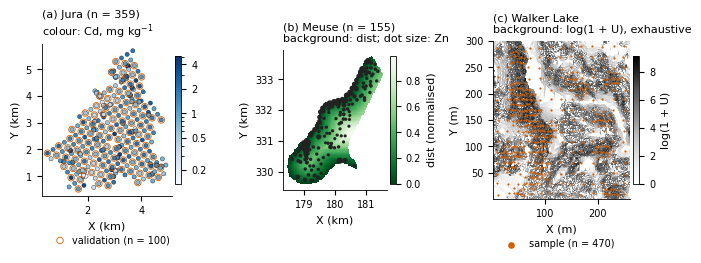

saved: Fig2_datasets


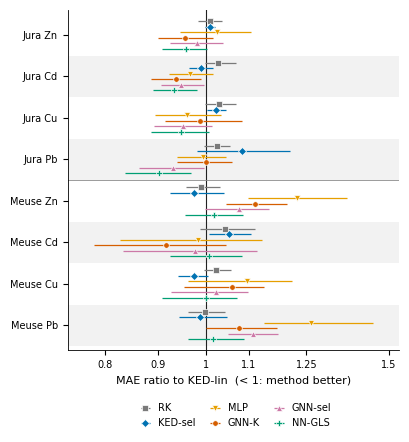

saved: Fig3_forest_real_data


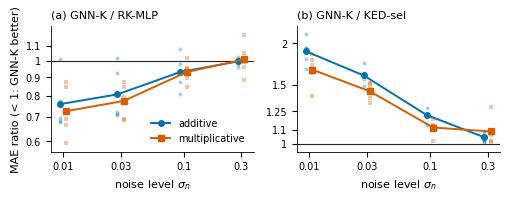

saved: Fig5_noise_dose


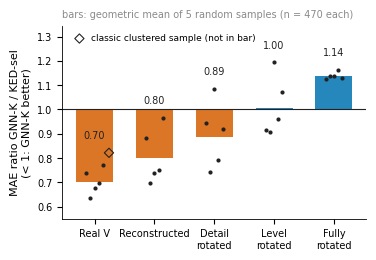

saved: Fig6_walker_lake_conditions
Fig 7 robustness (random samples), ratio by quartile: {1: 0.78, 2: 0.889, 3: 0.754, 4: 0.621}


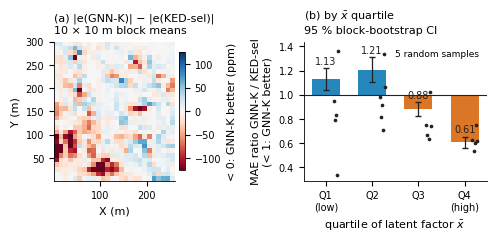

saved: Fig7_walker_lake_error_map


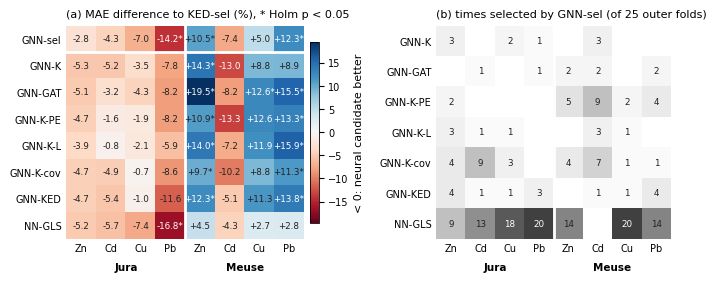

saved: Fig4_h9_heatmap
Figures: ['Fig2_datasets.pdf', 'Fig2_datasets.png', 'Fig3_data.csv', 'Fig3_forest_real_data.pdf', 'Fig3_forest_real_data.png', 'Fig4_data.csv', 'Fig4_h9_heatmap.pdf', 'Fig4_h9_heatmap.png', 'Fig5_noise_dose.pdf', 'Fig5_noise_dose.png', 'Fig6_data.csv', 'Fig6_walker_lake_conditions.pdf', 'Fig6_walker_lake_conditions.png', 'Fig7_data.csv', 'Fig7_reps_data.csv', 'Fig7_walker_lake_error_map.pdf', 'Fig7_walker_lake_error_map.png']


In [75]:
# CELL 74 — Paper figures (Figures 2–7) — from saved results only
import os, json, glob, re, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LogNorm
from scipy.ndimage import gaussian_filter
from scipy.stats import wilcoxon

FIG_DIR = os.path.join(ROOT, "figures", "paper_v2"); os.makedirs(FIG_DIR, exist_ok=True)
SEED = 42; N_FOLDS = 5; T4 = ["Zn", "Cd", "Cu", "Pb"]
MM = 1 / 25.4; W1, W2 = 84 * MM, 174 * MM                     # Springer single / double column
mpl.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
                     "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "savefig.dpi": 600})
# Categorical colours (Okabe–Ito subset; colour-blind check done; marker shape as a second encoding everywhere)
STYLE = {"RK": ("#7a7a7a", "s"), "KED-sel": ("#0072B2", "D"), "MLP": ("#E69F00", "v"),
         "GNN-K": ("#D55E00", "o"), "GNN-sel": ("#CC79A7", "^"), "NN-GLS": ("#009E73", "P")}
INK, MUTED = "#222222", "#8a8a8a"

def savefig(fig, name):
    for ext in ("pdf", "png"): fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), bbox_inches="tight")
    plt.show(); plt.close(fig); print("saved:", name)

def gm(x): x = np.asarray(x, float); return float(np.exp(np.log(x).mean()))

def log_ticks(a, vals, axis="y"):
    """Readable ticks on a log axis within the data range only (1 always included)."""
    lo, hi = np.nanmin(vals), np.nanmax(vals); lo, hi = min(lo, 1) / 1.06, max(hi, 1) * 1.06
    cand = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.25, 1.5, 2, 3, 4, 5]
    tk = [c for c in cand if lo <= c <= hi]
    if len(tk) > 7: tk = [c for c in tk if c in (0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2, 3, 5)]
    lim, setter = (a.set_ylim, a.set_yticks) if axis == "y" else (a.set_xlim, a.set_xticks)
    lim(lo, hi); setter(tk); setter([], minor=True)
    ax_ = a.yaxis if axis == "y" else a.xaxis
    ax_.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))

# ---------- data ----------
P_JURA = pd.read_csv(os.path.join(ROOT, "data", "jura_all.csv"))
try:
    import pyreadr
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyreadr"], check=True); import pyreadr
P_MR = pyreadr.read_r(os.path.join(ROOT, "data", "meuse.rda"))["meuse"].reset_index(drop=True)
P_MEUSE = pd.DataFrame({"X": P_MR.x / 1000.0, "Y": P_MR.y / 1000.0, "Zn": P_MR.zinc, "Cd": P_MR.cadmium, "Cu": P_MR.copper, "Pb": P_MR.lead,
                      "dist": P_MR.dist}); P_MEUSE["id"] = np.arange(len(P_MEUSE))
P_MG = pyreadr.read_r(os.path.join(ROOT, "data", "meuse.grid.rda"))["meuse.grid"]
P_WLS = pd.read_csv(gd.fetch("walker-lake", "sample.csv")); P_EWL = pd.read_csv(gd.fetch("walker-lake", "exhaustive.csv"))
P_ISS = pd.MultiIndex.from_frame(P_EWL[["X", "Y"]]).isin(pd.MultiIndex.from_frame(P_WLS[["X", "Y"]]))
P_WLTE = P_EWL[~P_ISS].reset_index(drop=True)
DATA = {"Jura": (P_JURA, os.path.join(ROOT, "results"), 1.0), "Meuse": (P_MEUSE, os.path.join(ROOT, "results_meuse"), 0.5)}

def load_sel(res_dir, methods):
    """repcv, 'sel' variant; for every point, the mean absolute error over the 5 repeats (same as point_abs_err in Cell 19)."""
    out = {}
    for m in methods:
        for t in T4:
            fs = sorted(glob.glob(os.path.join(res_dir, f"{m}__sel__{t}__repcv__f*__s{SEED}.csv")))
            if len(fs) < 25: continue
            d = pd.concat([pd.read_csv(f).assign(fold=int(re.search(r"__f(\d+)__", f).group(1))) for f in fs])
            out[(m, t)] = d.assign(ae=(d.pred - d.y).abs())
    return out

def pae(D, m, t): return D[(m, t)].groupby("id").ae.mean()

def block_ratio_ci(ea, eb, xy, block, B=2000, seed=SEED):
    """Spatial block bootstrap 95 % interval for the mean-error ratio mean(ea)/mean(eb)."""
    blk = pd.factorize(pd.Series(list(zip((xy[:, 0] // block).astype(int), (xy[:, 1] // block).astype(int)))))[0]
    nb = blk.max() + 1; sa = np.bincount(blk, ea, nb); sb = np.bincount(blk, eb, nb)
    rng = np.random.default_rng(seed); pick = rng.integers(0, nb, (B, nb))
    r = sa[pick].sum(1) / sb[pick].sum(1)
    return ea.sum() / eb.sum(), *np.quantile(r, [0.025, 0.975]), nb

H9_CANDS = ["GNN-K", "GNN-GAT", "GNN-K-PE", "GNN-K-L", "GNN-K-cov", "GNN-KED", "NN-GLS"]
NEED = sorted(set(["OK", "RK", "KED-lin", "KED-spline", "KED-sel", "MLP", "RK-MLP-v3", "GNN-sel", "Ort"] + H9_CANDS))
RES = {k: load_sel(v[1], NEED) for k, v in DATA.items()}
print({k: len(v) for k, v in RES.items()}, "method×target loaded")

# ---------- Figure 2: data settings ----------
def fig2():
    fig, ax = plt.subplots(1, 3, figsize=(W2, 0.36 * W2), gridspec_kw={"width_ratios": [1, 0.8, 1.05]})
    a = ax[0]; cal = P_JURA.set == "cal"
    sc = a.scatter(P_JURA.X, P_JURA.Y, c=P_JURA.Cd, cmap="Blues", norm=LogNorm(), s=9, lw=0.3, ec=INK, zorder=3)
    a.scatter(P_JURA.X[~cal], P_JURA.Y[~cal], s=22, facecolors="none", ec="#D55E00", lw=0.6, zorder=4, label="validation (n = 100)")
    a.set_title("(a) Jura (n = 359)\ncolour: Cd, mg kg$^{-1}$", loc="left")
    a.legend(loc="upper left", bbox_to_anchor=(0, -0.2), frameon=False, handletextpad=0.2)
    cb = fig.colorbar(sc, ax=a, shrink=0.8, pad=0.02); cb.set_ticks([0.2, 0.5, 1, 2, 4]); cb.ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    cb.ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    a = ax[1]
    im = a.scatter(P_MG.x / 1000, P_MG.y / 1000, c=P_MG.dist, cmap="Greens_r", s=1.2, marker="s", lw=0, zorder=1)
    a.scatter(P_MEUSE.X, P_MEUSE.Y, s=4 + 18 * (P_MEUSE.Zn / P_MEUSE.Zn.max()), c="#222222", lw=0, zorder=3)
    a.set_title("(b) Meuse (n = 155)\nbackground: dist; dot size: Zn", loc="left"); fig.colorbar(im, ax=a, shrink=0.8, pad=0.02).set_label("dist (normalised)")
    a = ax[2]; nx, ny = int(P_EWL.X.max()), int(P_EWL.Y.max()); U = np.full((ny, nx), np.nan)
    U[P_EWL.Y.astype(int) - 1, P_EWL.X.astype(int) - 1] = np.log1p(P_EWL.U.values)
    im = a.imshow(U, origin="lower", cmap="Greys", extent=(0.5, nx + 0.5, 0.5, ny + 0.5), interpolation="nearest")
    a.scatter(P_WLS.X, P_WLS.Y, s=2.5, c="#D55E00", lw=0, label="sample (n = 470)")
    a.set_title("(c) Walker Lake\nbackground: log(1 + U), exhaustive", loc="left"); fig.colorbar(im, ax=a, shrink=0.8, pad=0.02).set_label("log(1 + U)")
    a.legend(loc="upper left", bbox_to_anchor=(0, -0.2), frameon=False, markerscale=3)
    for a, u in zip(ax, ("km", "km", "m")):
        a.set_aspect("equal"); a.set_xlabel(f"X ({u})"); a.set_ylabel(f"Y ({u})")
    fig.tight_layout(); savefig(fig, "Fig2_datasets")

# ---------- Figure 3: real-data forest plot (method / KED-lin) ----------
FOREST = ["RK", "KED-sel", "MLP", "GNN-K", "GNN-sel", "NN-GLS"]
def fig3():
    rows = []
    for ds, (df, _, blk) in DATA.items():
        xyall = df.set_index("id")[["X", "Y"]]
        for t in T4:
            if ("KED-lin", t) not in RES[ds]: continue
            eb = pae(RES[ds], "KED-lin", t)
            for m in FOREST:
                if (m, t) not in RES[ds]: continue
                ea = pae(RES[ds], m, t).loc[eb.index]
                r, lo, hi, nb = block_ratio_ci(ea.values, eb.values, xyall.loc[eb.index].values, blk)
                rows.append({"data": ds, "target": t, "method": m, "ratio": r, "lo": lo, "hi": hi, "blocks": nb})
    F = pd.DataFrame(rows); F.to_csv(os.path.join(FIG_DIR, "Fig3_data.csv"), index=False)
    labels = [f"{d} {t}" for d in DATA for t in T4]; ypos = {l: i for i, l in enumerate(labels[::-1])}
    off = np.linspace(-0.33, 0.33, len(FOREST))
    fig, a = plt.subplots(figsize=(W1 * 1.25, W1 * 1.35))
    for i in range(len(labels)):
        if i % 2 == 0: a.axhspan(i - 0.5, i + 0.5, color="#f2f2f2", lw=0, zorder=0)
    a.axhline(3.5, color=MUTED, lw=0.6)
    a.axvline(1, color=INK, lw=0.8, zorder=1)
    for j, m in enumerate(FOREST):
        d = F[F.method == m]; y = np.array([ypos[f"{r.data} {r.target}"] for r in d.itertuples()]) + off[::-1][j]
        c, mk = STYLE[m]
        a.errorbar(d.ratio, y, xerr=[d.ratio - d.lo, d.hi - d.ratio], fmt=mk, ms=4, color=c, mec="white", mew=0.5,
                   elinewidth=0.9, capsize=0, label=m, zorder=3)
    a.set_xscale("log"); log_ticks(a, np.r_[F.lo, F.hi], "x"); a.set_yticks(range(len(labels))); a.set_yticklabels(labels[::-1])
    a.set_xlabel("MAE ratio to KED-lin  (< 1: method better)"); a.set_ylim(-0.6, len(labels) - 0.4)
    a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, handletextpad=0.3, columnspacing=1.0)
    fig.tight_layout(); savefig(fig, "Fig3_forest_real_data"); return F

# ---------- Figure 5: noise dose (H6 + KED-sel) ----------
def fig4():
    p = os.path.join(ROOT, "results_syn6", "syn6_kedsel.csv")
    if not os.path.exists(p): print("Figure 5 skipped: missing →", p); return
    S = pd.read_csv(p); S["r1"] = S["GNN-K"] / S["RK-MLP-v3"]; S["r2"] = S["GNN-K"] / S["KED-sel"]
    fig, ax = plt.subplots(1, 2, figsize=(W2 * 0.75, W2 * 0.3), sharex=True)
    for a, col, ttl in zip(ax, ("r1", "r2"), ("(a) GNN-K / RK-MLP", "(b) GNN-K / KED-sel")):
        a.axhline(1, color=INK, lw=0.8)
        for form, c, mk, lab in (("add", "#0072B2", "o", "additive"), ("mult", "#D55E00", "s", "multiplicative")):
            d = S[S.form == form]; jit = np.where(form == "add", 0.94, 1.06)
            a.scatter(d.noise * jit, d[col], s=8, color=c, alpha=0.35, lw=0, marker=mk)
            g = d.groupby("noise")[col].agg(gm); a.plot(g.index * jit, g.values, "-", marker=mk, ms=4, color=c, lw=1.4, label=lab)
        a.set_xscale("log"); a.set_yscale("log"); a.set_title(ttl, loc="left"); a.set_xlabel(r"noise level $\sigma_n$")
        a.set_xticks(sorted(S.noise.unique())); a.get_xaxis().set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        a.set_xticks([], minor=True); log_ticks(a, S[col].values, "y")
    ax[0].set_ylabel("MAE ratio (< 1: GNN-K better)"); ax[0].legend(frameon=False)
    fig.tight_layout(); savefig(fig, "Fig5_noise_dose")

# ---------- Figure 6: WL conditions, GNN-K / KED-sel ----------
def fig5():
    rows = []
    for r in range(0, 6):                                                   # real V: classic + 5 random samples
        d = os.path.join(ROOT, "results_wl" if r == 0 else f"results_wl_rep{r}")
        if not all(os.path.exists(os.path.join(d, f"{m}.csv")) for m in ("GNN-K", "KED-sel")): continue
        if r == 0: y = P_WLTE.V.values
        else:
            idx = np.random.default_rng(100 + r).choice(len(P_EWL), 470, replace=False); msk = np.zeros(len(P_EWL), bool); msk[idx] = True
            y = P_EWL[~msk].V.values
        e = {m: np.mean(np.abs(pd.read_csv(os.path.join(d, f"{m}.csv")).pred.values - y)) for m in ("GNN-K", "KED-sel")}
        rows.append({"condition": "real", "rep": r, "ratio": e["GNN-K"] / e["KED-sel"]})
    p = os.path.join(ROOT, "results_h7", "h8_summary.csv")
    if os.path.exists(p):
        S8 = pd.read_csv(p).rename(columns={"koşul": "condition", "seçilen": "selected"})   # accepts summaries written by the Turkish v10
        rows += [{"condition": c, "rep": r, "ratio": g / k} for c, r, g, k in S8[["condition", "rep", "GNN-K", "KED-sel"]].values]
    F = pd.DataFrame(rows); F.to_csv(os.path.join(FIG_DIR, "Fig6_data.csv"), index=False)
    order = [("real", "Real V"), ("yeniden", "Reconstructed"), ("ayrıntı-döndürülmüş", "Detail\nrotated"),
             ("düzey-döndürülmüş", "Level\nrotated"), ("döndürülmüş", "Fully\nrotated")]
    order = [o for o in order if (F.condition == o[0]).any()]
    fig, a = plt.subplots(figsize=(W1 * 1.15, W1 * 0.8))
    R5 = F[F.rep.between(1, 5)]                                             # bars: the same 5 random samples in every condition
    for i, (k, lab) in enumerate(order):
        v = R5[R5.condition == k].ratio.values; g = gm(v)
        a.bar(i, g - 1, bottom=1, width=0.62, color="#D55E00" if g < 1 else "#0072B2", alpha=0.85, lw=0)
        a.scatter(i + np.linspace(-0.14, 0.14, len(v)), v, s=9, color=INK, zorder=3, lw=0)
        c0 = F[(F.condition == k) & (F.rep == 0)].ratio.values
        a.text(i, max([g, v.max()] + list(c0)) + 0.05, f"{g:.2f}", ha="center", va="bottom", fontsize=7, color=INK)               # classic (clustered) sample: shown, not averaged
        if len(c0): a.scatter([i + 0.24], c0, s=22, marker="D", facecolors="none", edgecolors=INK, lw=0.8, zorder=4,
                              label="classic clustered sample (not in bar)")
    a.axhline(1, color=INK, lw=0.8)
    a.set_xticks(range(len(order))); a.set_xticklabels([o[1] for o in order])
    a.set_ylabel("MAE ratio GNN-K / KED-sel\n(< 1: GNN-K better)"); a.set_ylim(min(0.55, F.ratio.min() - 0.05), F.ratio.max() + 0.15)
    if (F.rep == 0).any(): a.legend(loc="upper left", frameon=False, fontsize=6.5, handletextpad=0.3)
    a.set_title("bars: geometric mean of 5 random samples (n = 470 each)", loc="left", fontsize=7, color=MUTED)
    fig.tight_layout(); savefig(fig, "Fig6_walker_lake_conditions"); return F

# ---------- Figure 7: WL error-difference map + x̄ quartiles ----------
def build_xbar(E):                                                          # identical to Cell 58
    nx, ny = int(E.X.max()), int(E.Y.max()); ix, iy = E.X.values.astype(int) - 1, E.Y.values.astype(int) - 1
    xb = np.full((nx, ny), np.nan); ok = E.U.values > 2
    xb[ix[ok], iy[ok]] = (10 * E.V / np.log(E.U + 1)).values[ok]
    xb = np.minimum(xb, np.nanquantile(xb, 0.995)); W = np.isfinite(xb).astype(float); X0 = np.nan_to_num(xb)
    XF = np.where(W > 0, xb, gaussian_filter(X0, 3) / np.maximum(gaussian_filter(W, 3), 1e-9))
    for s_ in (6, 12):
        miss = ~np.isfinite(XF) | (gaussian_filter(W, 3) < 1e-6)
        XF = np.where(miss, gaussian_filter(X0, s_) / np.maximum(gaussian_filter(W, s_), 1e-9), XF)
    return XF, ix, iy
def fig6(ref="KED-sel"):
    d = os.path.join(ROOT, "results_wl")
    if not all(os.path.exists(os.path.join(d, f"{m}.csv")) for m in ("GNN-K", ref)): print("Figure 7 skipped: WL predictions missing"); return
    y = P_WLTE.V.values; eg = np.abs(pd.read_csv(os.path.join(d, "GNN-K.csv")).pred.values - y)
    ek = np.abs(pd.read_csv(os.path.join(d, f"{ref}.csv")).pred.values - y); D = eg - ek
    bx, by = ((P_WLTE.X - 1) // 10).astype(int), ((P_WLTE.Y - 1) // 10).astype(int)
    B = pd.DataFrame({"bx": bx, "by": by, "d": D}).groupby(["bx", "by"]).d.mean()
    M = np.full((by.max() + 1, bx.max() + 1), np.nan); M[B.index.get_level_values(1), B.index.get_level_values(0)] = B.values
    XB, ix, iy = build_xbar(P_EWL); xb = XB[ix, iy][~P_ISS]
    q = pd.qcut(xb, 4, labels=["Q1\n(low)", "Q2", "Q3", "Q4\n(high)"])
    fig, ax = plt.subplots(1, 2, figsize=(W2 * 0.8, W2 * 0.36), gridspec_kw={"width_ratios": [1.15, 1]})
    lim = np.nanquantile(np.abs(M), 0.98)
    im = ax[0].imshow(M, origin="lower", cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim), extent=(0.5, 260.5, 0.5, 300.5), interpolation="nearest")
    ax[0].set_aspect("equal"); ax[0].set_xlabel("X (m)"); ax[0].set_ylabel("Y (m)")
    ax[0].set_title(f"(a) |e(GNN-K)| − |e({ref})|\n10 × 10 m block means", loc="left")
    cb = fig.colorbar(im, ax=ax[0], shrink=0.85, pad=0.02); cb.set_label("< 0: GNN-K better (ppm)")
    a = ax[1]; rng = np.random.default_rng(SEED); a.axhline(1, color=INK, lw=0.8)
    blk = pd.factorize(pd.Series(list(zip(bx, by))))[0]; rows6 = []
    for i, lab in enumerate(q.categories):                                  # ratio form: removes the scale effect of higher V in high-x̄ areas
        s = (q == lab).to_numpy() if hasattr(q == lab, "to_numpy") else np.asarray(q == lab)
        b = blk[s]; ub, inv = np.unique(b, return_inverse=True)
        sg, sk = np.bincount(inv, eg[s]), np.bincount(inv, ek[s]); pk = rng.integers(0, len(ub), (2000, len(ub)))
        r = eg[s].mean() / ek[s].mean(); lo, hi = np.quantile(sg[pk].sum(1) / sk[pk].sum(1), [0.025, 0.975])
        a.bar(i, r - 1, bottom=1, width=0.6, color="#D55E00" if r < 1 else "#0072B2", alpha=0.85, lw=0)
        a.errorbar(i, r, yerr=[[r - lo], [hi - r]], color=INK, lw=0.9, capsize=2)
        a.text(i, max(r, hi) + 0.02, f"{r:.2f}", ha="center", va="bottom", fontsize=7, color=INK)
        rows6.append({"quartile": str(lab).replace("\n", " "), "xbar_min": float(xb[s].min()), "xbar_max": float(xb[s].max()), "n": int(s.sum()),
                      "MAE_GNN-K": eg[s].mean(), f"MAE_{ref}": ek[s].mean(), "ratio": r, "lo": lo, "hi": hi, "diff_ppm": eg[s].mean() - ek[s].mean()})
    pd.DataFrame(rows6).to_csv(os.path.join(FIG_DIR, "Fig7_data.csv"), index=False)
    Q6 = pd.DataFrame(rows6); rr = []                                       # robustness: the same quartile ratios on the 5 random samples
    xb_all = XB[ix, iy]
    for r_ in range(1, 6):
        d_ = os.path.join(ROOT, f"results_wl_rep{r_}")
        if not all(os.path.exists(os.path.join(d_, f"{m}.csv")) for m in ("GNN-K", ref)): continue
        idx = np.random.default_rng(100 + r_).choice(len(P_EWL), 470, replace=False); te = np.ones(len(P_EWL), bool); te[idx] = False
        y_ = P_EWL.V.values[te]; g_ = np.abs(pd.read_csv(os.path.join(d_, "GNN-K.csv")).pred.values - y_)
        k_ = np.abs(pd.read_csv(os.path.join(d_, f"{ref}.csv")).pred.values - y_); q_ = pd.qcut(xb_all[te], 4, labels=False)
        for j in range(4): rr.append({"rep": r_, "quartile": j + 1, "ratio": g_[q_ == j].mean() / k_[q_ == j].mean()})
    if rr:
        RR = pd.DataFrame(rr); RR.to_csv(os.path.join(FIG_DIR, "Fig7_reps_data.csv"), index=False)
        for j in range(4):
            v_ = RR[RR.quartile == j + 1].ratio.values
            a.scatter(j + 0.22 + np.linspace(-0.05, 0.05, len(v_)), v_, s=7, color=INK, zorder=4, lw=0,
                      label="5 random samples" if j == 0 else None)
        a.legend(loc="upper right", frameon=False, fontsize=6.5, handletextpad=0.2)
        print("Fig 7 robustness (random samples), ratio by quartile:", RR.groupby("quartile").ratio.agg(gm).round(3).to_dict())
    lo_ = min(Q6.lo.min(), RR.ratio.min() if rr else 1, 1); hi_ = max(Q6.hi.max(), RR.ratio.max() if rr else 1, 1)
    a.set_ylim(lo_ - 0.05, hi_ + 0.08)
    a.set_xticks(range(4)); a.set_xticklabels(q.categories); a.set_xlabel(r"quartile of latent factor $\bar{x}$")
    a.set_ylabel(f"MAE ratio GNN-K / {ref}\n(< 1: GNN-K better)"); a.set_title("(b) by $\\bar{x}$ quartile\n95 % block-bootstrap CI", loc="left")
    fig.tight_layout(); savefig(fig, "Fig7_walker_lake_error_map")

# ---------- Figure 4: H9 heat map + selection frequency ----------
def _holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o])); return adj
def fig7():
    rows = []
    for ds in DATA:
        for t in T4:
            if ("KED-sel", t) not in RES[ds]: continue
            eb = pae(RES[ds], "KED-sel", t)
            for m in ["GNN-sel"] + H9_CANDS:
                if (m, t) not in RES[ds]: continue
                ea = pae(RES[ds], m, t).loc[eb.index]; _, p = wilcoxon(ea.values, eb.values)
                rows.append({"col": f"{ds}\n{t}", "A": m, "pct": 100 * (ea.mean() / eb.mean() - 1), "p": p})
    H = pd.DataFrame(rows)
    if H.empty: print("Figure 4 skipped: H9 results missing"); return
    H["p_holm"] = np.nan                                                    # Cell 72 families: GNN-sel (8 tests), candidates (56 tests)
    for fam in (H.A == "GNN-sel", H.A != "GNN-sel"): H.loc[fam, "p_holm"] = _holm(H.loc[fam, "p"])
    H.to_csv(os.path.join(FIG_DIR, "Fig4_data.csv"), index=False)
    cols = [f"{d}\n{t}" for d in DATA for t in T4]; xl = [t for d in DATA for t in T4]; rws = ["GNN-sel"] + H9_CANDS
    P = H.pivot(index="A", columns="col", values="pct").reindex(index=rws, columns=cols)
    Q = H.pivot(index="A", columns="col", values="p_holm").reindex(index=rws, columns=cols)
    # selection frequency (candidate chosen by GNN-sel in the 25 outer folds)
    C = pd.DataFrame(0, index=H9_CANDS, columns=cols)
    for ds, (_, rd, _) in DATA.items():
        for t in T4:
            for f in range(25):
                j = os.path.join(rd, f"GNN-sel__sel__{t}__repcv__f{f}__s{SEED}.json")
                if os.path.exists(j): C.loc[json.load(open(j))["chosen"], f"{ds}\n{t}"] += 1
    fig, ax = plt.subplots(1, 2, figsize=(W2, W2 * 0.42), gridspec_kw={"width_ratios": [1, 0.82]})
    lim = max(5, np.nanmax(np.abs(P.values)))
    im = ax[0].imshow(P.values, cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            v = P.values[i, j]
            if np.isfinite(v):
                ax[0].text(j, i, f"{v:+.1f}{'*' if Q.values[i, j] < 0.05 else ''}", ha="center", va="center", fontsize=6.3,
                           color="white" if abs(v) > 0.6 * lim else INK)
    ax[0].axhline(0.5, color="white", lw=2); ax[0].axvline(3.5, color="white", lw=2)
    ax[0].set_xticks(range(len(cols))); ax[0].set_xticklabels(xl); ax[0].set_yticks(range(len(rws))); ax[0].set_yticklabels(rws)
    ax[0].set_title("(a) MAE difference to KED-sel (%), * Holm p < 0.05", loc="left")
    cb = fig.colorbar(im, ax=ax[0], shrink=0.85, pad=0.02); cb.set_label("< 0: neural candidate better")
    im2 = ax[1].imshow(C.values, cmap="Greys", vmin=0, vmax=25, aspect="auto")
    for i in range(C.shape[0]):
        for j in range(C.shape[1]):
            if C.values[i, j]: ax[1].text(j, i, C.values[i, j], ha="center", va="center", fontsize=6.3, color="white" if C.values[i, j] > 14 else INK)
    ax[1].axvline(3.5, color="white", lw=2)
    ax[1].set_xticks(range(len(cols))); ax[1].set_xticklabels(xl); ax[1].set_yticks(range(len(H9_CANDS))); ax[1].set_yticklabels(H9_CANDS)
    ax[1].set_title("(b) times selected by GNN-sel (of 25 outer folds)", loc="left")
    for a in ax:
        a.spines[:].set_visible(False); a.tick_params(length=0)
        for k, d in enumerate(DATA): a.text(1.5 + 4 * k, -0.11, d, ha="center", va="top", fontsize=7.5, fontweight="bold", transform=mpl.transforms.blended_transform_factory(a.transData, a.transAxes))
    fig.tight_layout(); savefig(fig, "Fig4_h9_heatmap"); return H

for _f in (fig2, fig3, fig4, fig5, fig6, fig7):
    try: _f()
    except Exception as _e: print(f"{_f.__name__} ERROR: {type(_e).__name__}: {_e}")
print("Figures:", sorted(os.listdir(FIG_DIR)))

In [76]:
# CELL 75 — Table 3 + repository and Zenodo export (NO NEW COMPUTATION)
import hashlib, shutil, platform, importlib
TAB_DIR = os.path.join(ROOT, "tables", "paper_v2"); os.makedirs(TAB_DIR, exist_ok=True)
EXP = os.path.join(ROOT, "export", "repo_v1"); os.makedirs(os.path.join(EXP, "results"), exist_ok=True)
# The slow steps (re-reading ~7 200 fold files from Drive, zipping ~280 MB) run only when their output is missing or when forced.
# Results do not change between runs of Stage 6, so after the first run Table 3, figures, tables, summaries and the manifest refresh in ~1 min.
REBUILD_FOLD_EXPORT = False      # True → rebuild (a) and (b)
REBUILD_ZENODO      = False      # True → rebuild (e)

def per_rep_mae(d):
    d = d.assign(rep=d.fold // N_FOLDS); v = d.groupby("rep").apply(lambda h: np.mean(np.abs(h.pred - h.y)), include_groups=False)
    return v.mean(), v.std(ddof=1)
T3_METHODS = ["OK", "RK", "KED-lin", "KED-spline", "KED-sel", "MLP", "RK-MLP-v3"] + H9_CANDS + ["GNN-sel", "Ort"]
rows = []
for ds in DATA:
    for m in T3_METHODS:
        r = {"data": ds, "method": m}
        for t in T4:
            if (m, t) in RES[ds]: mu, sd = per_rep_mae(RES[ds][(m, t)]); r[t] = mu; r[t + "_sd"] = sd
        rows.append(r)
T3 = pd.DataFrame(rows); T3.to_csv(os.path.join(TAB_DIR, "Table3_real_data_MAE.csv"), index=False)
_fmt = T3[["data", "method"]].copy()
for t in T4:
    if t in T3: _fmt[t] = [f"{a:.3f} ({b:.3f})" if pd.notna(a) else "–" for a, b in zip(T3[t], T3[t + "_sd"])]
try: _fmt.to_latex(os.path.join(TAB_DIR, "Table3_real_data_MAE.tex"), index=False)
except Exception as e: print("LaTeX not written (", e, ") — the CSV is sufficient")
print(_fmt.to_string(index=False))

# (a) Tidy results for the repository: fold-level predictions (all variants) + selection metadata
for ds, (df, rd, _) in DATA.items():
    if not REBUILD_FOLD_EXPORT and os.path.exists(os.path.join(EXP, "results", f"{ds.lower()}_fold_predictions.csv.gz")):
        print(ds, "fold export exists — skipped (set REBUILD_FOLD_EXPORT = True to rebuild)"); continue
    fr, meta = [], []
    for f in sorted(glob.glob(os.path.join(rd, "*__*__*__*__f*__s*.csv"))):
        m, v, t, sch, fid, s = os.path.basename(f)[:-4].split("__")
        fr.append(pd.read_csv(f).assign(method=m, variant=v, target=t, scheme=sch, fold=int(fid[1:])))
        j = f[:-4] + ".json"
        if os.path.exists(j): meta.append({"method": m, "variant": v, "target": t, "scheme": sch, "fold": int(fid[1:]), "meta": open(j).read()})
    if fr:
        pd.concat(fr, ignore_index=True).to_csv(os.path.join(EXP, "results", f"{ds.lower()}_fold_predictions.csv.gz"), index=False)
        pd.DataFrame(meta).to_csv(os.path.join(EXP, "results", f"{ds.lower()}_selection_meta.csv.gz"), index=False)
        print(ds, len(fr), "fold files →", f"{ds.lower()}_fold_predictions.csv.gz")
# (b) WL classic split: test predictions of all methods in one table (source of Figure 7)
_d = os.path.join(ROOT, "results_wl")
if os.path.isdir(_d) and (REBUILD_FOLD_EXPORT or not os.path.exists(os.path.join(EXP, "results", "walker_lake_classic_predictions.csv.gz"))):
    W = P_WLTE[["X", "Y", "U", "V"]].copy()
    for f in sorted(glob.glob(os.path.join(_d, "*.csv"))):
        p = pd.read_csv(f)
        if "pred" in p and len(p) == len(W): W[os.path.basename(f)[:-4]] = p.pred.values
    W.to_csv(os.path.join(EXP, "results", "walker_lake_classic_predictions.csv.gz"), index=False)
# (c) Summary tables and tests
COLMAP = {"örnek": "sample", "koşul": "condition", "seçilen": "selected", "veri": "data", "hedef": "target", "fark_%": "diff_%",
          "A daha iyi": "A_better", "hücre": "cell", "ME KED-log": "ME KED-log", "mlp_res_uzamsal_pay": "mlp_res_spatial_share"}
for p in ["h4_wl_summary.csv", "h4e_wl_summary.csv", "h5_wl_summary.csv", "h6_wl_summary.csv", "h9_tests.csv", "h9_4_tests.csv",
          "results_syn3/syn3_summary.csv", "results_syn5/syn5_summary.csv", "results_syn6/syn6_summary.csv",
          "results_syn6/syn6_kedsel.csv", "results_h7/h7_summary.csv", "results_h7/h8_summary.csv"]:
    src = os.path.join(ROOT, p)
    if os.path.exists(src):                       # column names of summaries written by the Turkish v10 are mapped to English
        d_ = pd.read_csv(src); d_.rename(columns={k: v for k, v in COLMAP.items() if k in d_.columns}).to_csv(os.path.join(EXP, "results", os.path.basename(p)), index=False)
for sub in ("folds",):
    if os.path.isdir(os.path.join(ROOT, sub)): shutil.copytree(os.path.join(ROOT, sub), os.path.join(EXP, sub), dirs_exist_ok=True)
for sub, dst in ((FIG_DIR, "figures"), (TAB_DIR, "tables")): shutil.copytree(sub, os.path.join(EXP, dst), dirs_exist_ok=True)
# (d) Manifest: SHA-256 + environment
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for b in iter(lambda: fh.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
vers = {}
for pk in ("numpy", "pandas", "scipy", "sklearn", "torch", "matplotlib", "pykrige", "geostats_datasets", "joblib", "pyreadr"):
    try: vers[pk] = importlib.import_module(pk).__version__
    except Exception: vers[pk] = None
files = {os.path.relpath(p, EXP): {"sha256": sha(p), "bytes": os.path.getsize(p)}
         for p in sorted(glob.glob(os.path.join(EXP, "**", "*"), recursive=True)) if os.path.isfile(p) and not p.endswith("manifest.json")}
json.dump({"created": pd.Timestamp.now().isoformat(timespec="seconds"), "python": platform.python_version(), "packages": vers,
           "seed": SEED, "files": files}, open(os.path.join(EXP, "manifest.json"), "w"), indent=1, ensure_ascii=False)
print(f"Repository export: {len(files)} files, {sum(v['bytes'] for v in files.values()) / 1e6:.1f} MB → {EXP}")
# (e) Zenodo: all raw result folders in one archive (data files EXCLUDED — licensing; data are downloaded from their sources)
z = os.path.join(ROOT, "export", "zenodo_raw_results_v1.zip")
if REBUILD_ZENODO or not os.path.exists(z):
    _tmp = os.path.join("/content" if os.path.isdir("/content") else ROOT, "zenodo_stage")
    shutil.rmtree(_tmp, ignore_errors=True); os.makedirs(_tmp)
    for d in sorted(os.listdir(ROOT)):
        if d.startswith("results") or d == "folds" or (d.endswith(".csv") and os.path.isfile(os.path.join(ROOT, d))):
            s = os.path.join(ROOT, d); (shutil.copytree if os.path.isdir(s) else shutil.copy)(s, os.path.join(_tmp, d))
    z = shutil.make_archive(z[:-4], "zip", _tmp); shutil.rmtree(_tmp, ignore_errors=True)
    print(f"Zenodo archive: {z} ({os.path.getsize(z) / 1e6:.0f} MB)")
else:
    print(f"Zenodo archive exists — skipped ({os.path.getsize(z) / 1e6:.0f} MB; set REBUILD_ZENODO = True to rebuild)")

 data     method               Zn            Cd             Cu             Pb
 Jura         OK   17.364 (0.180) 0.562 (0.009) 11.971 (0.195) 17.042 (0.312)
 Jura         RK    8.543 (0.094) 0.401 (0.007)  6.235 (0.175) 10.349 (0.186)
 Jura    KED-lin    8.467 (0.116) 0.390 (0.006)  6.059 (0.171) 10.094 (0.256)
 Jura KED-spline    8.976 (0.239) 0.381 (0.014)  6.732 (0.296) 11.081 (0.678)
 Jura    KED-sel    8.544 (0.090) 0.385 (0.009)  6.201 (0.290) 10.941 (0.742)
 Jura        MLP    8.680 (0.103) 0.376 (0.006)  5.815 (0.110) 10.031 (0.409)
 Jura  RK-MLP-v3    8.388 (0.263) 0.379 (0.008)  5.954 (0.150) 10.086 (0.451)
 Jura      GNN-K    8.088 (0.066) 0.365 (0.016)  5.986 (0.247) 10.091 (0.282)
 Jura    GNN-GAT    8.105 (0.223) 0.373 (0.011)  5.935 (0.262) 10.044 (0.445)
 Jura   GNN-K-PE    8.142 (0.118) 0.379 (0.012)  6.086 (0.139) 10.044 (0.255)
 Jura    GNN-K-L    8.208 (0.251) 0.382 (0.011)  6.069 (0.180) 10.301 (0.518)
 Jura  GNN-K-cov    8.144 (0.128) 0.367 (0.012)  6.159 (0.224) 1

### Cell 76 (OPTIONAL) — Computational cost measurement
The saved runs did not record run times (the H9 outer folds ran in parallel; file timestamps are not reliable). For the cost table, **one outer fold**
of every method (repcv fold 0, target Zn) is re-run, nested selection included, and the wall-clock time is measured; results go to a separate folder
and the main results are not touched. Total cost ≈ measurement × (25 folds × 4 targets). **Run first (definitions only; every loop in them passes through checkpoints within seconds):**
CELL 1, 2, 3, 4, 5, 7, 8, 9, 14, 15, 54, 60, 67, 70 — then CELL 76. ⏱ ≈ 20–40 min (GNN-K-L is the longest).

In [77]:
# CELL 76 — Computational cost: wall-clock time of one outer fold (optional)
import time, torch
_missing = [n for n in ("make_ok", "make_rk", "make_ked", "make_nn", "make_variant", "H9_SPECS", "use_dataset", "meuse") if n not in globals()]
if _missing:
    raise RuntimeError("CELL 76 needs the definitions of CELL 1, 2, 3, 4, 5, 7, 8, 9, 14, 15, 54, 60, 67, 70 — run those first. Missing: " + ", ".join(_missing))
_TIME_DIR = os.path.join(ROOT, "timing_v1"); os.makedirs(_TIME_DIR, exist_ok=True)
torch.set_num_threads(1)                                  # same threads per worker as in the parallel H9 run
def _time_classic(make, target="Zn", fid=0):
    """Classical method: two variants (raw, log) × (outer fit + 4 inner folds) — the same workload as select_variant."""
    f = FOLDS["repcv"][fid]; t0 = time.perf_counter()
    for lg in (False, True):
        fp = make(lg); fp(jura.loc[f["train"]], jura.loc[f["test"]], target, SEED, f["inner"])
        for inn in f["inner"]: fp(jura.loc[inn["train"]], jura.loc[inn["test"]], target, SEED, None)
    return time.perf_counter() - t0
def _time_nn(fp, target="Zn", fid=0):
    """Neural network: nested selection (grid × inner fold × epoch) + 5-seed outer prediction — the same workload as the saved run."""
    f = FOLDS["repcv"][fid]; t0 = time.perf_counter(); fp(jura.loc[f["train"]], jura.loc[f["test"]], target, SEED, f["inner"])
    return time.perf_counter() - t0
_CLASSIC = {"OK": lambda lg: make_ok(lg), "RK": lambda lg: make_rk("all", lg),
            "KED-lin": lambda lg: make_ked("lin", lg), "KED-spline": lambda lg: make_ked("spline", lg)}
TIM = []
def _time_all(lab):
    for n, mk in _CLASSIC.items(): TIM.append({"data": lab, "method": n, "seconds": _time_classic(mk)}); print(TIM[-1], flush=True)
    for n in ["MLP", "GNN-K"] + list(H9_SPECS):
        fp = make_nn(n) if n in ("MLP", "GNN-K") else make_variant(n)
        TIM.append({"data": lab, "method": n, "seconds": _time_nn(fp)}); print(TIM[-1], flush=True)
with use_dataset(meuse, MEUSE_FOLDS, MEUSE_RES, MEUSE_COV, _ked_drift_meuse):
    _time_all("Meuse")
_time_all("Jura")
TIM = pd.DataFrame(TIM)
TIM["KED-sel_note"] = np.where(TIM.method.str.startswith("KED"), "KED-sel ≈ KED-lin + KED-spline", "")
TIM["est_hours_100_runs"] = TIM.seconds * 25 * 4 / 3600       # 25 outer folds × 4 targets, single core
TIM.to_csv(os.path.join(_TIME_DIR, "timing_one_fold.csv"), index=False); print(TIM.round(2).to_string(index=False))

{'data': 'Meuse', 'method': 'OK', 'seconds': 0.19239814299999125}
{'data': 'Meuse', 'method': 'RK', 'seconds': 0.2803899030000139}
{'data': 'Meuse', 'method': 'KED-lin', 'seconds': 0.36754256099993654}
{'data': 'Meuse', 'method': 'KED-spline', 'seconds': 0.4993440019998161}
{'data': 'Meuse', 'method': 'MLP', 'seconds': 17.750047616000302}
{'data': 'Meuse', 'method': 'GNN-K', 'seconds': 52.605593537000004}
{'data': 'Meuse', 'method': 'GNN-GAT', 'seconds': 59.87217747900013}
{'data': 'Meuse', 'method': 'GNN-K-PE', 'seconds': 49.27003516900004}
{'data': 'Meuse', 'method': 'GNN-K-L', 'seconds': 186.9916310929998}
{'data': 'Meuse', 'method': 'GNN-K-cov', 'seconds': 50.45428376999962}
{'data': 'Meuse', 'method': 'GNN-KED', 'seconds': 51.697404234999794}
{'data': 'Meuse', 'method': 'NN-GLS', 'seconds': 26.887391925999964}
{'data': 'Jura', 'method': 'OK', 'seconds': 0.6729788010002267}
{'data': 'Jura', 'method': 'RK', 'seconds': 1.1452883160000056}
{'data': 'Jura', 'method': 'KED-lin', 'second